# Fire Egress Simulation v4: Tenability and ASET vs RSET (RCF 4th Floor)

v4 keeps the v3 floor, occupants, BFS routing, door throttle, imposed stair split, and cellular fire, and replaces two things:

1. **v3's 2D cellular smoke is replaced by a zone-based two-layer smoke model.** Each space (room, lobby, corridor, stair nook) is a control volume with a hot upper layer and a cool lower layer. The fire plume fills the origin room's ceiling first; smoke then spills through openings into connected zones, limited by the opening size.
2. **"Death on flame contact" is no longer the only harm.** Each zone is checked against standard tenability criteria (layer height, visibility, temperature). That gives each zone an **ASET** (Available Safe Egress Time: when the zone becomes untenable), which is compared with the **RSET** (Required Safe Egress Time: when the last occupant leaves that zone). Margin = ASET minus RSET. A negative margin means people are still in a space after it stops being survivable.

The notebook is built one mechanism at a time, with a validation gate after each:

| Gate | Mechanism | Status |
|---|---|---|
| 1 | Zone definition (areas, heights, volumes, connections) | this build |
| 2 | Single-room filling model, validated against published correlations | pending |
| 3 | Multi-zone smoke spill through openings | pending |
| 4 | Tenability criteria and agent coupling | pending |
| 5 | ASET vs RSET Monte Carlo scenario matrix | pending |
| 6 | Dashboard and GIF | pending |

**Conservative modeling principle (carried over from v3).** Where a modeling choice is uncertain, v4 takes the side less favorable to occupants and says so in a comment and in markdown. No sprinkler suppression is modeled, even though the building is sprinklered: the design question is what happens if the system fails.

**Parameter flags used throughout.**
- `# ESTIMATED, UNVERIFIED`: an input estimated by the author (for example, ceiling heights read from photos), not yet measured.
- `# UNVERIFIED`: a value with no confirmed public source yet. Results that depend on it are provisional.
- Every literature value that is used carries a citation (source plus table, page, or equation number).

## Floor grid (from v3, with one correction)

The grid is copied from v3: 58 x 67 cells at 1 m per cell, cells stored as `(col, row)` for Mesa, north at the top.

**Correction to v3 (stated, not hidden).** In v3 the southwest nook rectangle (rows 46 to 54, cols 18 to 21) is added to the walkable set *before* the bathroom block (rows 46 to 49, cols 14 to 21) is defined. The bathroom block is marked non-walkable, but that only skips adding it; it never removes cells already added. As a result, 16 bathroom cells (rows 46 to 49, cols 18 to 21) were walkable in v3: drawn gray, but agents and fire could enter them. v4 removes every obstacle cell from the walkable set after all fills (`walkable -= dead`). **v2 and v3 therefore ran on 1,145 walkable cells; v4 runs on 1,129.** The effect on v3's egress results is small (the cells are a dead-end pocket off the nook), but it matters for v4 because zone floor areas are counted from the grid.

In [1]:
import mesa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import random
from collections import deque

# === SCALE CONSTANTS (1 m cells) ===
CELL_SIZE_M = 1.0
CELL_AREA_M2 = CELL_SIZE_M ** 2
SECONDS_PER_STEP = 1.0
M2_TO_FT2 = 10.7639          # exact to 4 decimals: 1 m = 3.28084 ft, squared

# === GRID DIMENSIONS (cells) ===
WIDTH = 58    # cols, west -> east
HEIGHT = 67   # rows, north -> south

walkable = set()
exits = set()
spawn400 = set()
spawn401 = set()
dead = set()

def fill(r0, r1, c0, c1, target_set, also_walkable=True):
    # Add rows r0..r1, cols c0..c1 (inclusive) to target_set.
    # Cells stored as (col, row) = (x, y) for Mesa.
    for r in range(r0, r1 + 1):
        for c in range(c0, c1 + 1):
            if 0 <= r < HEIGHT and 0 <= c < WIDTH:
                target_set.add((c, r))
                if also_walkable:
                    walkable.add((c, r))

# Assembly rooms (spawn zones, walkable)
fill(44, 66, 42, 57, spawn400)        # RCF 400 (east, large)
fill(59, 66, 18, 32, spawn401)        # RCF 401 (lower-west)

# Circulation open area (lobby)
fill(44, 58, 22, 41, walkable)

# North corridor to Stair 2 (northwest stair)
fill(20, 43, 30, 34, walkable)
fill(20, 24, 30, 44, walkable)
fill(8, 19, 30, 34, walkable)
fill(8, 12, 18, 31, walkable)

# Southwest nook to Stair 3 (south stair) / bathrooms
fill(46, 54, 18, 21, walkable)

# Exits (stair entries, walkable)
fill(8, 12, 15, 17, exits)            # Stair 2 (northwest)
fill(55, 58, 18, 25, exits)           # Stair 3 (south)

# Non-walkable obstacles
fill(14, 19, 40, 44, dead, also_walkable=False)   # elevators
fill(46, 49, 14, 21, dead, also_walkable=False)   # bathrooms
fill(59, 66, 33, 41, dead, also_walkable=False)   # deadspace between rooms

# v4 CORRECTION: obstacles are never walkable (v3 left 16 bathroom
# cells walkable because the nook fill ran first). See markdown above.
n_overlap = len(walkable & dead)
walkable -= dead

print(f"Obstacle cells removed from walkable (v3 overlap fix): {n_overlap}")
print(f"Walkable cells: {len(walkable)}")
print(f"Exit cells:     {len(exits)}")
print(f"RCF 400 spawn:  {len(spawn400)} cells")
print(f"RCF 401 spawn:  {len(spawn401)} cells")
print(f"Obstacle cells: {len(dead)}")

Obstacle cells removed from walkable (v3 overlap fix): 16
Walkable cells: 1129
Exit cells:     47
RCF 400 spawn:  368 cells
RCF 401 spawn:  120 cells
Obstacle cells: 134


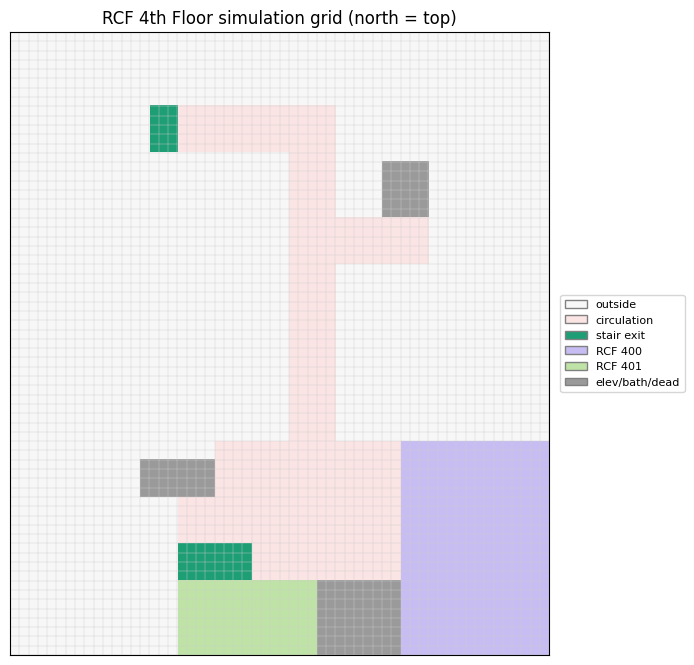

In [2]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def render_floor(occupant_positions=None):
    arr = np.zeros((HEIGHT, WIDTH), dtype=int)
    for (c, r) in walkable:   arr[r][c] = 1
    for (c, r) in spawn400:   arr[r][c] = 3
    for (c, r) in spawn401:   arr[r][c] = 4
    for (c, r) in exits:      arr[r][c] = 2
    for (c, r) in dead:       arr[r][c] = 5
    colors = ['#f7f7f7', '#fbe4e4', '#1d9e75', '#c7bdf2', '#bfe3a6', '#9a9a9a']
    labels = ['outside', 'circulation', 'stair exit', 'RCF 400', 'RCF 401', 'elev/bath/dead']
    fig, ax = plt.subplots(figsize=(7, 8))
    ax.imshow(arr, cmap=ListedColormap(colors), vmin=0, vmax=5,
              origin='upper', interpolation='nearest')
    for x in range(WIDTH + 1):  ax.axvline(x - 0.5, color='#cccccc', linewidth=0.3)
    for y in range(HEIGHT + 1): ax.axhline(y - 0.5, color='#cccccc', linewidth=0.3)
    if occupant_positions:
        ax.scatter([p[0] for p in occupant_positions], [p[1] for p in occupant_positions],
                   s=8, c='#333333', alpha=0.7, zorder=5)
    ax.set_title('RCF 4th Floor simulation grid (north = top)')
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(handles=[Patch(facecolor=colors[i], edgecolor='gray', label=labels[i])
                       for i in range(len(labels))],
              loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)
    plt.tight_layout(); plt.show()

render_floor()

In [3]:
def compute_distance_field(walkable, exits):
    # BFS from all exits. Returns {cell: steps-to-nearest-exit}, routing
    # only through walkable cells. 8-directional, as in v2/v3.
    distance = {}
    queue = deque()
    for cell in exits:
        distance[cell] = 0
        queue.append(cell)
    directions = [(-1,-1),(0,-1),(1,-1),(-1,0),(1,0),(-1,1),(0,1),(1,1)]
    while queue:
        cx, cy = queue.popleft()
        current = distance[(cx, cy)]
        for dx, dy in directions:
            nb = (cx + dx, cy + dy)
            if nb in walkable and nb not in distance:
                distance[nb] = current + 1
                queue.append(nb)
    return distance

distance_field = compute_distance_field(walkable, exits)
print(f"Cells with a path to an exit: {len(distance_field)} / {len(walkable)} walkable")
print(f"Unreachable walkable cells: {len(walkable - set(distance_field))}")
print(f"Max distance to an exit: {max(distance_field.values())} steps")

Cells with a path to an exit: 1129 / 1129 walkable
Unreachable walkable cells: 0
Max distance to an exit: 32 steps


## Design decision: the cellular fire does not set the heat release rate

v3's cellular fire spreads with a measured front speed of about **v = 0.045 m/s**. It is tempting to get the heat release rate (HRR) from it as (burning area) x (heat release rate per unit area, HRRPUA). That would be physically wrong, and the arithmetic shows why.

**The arithmetic.** If the burning region is roughly a disk whose radius grows at speed v, then r = v t and

$$A(t) = \pi (v t)^2, \qquad Q(t) = q''\,A(t) = \underbrace{q''\,\pi v^2}_{\alpha_{eq}}\; t^2$$

So a constant-speed front is itself a t-squared fire, with an equivalent growth coefficient alpha_eq = q'' pi v^2.

**Reference values.**
- **t-squared growth coefficients used throughout v4:** medium alpha = 0.01172, fast 0.0469, ultrafast 0.1876 kW/s^2. These are the NFPA 92B growth classes, defined by the growth time t_g for the fire to reach 1055 kW (1000 Btu/s): medium 300 s, fast 150 s, ultrafast 75 s, so alpha = 1055 / t_g^2. Public US source: Klote, J.H., *Method of Predicting Smoke Movement in Atria With Application to Smoke Management*, NISTIR 5516, NIST, 1994, Section 2.2 and Table 2 (p. 3), https://nvlpubs.nist.gov/nistpubs/Legacy/IR/nistir5516.pdf . Table 2 lists t_g = 300 / 150 / 75 s with alpha = 0.04689 (fast) and 0.1878 (ultrafast), citing NFPA 204 (1991), NFPA 92B (1991), and Nelson (1987). **Discrepancy noted:** Table 2 prints the medium alpha as 0.01127, which is inconsistent with its own definition (1055 / 300^2 = 0.01172). It appears to be a digit transposition; v4 uses 0.01172, which matches the definition and the author's prompt. The printout below recomputes all three from the definition.
- Cross-check only: the EN 1991-1-2 Annex E growth times (75, 150, 300, 600 s) are reproduced on slide 24 of the EU Joint Research Centre Eurocode fire design workshop (Vassart, "Structural Fire Design of Buildings according to the Eurocodes", Brussels, 27-28 Nov 2012), https://eurocodes.jrc.ec.europa.eu/sites/default/files/2022-06/03a-VASSART-EC-FireDesign-WS.pdf . They agree with the NFPA classes to the rounding of the growth time.
- HRRPUA: the same Eurocode source, slide 22, reproduces the EN 1991-1-2 Annex E table of RHR_f (maximum heat release rate per m^2 of floor area, fuel-controlled): **500 kW/m^2 for theatre (movie/cinema)**, the closest occupancy to an assembly room with fixed seating, and **250 kW/m^2 for school and office**. The calculation below is run for both so the conclusion does not hang on which one applies.

**Result (printed below).** With v = 0.045 m/s and q'' = 500 kW/m^2, alpha_eq is about 3.2 kW/s^2, roughly **17 times faster than ultrafast**. Even at 250 kW/m^2 it is about 8.5 times ultrafast. After 5 minutes the implied fire would be hundreds of MW, which no room fire can reach: a fire in a room this size becomes limited by fuel and air long before that.

The emergent check (second half of the printout) runs the actual v3 spread from a central RCF 400 origin. Its equal-area front speed is faster early (about 0.08 m/s at 60 s) and slows toward v3's 0.045 m/s by 300 s as the fire reaches the room walls, so the disk estimate above *understates* the problem in the first minutes.

**Why the mismatch exists.** The cellular fire was calibrated in v3 as a *hazard front*: the region people cannot enter or stand near, sized to the aggressive end of plausible spread so that it conservatively removes egress paths. It was never a burning-area model, so its area should not be multiplied by an HRRPUA.

**The decoupling.**
- The **cellular fire stays** as the flame region. It blocks paths, sets the 1 m radiant standoff, and causes flame-contact casualties, exactly as in v3.
- A separate **t-squared design fire** Q = alpha t^2, capped at 5 MW, drives smoke production in the zone model (Gates 2 to 5).

**Known inconsistency, stated.** The two fire representations are not tied together. A 5 MW fire at 500 kW/m^2 covers only about 10 m^2, while the cellular flame region can grow much larger than that. The cellular region should therefore be read as a conservative *hazard footprint* (flame, radiant exposure, and burning debris that make cells impassable), not as the burning area. This keeps the path-blocking behavior conservative while keeping the smoke source physically plausible.

In [4]:
# ============================================================
# DECOUPLING CHECK: what HRR would the cellular fire imply?
# (1) analytic: disk front at measured v3 speed
# (2) emergent: run the actual v3 cellular spread and multiply its
#     burning area by HRRPUA, to confirm the analytic estimate is not
#     an artifact of the disk assumption.
# ============================================================

# --- t-squared growth coefficients used throughout v4 (kW/s^2) ---
# NFPA 92B classes, reproduced in NISTIR 5516 (Klote 1994) Table 2, p. 3:
# t_g = time to reach 1055 kW (1000 Btu/s); alpha = 1055 / t_g^2.
ALPHA = {"medium": 0.01172, "fast": 0.0469, "ultrafast": 0.1876}
Q_REF_KW = 1055.0                      # 1000 Btu/s reference fire
T_G_NFPA = {"medium": 300.0, "fast": 150.0, "ultrafast": 75.0}   # NISTIR 5516 Table 2
NISTIR5516_TABLE2 = {"medium": 0.01127, "fast": 0.04689, "ultrafast": 0.1878}
print(f"{'class':10} {'alpha used':>10} {'1055/t_g^2':>11} {'NISTIR Tbl2':>11} "
      f"{'t to 1 MW':>10} {'t to 1055 kW':>13}")
for k, a in ALPHA.items():
    print(f"{k:10} {a:10.5f} {Q_REF_KW/T_G_NFPA[k]**2:11.5f} {NISTIR5516_TABLE2[k]:11.5f} "
          f"{math.sqrt(1000/a):9.0f}s {math.sqrt(Q_REF_KW/a):12.0f}s")
print("NOTE: NISTIR 5516 Table 2 prints medium = 0.01127, but its own definition gives "
      f"1055/300^2 = {1055/300**2:.5f}. Treated as a typo; v4 uses 0.01172.")
print()

# --- (1) Analytic ---
V_FRONT = 0.045      # m/s, measured emergent front speed in v3 (README, Calibration)
# HRRPUA: EN 1991-1-2 Annex E RHR_f, reproduced in JRC workshop slide 22:
# theatre (movie/cinema) 500 kW/m^2; school/office 250 kW/m^2.
HRRPUA_CASES = {"theatre 500": 500.0, "school 250": 250.0}

for label, q in HRRPUA_CASES.items():
    a_eq = q * math.pi * V_FRONT**2
    print(f"[{label} kW/m^2] alpha_eq = {q:.0f} * pi * {V_FRONT}^2 = {a_eq:.3f} kW/s^2"
          f"  -> {a_eq/ALPHA['ultrafast']:.1f}x ultrafast")
    for t in (60, 120, 300):
        print(f"      t = {t:3d} s: implied Q = {a_eq*t*t/1000:7.1f} MW"
              f"   vs ultrafast {ALPHA['ultrafast']*t*t/1000:5.2f} MW")
print()

# --- (2) Emergent: the actual v3 cellular spread ---
FIRE_SPREAD_P = 0.017                  # v3 calibrated per-neighbor probability
SPREAD_DIRS = [(-1,-1),(0,-1),(1,-1),(-1,0),(1,0),(-1,1),(0,1),(1,1)]

def spread_step(region, p, rng):
    # One step of probabilistic cellular spread through walkable cells (v3).
    newly = set()
    for (cx, cy) in region:
        for dx, dy in SPREAD_DIRS:
            nb = (cx + dx, cy + dy)
            if nb in walkable and nb not in region and nb not in newly:
                if rng.random() < p:
                    newly.add(nb)
    return region | newly

# Average over several seeds from a central RCF 400 origin, so the
# room walls do not cap growth inside 300 s.
origin_test = (50, 55)
checkpoints = (60, 120, 180, 240, 300)
areas = {t: [] for t in checkpoints}
for seed in range(10):
    rng = random.Random(seed)
    burning = {origin_test}
    for t in range(1, max(checkpoints) + 1):
        burning = spread_step(burning, FIRE_SPREAD_P, rng)
        if t in checkpoints:
            areas[t].append(len(burning) * CELL_AREA_M2)

print("Emergent cellular fire (mean of 10 seeds, origin (50,55) in RCF 400):")
print(f"{'t (s)':>6} {'area m^2':>9} {'disk-eq v m/s':>14} "
      f"{'Q @500 MW':>10} {'Q @250 MW':>10} {'ultrafast MW':>13}")
for t in checkpoints:
    A = np.mean(areas[t])
    v_eq = math.sqrt(A / math.pi) / t     # radius of equal-area disk / time
    print(f"{t:6d} {A:9.0f} {v_eq:14.3f} {A*500/1000:10.1f} {A*250/1000:10.1f}"
          f" {ALPHA['ultrafast']*t*t/1000:13.2f}")

A300 = np.mean(areas[300])
print(f"\nAt 300 s the cellular area implies {A300*500/1000:.0f} MW at 500 kW/m^2,"
      f" i.e. {A300*500/(ALPHA['ultrafast']*300**2):.0f}x an uncapped ultrafast fire"
      f" and {A300*500/5000:.0f}x the 5 MW design cap.")
print(f"A 5 MW fire at 500 kW/m^2 covers only {5000/500:.0f} m^2.")

class      alpha used  1055/t_g^2 NISTIR Tbl2  t to 1 MW  t to 1055 kW
medium        0.01172     0.01172     0.01127       292s          300s
fast          0.04690     0.04689     0.04689       146s          150s
ultrafast     0.18760     0.18756     0.18780        73s           75s
NOTE: NISTIR 5516 Table 2 prints medium = 0.01127, but its own definition gives 1055/300^2 = 0.01172. Treated as a typo; v4 uses 0.01172.

[theatre 500 kW/m^2] alpha_eq = 500 * pi * 0.045^2 = 3.181 kW/s^2  -> 17.0x ultrafast
      t =  60 s: implied Q =    11.5 MW   vs ultrafast  0.68 MW
      t = 120 s: implied Q =    45.8 MW   vs ultrafast  2.70 MW
      t = 300 s: implied Q =   286.3 MW   vs ultrafast 16.88 MW
[school 250 kW/m^2] alpha_eq = 250 * pi * 0.045^2 = 1.590 kW/s^2  -> 8.5x ultrafast
      t =  60 s: implied Q =     5.7 MW   vs ultrafast  0.68 MW
      t = 120 s: implied Q =    22.9 MW   vs ultrafast  2.70 MW
      t = 300 s: implied Q =   143.1 MW   vs ultrafast 16.88 MW



Emergent cellular fire (mean of 10 seeds, origin (50,55) in RCF 400):
 t (s)  area m^2  disk-eq v m/s  Q @500 MW  Q @250 MW  ultrafast MW
    60        73          0.080       36.5       18.3          0.68
   120       282          0.079      141.2       70.6          2.70
   180       440          0.066      220.2      110.1          6.08
   240       546          0.055      272.8      136.4         10.81
   300       684          0.049      342.1      171.0         16.88

At 300 s the cellular area implies 342 MW at 500 kW/m^2, i.e. 20x an uncapped ultrafast fire and 68x the 5 MW design cap.
A 5 MW fire at 500 kW/m^2 covers only 10 m^2.


## Gate 1: Zone definition

A zone model treats each space as one well-mixed control volume: one upper-layer depth, temperature, and soot concentration per zone. The zones follow the v3 grid rectangles, so no walking geometry is redrawn.

| Zone | Grid cells (rows, cols) | Notes |
|---|---|---|
| RCF 400 | rows 44 to 66, cols 42 to 57 | The RCF 400 spawn block |
| RCF 401 | rows 59 to 66, cols 18 to 32 | The RCF 401 spawn block |
| Lobby | rows 44 to 58, cols 22 to 41, minus the Stair 3 exit cells | Circulation, one zone (downstand beams ignored, see below) |
| Corridor + NW nook | rows 8 to 43, cols 30 to 34; elevator stub rows 20 to 24, cols 35 to 44; west jog rows 8 to 12, cols 15 to 29 | Corridor and the NW stair nook, **merged** (see below) |
| S stair nook | rows 50 to 54, cols 18 to 21, plus the Stair 3 exit cells (rows 55 to 58, cols 18 to 25) | The southwest nook (bathroom cells removed) plus the floor in front of the Stair 3 door |

**Why the corridor and NW nook are one zone.** The author's floor plans show the corridor opening into the NW stair nook as an open passage at the same 2.9 m ceiling. With no soffit and no ceiling step between them, nothing holds smoke back at that boundary, so a ceiling layer flows freely from one to the other. Two zones with a zero-height barrier would just be one zone with extra bookkeeping.

**Stair exit cells** belong to their nook for walking and for tenability (they are floor space where occupants queue in front of the stair door).

### Ceiling heights

The author's estimates from photographs, **not verified**. Each is a named parameter flagged `# ESTIMATED, UNVERIFIED`:

| Zone | Ceiling (m) | Basis |
|---|---|---|
| RCF 400 | 4.3 (14 ft) | Open wood slat ceiling clouds hang lower; smoke passes through the open slats and fills to the hard ceiling above, so the hard ceiling is used |
| RCF 401 | 3.7 (12 ft) | Same open slat clouds |
| Lobby | 3.4 (11 ft) | Acoustic tile ceiling with downstand beams near 3.0 m; treated as one zone at the tile height. The beams could briefly hold smoke in bays; ignoring them lets smoke spread across the whole lobby at once |
| Corridor + NW nook, S stair nook | 2.9 (9.5 ft) | No photo; lowest confidence |
| Door soffits | 2.13 (7 ft) | Standard door head height |

### Walking geometry versus smoke geometry

**Walking uses the v3 grid. Smoke uses published floor areas where they exist.** The grid was drawn for egress routing and its room areas do not match the published areas: RCF 400 on the grid is 368 m^2, but HCC publishes 2,998 ft^2 (278.5 m^2). For a filling calculation, a larger floor area means a larger volume to fill and a slower-descending layer, so using the larger grid area would be **non-conservative**. The smoke model therefore uses:

| Zone | Smoke-model area | Source |
|---|---|---|
| RCF 400 | 2,998 ft^2 (278.5 m^2) | HCC naming-opportunities page |
| RCF 401 | 1,369 ft^2 (127.2 m^2) | HCC naming-opportunities page |
| Lobby | 1,370 ft^2 (127.3 m^2) | HCC naming-opportunities page |
| Corridor + NW nook | grid area | no published area |
| S stair nook | grid area | no published area |

Source: https://www.howardcc.edu/donors-alumni-and-friends/support-hcc-students/naming-opportunities/rouse-company-foundation-student-services-hall/

### Smoke connections (openings)

From the author's ENES-250 floor plans. Each width is flagged `# UNVERIFIED (author's ENES-250 floor plans)`. These openings are used **only by the smoke model**; the walking geometry keeps v3's open edges.

| Connection | Opening | Width | Soffit |
|---|---|---|---|
| RCF 400 to lobby | two 66 in double doors | 2 x 1.68 m = 3.35 m | 2.13 m (door head) |
| RCF 401 to lobby | one 66 in double door | 1.68 m | 2.13 m (door head) |
| Lobby to S stair nook | open passage | grid edge length | 2.9 m (nook ceiling) |
| Lobby to corridor + NW nook | open passage | grid edge length | 2.9 m (corridor ceiling) |

- **The 0.5 m ceiling step acts as a small downstand.** The lobby ceiling is 3.4 m and both passages out of it have a 2.9 m soffit. Smoke must fill the top 0.5 m of the lobby before any of it can spill into the corridor or the south nook. That reservoir is small and will fill quickly, but it is the mechanism that delays spill.
- **No smoke connection between RCF 401 and the south stair.** On the grid, RCF 401 touches the Stair 3 exit cells. Physically, the 32 in door on RCF 401's north wall leads into the stair enclosure, not the nook. Exit enclosure doors are self-closing and fire rated, so **both stair doors are treated as closed for smoke: smoke never enters either stair enclosure.** Occupants still walk through those doors exactly as in v3.

In [5]:
# ============================================================
# GATE 1: ZONES
# ============================================================

# --- Ceiling heights (m) -------------------------------------
H_RCF400   = 4.3    # ESTIMATED, UNVERIFIED (photo; hard ceiling above slat clouds)
H_RCF401   = 3.7    # ESTIMATED, UNVERIFIED (photo; hard ceiling above slat clouds)
H_LOBBY    = 3.4    # ESTIMATED, UNVERIFIED (photo; acoustic tile, beams ~3.0 m ignored)
H_CORRIDOR = 2.9    # ESTIMATED, UNVERIFIED (no photo; lowest confidence)
H_NOOK     = 2.9    # ESTIMATED, UNVERIFIED (no photo; lowest confidence)
DOOR_SOFFIT = 2.13  # ESTIMATED, UNVERIFIED (standard 7 ft door head)

def rect(r0, r1, c0, c1):
    # Cells (col, row) in rows r0..r1, cols c0..c1 inclusive.
    return {(c, r) for r in range(r0, r1 + 1) for c in range(c0, c1 + 1)}

Z400, Z401, ZLOB, ZCOR, ZSN = "RCF 400", "RCF 401", "Lobby", "Corridor + NW nook", "S stair nook"

ZONE_CELLS = {
    Z400: set(spawn400),
    Z401: set(spawn401),
    ZLOB: rect(44, 58, 22, 41) - exits,
    # Corridor spine + elevator stub + west jog to Stair 2 (merged zone)
    ZCOR: rect(8, 43, 30, 34) | rect(20, 24, 35, 44) | rect(8, 12, 15, 29),
    ZSN:  rect(50, 54, 18, 21) | rect(55, 58, 18, 25),
}
ZONE_CELLS = {z: cells & walkable for z, cells in ZONE_CELLS.items()}
ZONES = list(ZONE_CELLS)

ZONE_H = {Z400: H_RCF400, Z401: H_RCF401, ZLOB: H_LOBBY, ZCOR: H_CORRIDOR, ZSN: H_NOOK}

# Reverse lookup: cell -> zone (agents use this later).
CELL_ZONE = {}
for z, cells in ZONE_CELLS.items():
    for cell in cells:
        assert cell not in CELL_ZONE, f"cell {cell} in two zones"
        CELL_ZONE[cell] = z

unassigned = walkable - set(CELL_ZONE)
print(f"Walkable cells: {len(walkable)}, assigned to zones: {len(CELL_ZONE)}, "
      f"unassigned: {len(unassigned)}")
assert not unassigned
print(f"Stair 2 exit cells all in '{ZCOR}': {(exits & rect(8,12,15,17)) <= ZONE_CELLS[ZCOR]}")
print(f"Stair 3 exit cells all in '{ZSN}':  {(exits & rect(55,58,18,25)) <= ZONE_CELLS[ZSN]}")

Walkable cells: 1129, assigned to zones: 1129, unassigned: 0
Stair 2 exit cells all in 'Corridor + NW nook': True
Stair 3 exit cells all in 'S stair nook':  True


In [6]:
# --- Smoke-model floor areas -----------------------------------
# Published areas where available (HCC naming-opportunities page);
# grid areas otherwise. Larger area = slower filling, so the smaller
# published areas are the conservative choice for the rooms.
FT2_TO_M2 = 1 / M2_TO_FT2
PUBLISHED_FT2 = {Z400: 2998.0, Z401: 1369.0, ZLOB: 1370.0}   # HCC naming-opportunities page

GRID_AREA_M2 = {z: len(ZONE_CELLS[z]) * CELL_AREA_M2 for z in ZONES}
SMOKE_AREA_M2, SMOKE_AREA_SRC = {}, {}
for z in ZONES:
    if z in PUBLISHED_FT2:
        SMOKE_AREA_M2[z] = PUBLISHED_FT2[z] * FT2_TO_M2
        SMOKE_AREA_SRC[z] = "HCC published"
    else:
        SMOKE_AREA_M2[z] = GRID_AREA_M2[z]
        SMOKE_AREA_SRC[z] = "grid"

rows = []
for z in ZONES:
    A, H = SMOKE_AREA_M2[z], ZONE_H[z]
    rows.append({"zone": z,
                 "grid m^2": GRID_AREA_M2[z],
                 "grid ft^2": round(GRID_AREA_M2[z] * M2_TO_FT2),
                 "smoke m^2": round(A, 1),
                 "smoke ft^2": round(A * M2_TO_FT2),
                 "smoke/grid": round(A / GRID_AREA_M2[z], 2),
                 "area source": SMOKE_AREA_SRC[z],
                 "ceiling m": H,
                 "smoke vol m^3": round(A * H, 1),
                 "A/H^2": round(A / H**2, 1)})
zone_df = pd.DataFrame(rows)
print("ZONES: walking uses grid areas, smoke uses 'smoke' areas")
print("(ceiling heights: ESTIMATED, UNVERIFIED)")
print(zone_df.to_string(index=False))
print(f"\nTotal smoke volume: {zone_df['smoke vol m^3'].sum():,.0f} m^3 "
      f"(grid-area volume would be "
      f"{sum(GRID_AREA_M2[z]*ZONE_H[z] for z in ZONES):,.0f} m^3)")

ZONES: walking uses grid areas, smoke uses 'smoke' areas
(ceiling heights: ESTIMATED, UNVERIFIED)
              zone  grid m^2  grid ft^2  smoke m^2  smoke ft^2  smoke/grid   area source  ceiling m  smoke vol m^3  A/H^2
           RCF 400     368.0       3961      278.5        2998        0.76 HCC published        4.3         1197.7   15.1
           RCF 401     120.0       1292      127.2        1369        1.06 HCC published        3.7          470.6    9.3
             Lobby     284.0       3057      127.3        1370        0.45 HCC published        3.4          432.7   11.0
Corridor + NW nook     305.0       3283      305.0        3283        1.00          grid        2.9          884.5   36.3
      S stair nook      52.0        560       52.0         560        1.00          grid        2.9          150.8    6.2

Total smoke volume: 3,136 m^3 (grid-area volume would be 4,027 m^3)


In [7]:
# --- Grid contacts between zones (walking) ---
# Boundary length = number of shared 4-neighbour cell faces (1 m each).
from collections import defaultdict
GRID_EDGE_M = defaultdict(int)
for (c, r), z in CELL_ZONE.items():
    for dc, dr in ((1, 0), (0, 1)):          # each face counted once
        z2 = CELL_ZONE.get((c + dc, r + dr))
        if z2 is not None and z2 != z:
            GRID_EDGE_M[frozenset((z, z2))] += 1

# --- Smoke openings (smoke model only) ---
DOOR_66IN_M = 66 * 0.0254   # 66 in double door = 1.676 m
OPENINGS = [
    # (zone a, zone b, kind, width_m, soffit_m)
    (Z400, ZLOB, "2 x 66 in double door", 2 * DOOR_66IN_M, DOOR_SOFFIT),   # UNVERIFIED (author's ENES-250 floor plans)
    (Z401, ZLOB, "1 x 66 in double door", 1 * DOOR_66IN_M, DOOR_SOFFIT),   # UNVERIFIED (author's ENES-250 floor plans)
    (ZLOB, ZSN,  "open passage", GRID_EDGE_M[frozenset((ZLOB, ZSN))],
     min(H_LOBBY, H_NOOK)),                                                # UNVERIFIED (author's ENES-250 floor plans)
    (ZLOB, ZCOR, "open passage", GRID_EDGE_M[frozenset((ZLOB, ZCOR))],
     min(H_LOBBY, H_CORRIDOR)),                                            # UNVERIFIED (author's ENES-250 floor plans)
]
# Grid contacts that are walking-only (no smoke path):
WALK_ONLY = {frozenset((Z401, ZSN)): "RCF 401 north-wall door opens into the stair "
             "enclosure; self-closing rated door, closed for smoke"}

rows = []
for a, b, kind, w, s in OPENINGS:
    rows.append({"zone A": a, "zone B": b, "grid edge (m)": GRID_EDGE_M[frozenset((a, b))],
                 "smoke opening": kind, "width (m)": round(w, 2), "soffit (m)": s,
                 "ceiling step (m)": round(max(ZONE_H[a], ZONE_H[b]) - s, 2)})
for pair, why in WALK_ONLY.items():
    a, b = sorted(pair)
    rows.append({"zone A": a, "zone B": b, "grid edge (m)": GRID_EDGE_M[pair],
                 "smoke opening": "NONE (walking only)", "width (m)": 0.0,
                 "soffit (m)": float("nan"), "ceiling step (m)": float("nan")})
conn_df = pd.DataFrame(rows)
print("CONNECTIONS  (opening widths: UNVERIFIED, author's ENES-250 floor plans)")
print(conn_df.to_string(index=False))
print("\nStair enclosure doors: closed for smoke (self-closing, fire rated). "
      "No smoke leaves the floor through either stair.")

# Every grid contact must be either a smoke opening or declared walking-only.
smoke_pairs = {frozenset((a, b)) for a, b, *_ in OPENINGS}
undeclared = set(GRID_EDGE_M) - smoke_pairs - set(WALK_ONLY)
print(f"Grid contacts with no smoke decision: {[sorted(p) for p in undeclared] or 'none'}")
assert not undeclared

CONNECTIONS  (opening widths: UNVERIFIED, author's ENES-250 floor plans)
 zone A             zone B  grid edge (m)         smoke opening  width (m)  soffit (m)  ceiling step (m)
RCF 400              Lobby             15 2 x 66 in double door       3.35        2.13              2.17
RCF 401              Lobby              7 1 x 66 in double door       1.68        2.13              1.57
  Lobby       S stair nook             13          open passage      13.00        2.90              0.50
  Lobby Corridor + NW nook              5          open passage       5.00        2.90              0.50
RCF 401       S stair nook              8   NONE (walking only)       0.00         NaN               NaN

Stair enclosure doors: closed for smoke (self-closing, fire rated). No smoke leaves the floor through either stair.
Grid contacts with no smoke decision: none


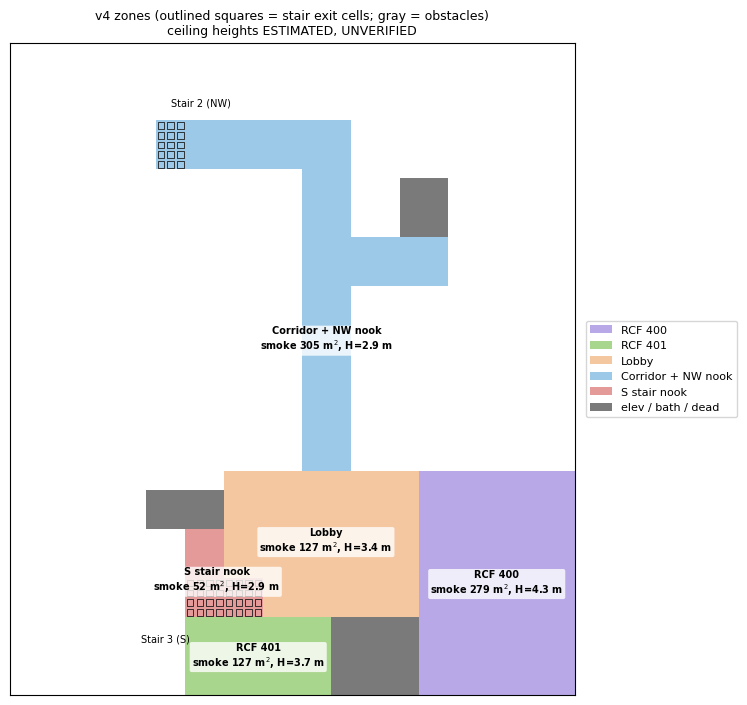

In [8]:
# --- Zone map ---
ZONE_COLORS = {Z400: "#b9a8e8", Z401: "#a8d68c", ZLOB: "#f4c7a1",
               ZCOR: "#9cc9e8", ZSN: "#e59a9a"}
arr = np.zeros((HEIGHT, WIDTH), dtype=int)
for i, z in enumerate(ZONES, start=1):
    for (c, r) in ZONE_CELLS[z]:
        arr[r][c] = i
for (c, r) in dead:
    arr[r][c] = len(ZONES) + 1
cmap_z = ListedColormap(["#ffffff"] + [ZONE_COLORS[z] for z in ZONES] + ["#7a7a7a"])

fig, ax = plt.subplots(figsize=(7.5, 8.5))
ax.imshow(arr, cmap=cmap_z, vmin=0, vmax=len(ZONES) + 1,
          origin="upper", interpolation="nearest")
ex = np.array(sorted(exits))
ax.scatter(ex[:, 0], ex[:, 1], marker="s", s=22, facecolors="none",
           edgecolors="#1b1b1b", linewidths=0.6)
label_at = {ZCOR: (32, 30)}   # put the corridor label on the spine
for z in ZONES:
    cs = np.array(sorted(ZONE_CELLS[z]))
    cx, cy = label_at.get(z, (cs[:, 0].mean(), cs[:, 1].mean()))
    ax.text(cx, cy, f"{z}\nsmoke {SMOKE_AREA_M2[z]:.0f} m$^2$, H={ZONE_H[z]} m",
            ha="center", va="center", fontsize=7, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.text(16, 6, "Stair 2 (NW)", fontsize=7)
ax.text(13, 61, "Stair 3 (S)", fontsize=7)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("v4 zones (outlined squares = stair exit cells; gray = obstacles)\n"
             "ceiling heights ESTIMATED, UNVERIFIED", fontsize=9)
ax.legend(handles=[Patch(facecolor=ZONE_COLORS[z], label=z) for z in ZONES]
                  + [Patch(facecolor="#7a7a7a", label="elev / bath / dead")],
          loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

### Grid areas versus the two occupant-load sources

The occupant-load cases in Gate 5 use their own area sources (Case A: the author's ENES-250 course floor plans; Case B: HCC's published areas). This comparison shows how far the drawn grid sits from each, an input uncertainty carried forward, not hidden.

- HCC multipurpose venues (capacities, cited again in Gate 5): https://howardcc.edu/services--support/event-and-conference-center/multipurpose-venues/

In [9]:
AREA_SOURCES_FT2 = {
    "Case A (course plans)": {Z400: 4556.59, Z401: 1290.38},   # author's ENES-250 floor plans
    "Case B (HCC published)": {Z400: 2998.0, Z401: 1369.0},    # HCC naming-opportunities page
}
print(f"{'room':8} {'grid ft^2':>10} " + " ".join(f"{k:>24}" for k in AREA_SOURCES_FT2))
for room in (Z400, Z401):
    g = GRID_AREA_M2[room] * M2_TO_FT2
    cells = [f"{src[room]:9,.0f} (grid {100*(g-src[room])/src[room]:+5.1f}%)"
             for src in AREA_SOURCES_FT2.values()]
    print(f"{room:8} {g:10,.0f} " + " ".join(f"{c:>24}" for c in cells))
print("\nHCC also lists a 1,443 ft^2 wrap-around balcony; 2,998 + 1,443 = "
      f"{2998+1443:,} ft^2, close to Case A's 4,556.59 ft^2 for RCF 400.")

room      grid ft^2    Case A (course plans)   Case B (HCC published)
RCF 400       3,961      4,557 (grid -13.1%)      2,998 (grid +32.1%)
RCF 401       1,292      1,290 (grid  +0.1%)      1,369 (grid  -5.6%)

HCC also lists a 1,443 ft^2 wrap-around balcony; 2,998 + 1,443 = 4,441 ft^2, close to Case A's 4,556.59 ft^2 for RCF 400.


## Gate 2: Single-room smoke filling model

This gate builds the smoke-filling physics for **one closed room** (RCF 400) and checks it against published methods before it is used anywhere else.

### 2.1 Design fire

$$Q(t) = \min(\alpha t^2,\; Q_{max}), \qquad Q_{max} = 5\ \text{MW}$$

with alpha from the NFPA 92B classes (medium 0.01172, fast 0.0469, ultrafast 0.1876 kW/s^2; see the decoupling section). This is the t-squared form of NFPA 92 (2018) eq. 5.2.4.2.1b, Q = 1055 (t / t_g)^2, with alpha = 1055 / t_g^2. Ignition is at t = 0 (any incubation period is ignored, as NISTIR 5516 Section 2.2 recommends for design).

**Convective fraction 0.7.** Only the convective part of the heat release, Q_c = 0.7 Q, drives the plume and heats the layer. The other 30% leaves the flame as radiation and is absorbed by room surfaces. Source: **NFPA 92 (2018) 5.5.1.4** (convective fraction 0.7; verified against NFPA 92 (2018) by the author). Secondary: NISTIR 5516 (Klote 1994), eq. (5), p. 9: "a value of 0.7 is often used." CFAST (Tech. Ref., eq. 3.10 to 3.11, p. 12) uses the same split with a radiative fraction, default 0.35, and a typical range of 0.05 to 0.4.

### 2.2 Plume entrainment

The plume is the column of hot gas rising from the fire. As it rises it pulls in (entrains) room air, so the mass flowing up grows with height. Everything the plume carries past the layer interface is added to the smoke layer.

**Above the flame (far field).** **NFPA 92 (2018) eq. 5.5.1.1e** (verified against NFPA 92 (2018) by the author); secondary: NISTIR 5516, eq. (14), p. 12:

$$\dot m_p = 0.071\, Q_c^{1/3} z^{5/3} + 0.0018\, Q_c \qquad (z > z_f)$$

with mass flow in kg/s, Q_c in kW, z in m above the top of the fuel. This is the Heskestad plume with the virtual origin correction dropped; Klote (Table 4) shows that dropping it changes mass flow by up to about +/-26% for a 20 m atrium, and the simple equation sits in the middle of that range.

**Limiting (mean flame) height,** **NFPA 92 (2018) eq. 5.5.1.1d**; secondary: NISTIR 5516, eq. (15), p. 12:

$$z_f = 0.166\, Q_c^{2/5}$$

**Inside the flame (layer drops toward the fire).** The far-field equation is only valid above the mean flame height. In a room with a 4.3 m ceiling, a fast fire reaches roughly 500 kW by the time the layer is near 1.8 m, and its mean flame height is then about 2 m, so **the interface can be inside the flame zone exactly when it matters for tenability.** Below the flame height, entrainment grows linearly with height. Source: **NFPA 92 (2018) eq. 5.5.1.1f** (verified against NFPA 92 (2018) by the author):

$$\dot m_p = 0.032\, Q_c^{3/5}\, z \qquad (z \le z_f)$$

The same linear behavior is Heskestad's recommendation reproduced in the CFAST Technical Reference Guide, eq. (3.19), p. 14. At the flame tip, eq. 5.5.1.1f gives 0.032 x 0.166 = 0.00531 Q_c while eq. 5.5.1.1e gives 0.071 x 0.166^(5/3) + 0.0018 = 0.00537 Q_c, so the two branches meet to within about 1%.

**Weak plume limit.** A plume can only add mass to the layer if it is hotter (lighter) than the layer. CFAST Tech. Ref. eq. (3.20) to (3.21), p. 14 to 15, caps entrainment at

$$\dot m_p \le \frac{Q_c}{c_p (T_u - T_a)}$$

which is the mass flow at which the plume would be exactly as hot as the layer.

**Fuel at floor level.** z is measured from the floor. NISTIR 5516 (p. 20) recommends treating the top of the fuel as floor level "to compensate for the uncertainties of the simple plume equation." This gives the plume the most height to entrain air, so it maximizes smoke production. **Conservative.**

**Free plume, no wall contact.** A plume against a wall entrains less air (NISTIR 5516, p. 18). The fire origin is random in v4, but the smoke model always uses the free axisymmetric plume, which produces the most smoke. **Conservative.**

### 2.3 Layer mass and energy balance

The upper layer is one well-mixed control volume with mass m_u, temperature T_u, volume V_u. The lower layer stays at ambient T_a.

- **Mass:** everything the plume carries across the interface joins the layer: dm_u/dt = m_p.
- **Energy (adiabatic):** d(m_u c_p T_u)/dt = m_p c_p T_a + Q_c. No heat is lost from the layer to the ceiling or walls. **Conservative:** heat loss would cool the layer, shrink its volume, and slow its descent.
- **Pressure:** the room is treated as leaky (doors, cracks), so pressure stays at ambient and the expanding layer pushes lower-layer air out near the floor. This is the standard assumption of simple filling models (for example Yamaguchi and Tanaka 2005 add a low opening for exactly this reason).

At constant pressure the ideal gas law gives rho_u T_u = rho_a T_a, so the layer enthalpy fixes its volume. Combining the two balances:

$$\frac{dV_u}{dt} = \frac{\dot m_p}{\rho_a} + \frac{Q_c}{\rho_a c_p T_a}$$

The first term is the entrained air volume; the second is thermal expansion. Interface height: z_i = H - V_u / A. Layer temperature: T_u = rho_a T_a V_u / m_u.

- **No transport lag:** smoke joins the layer the instant it leaves the plume (no time for the plume to rise or the ceiling jet to cross the room). **Conservative.**

### 2.4 What the model is checked against

1. **NFPA 92 (2018) eq. 5.4.2.2b, height of first indication of smoke for a t-squared fire** (empirical, from large-space experiments). **Verified against NFPA 92 (2018)** by the author (coefficient 0.91, exponent -1.45, range in 5.4.2.2). Secondary public sources: NISTIR 5516 eq. (19), p. 19, and Klote 1997 (ASHRAE Transactions paper BN-97-5-3, eq. 3, p. 3).
2. **Yamaguchi and Tanaka (2005) closed-form t-squared filling solution** (an independent analytical method with a Zukoski plume).
3. **NIST CFAST 7.7.7** (an independent, validated two-zone computer model), run for a single closed RCF 400 room.

In [10]:
# ============================================================
# GATE 2: SINGLE-ROOM FILLING MODEL
# ============================================================

# --- Ambient air (ideal gas) ---
P_ATM   = 101325.0           # Pa
R_AIR   = 287.05             # J/(kg K), specific gas constant of dry air
T_AMB   = 293.15             # K (20 C), same as the CFAST case below
RHO_AMB = P_ATM / (R_AIR * T_AMB)   # kg/m^3, about 1.20
CP_AIR  = 1.0                # kJ/(kg K); Q in kW, so cp in kJ keeps units consistent

# --- Fire ---
CHI_CONV = 0.7               # convective fraction, NFPA 92 (2018) 5.5.1.4; NISTIR 5516 eq. (5)
Q_MAX_KW = 5000.0            # design cap (author's prompt)

def hrr(t, alpha, q_max=Q_MAX_KW):
    # Total heat release rate (kW) of a capped t-squared fire.
    return min(alpha * t * t, q_max)

# --- Plume: NFPA 92 (2018) eqs. 5.5.1.1d-f (secondary: NISTIR 5516 eqs. 14, 15) ---
C1, C8, C9 = 0.071, 0.0018, 0.166   # NFPA 92 (2018) eqs. 5.5.1.1e, 5.5.1.1d
C_INFLAME = 0.032                   # NFPA 92 (2018) eq. 5.5.1.1f

def flame_height(qc):
    # Limiting (mean flame) height (m), NFPA 92 (2018) eq. 5.5.1.1d.
    return C9 * qc ** 0.4 if qc > 0 else 0.0

def plume_mass_flow(qc, z):
    # Plume mass flow (kg/s) crossing height z (m above fuel = floor).
    if qc <= 0 or z <= 0:
        return 0.0
    zf = flame_height(qc)
    if z > zf:                               # far field, eq. (14)
        return C1 * qc ** (1/3) * z ** (5/3) + C8 * qc
    # In-flame region: NFPA 92 (2018) eq. 5.5.1.1f
    return C_INFLAME * qc ** 0.6 * z

def fill_closed_room(A, H, alpha, t_end=600.0, dt=0.05, q_max=Q_MAX_KW,
                     chi_c=CHI_CONV, expansion=True, in_flame=True):
    # expansion / in_flame switches exist ONLY for the diagnostic runs in
    # 2.9 (turning off thermal expansion or the in-flame branch). The
    # model always uses both.
    # Two-zone filling of one closed, leaky, adiabatic room.
    # Returns dict of arrays: t, Q, z (interface, m), T (layer, C), V, m.
    n = int(round(t_end / dt)) + 1
    t_arr = np.linspace(0.0, t_end, n)
    out = {k: np.zeros(n) for k in ("Q", "z", "T", "V", "m", "mp", "zf")}
    V = 0.0              # layer volume, m^3
    m = 0.0              # layer mass, kg
    V_room = A * H
    E_in = 0.0           # integrated convective heat into the layer (kJ), for checks
    for i, t in enumerate(t_arr):
        Q = hrr(t, alpha, q_max); qc = chi_c * Q
        z = max(H - V / A, 0.0)                  # interface height above floor
        T_u = RHO_AMB * T_AMB * V / m if m > 1e-9 else T_AMB
        if in_flame:
            mp = plume_mass_flow(qc, z)
        else:   # diagnostic: far-field equation used at every height
            mp = C1 * qc ** (1/3) * z ** (5/3) + C8 * qc if (qc > 0 and z > 0) else 0.0
        if T_u > T_AMB + 1e-9:                   # weak-plume cap, CFAST eq. 3.21
            mp = min(mp, qc / (CP_AIR * (T_u - T_AMB)))
        out["Q"][i], out["z"][i], out["T"][i] = Q, z, T_u - 273.15
        out["V"][i], out["m"][i], out["mp"][i], out["zf"][i] = V, m, mp, flame_height(qc)
        if i == n - 1:
            break
        if V < V_room:                           # room not yet full of smoke
            # Volume growth = entrained air volume + thermal expansion.
            dV = (mp / RHO_AMB
                  + (qc / (RHO_AMB * CP_AIR * T_AMB) if expansion else 0.0)) * dt
            V = min(V + dV, V_room)
            m += mp * dt
            E_in += qc * dt
    out["t"] = t_arr
    out["E_in_kJ"] = E_in
    return out

def time_to(t, z, level):
    # First time z(t) falls to `level`; NaN if it never does.
    idx = np.nonzero(z <= level)[0]
    return float(t[idx[0]]) if len(idx) else float("nan")

print(f"Ambient: T = {T_AMB-273.15:.0f} C, rho = {RHO_AMB:.3f} kg/m^3, cp = {CP_AIR} kJ/(kg K)")
print(f"Convective fraction = {CHI_CONV}, fire cap = {Q_MAX_KW/1000:.0f} MW")

Ambient: T = 20 C, rho = 1.204 kg/m^3, cp = 1.0 kJ/(kg K)
Convective fraction = 0.7, fire cap = 5 MW


### 2.5 Numerical and conservation checks

Before comparing with anything external, the solver must (1) give the same answer when its time step is halved, and (2) conserve energy: with adiabatic walls, the layer's excess enthalpy must equal the total convective heat delivered.

In [11]:
A_400 = SMOKE_AREA_M2[Z400]     # 278.5 m^2 (HCC published), smoke geometry
H_400 = ZONE_H[Z400]            # 4.3 m, ESTIMATED, UNVERIFIED
LEVEL = 1.8                     # m, tenability height used throughout v4

r1 = fill_closed_room(A_400, H_400, ALPHA["fast"], dt=0.05)
r2 = fill_closed_room(A_400, H_400, ALPHA["fast"], dt=0.025)
t1, t2 = time_to(r1["t"], r1["z"], LEVEL), time_to(r2["t"], r2["z"], LEVEL)
print(f"Time step check (fast fire, RCF 400): t(1.8 m) = {t1:.2f} s at dt=0.05, "
      f"{t2:.2f} s at dt=0.025 -> difference {abs(t1-t2):.2f} s")

# Energy check: excess enthalpy of layer vs integrated convective heat,
# evaluated while the room is not yet full.
i = np.nonzero(r1["z"] <= LEVEL)[0][0]
m_u, T_u = r1["m"][i], r1["T"][i] + 273.15
E_layer = m_u * CP_AIR * (T_u - T_AMB)
E_conv = sum(CHI_CONV * hrr(tt, ALPHA["fast"]) * 0.05 for tt in r1["t"][:i])
print(f"Energy check at t = {r1['t'][i]:.1f} s: layer excess enthalpy {E_layer:,.0f} kJ, "
      f"convective heat delivered {E_conv:,.0f} kJ, "
      f"error {100*(E_layer-E_conv)/E_conv:+.2f}%")
# Mass check: layer mass equals integrated plume flow
m_int = np.sum(r1["mp"][:i]) * 0.05
print(f"Mass check at same time: layer mass {m_u:,.1f} kg, integrated plume flow "
      f"{m_int:,.1f} kg, error {100*(m_u-m_int)/m_int:+.3f}%")

Time step check (fast fire, RCF 400): t(1.8 m) = 179.70 s at dt=0.05, 179.65 s at dt=0.025 -> difference 0.05 s
Energy check at t = 179.7 s: layer excess enthalpy 63,476 kJ, convective heat delivered 63,476 kJ, error -0.00%
Mass check at same time: layer mass 622.3 kg, integrated plume flow 622.3 kg, error +0.000%


### 2.6 Validation reference 1: NFPA 92 (2018) height of first indication of smoke, t-squared fire

**NFPA 92 (2018) eq. 5.4.2.2b** (SI), in Section 5.4.2, "Height of First Indication of Smoke." Verified against NFPA 92 (2018) by the author. The same equation appears in NISTIR 5516, eq. (19), p. 19, and Klote 1997, ASHRAE BN-97-5-3, eq. 3:

$$\frac{z}{H} = 0.91\left[t\; t_g^{-2/5}\; H^{-4/5} \left(\frac{A}{H^2}\right)^{-3/5}\right]^{-1.45}$$

- z: **height of the first indication of smoke** above the fire (m), not the zone-model interface.
- H: ceiling height above the fire (m); A: cross-sectional area of the space (m^2), constant with height.
- t_g: growth time (s) to reach 1055 kW, so t_g = (1055 / alpha)^(1/2).
- Range, **NFPA 92 (2018) 5.4.2.2: 0.9 <= A/H^2 <= 23 and z/H > 0.2**, uniform cross-section, no smoke exhaust. (The secondary sources print the lower A/H^2 bound as 1.0; the standard's 0.9 is used.) z/H >= 1 means smoke has not yet started to descend.
- Based on experimental data for a plume with no wall contact.

**What to expect.** This correlation tracks the **first indication of smoke**, not the layer interface. Klote 1997 (Fig. 2) shows the order from the ceiling down: smoke layer, smoke layer interface, transition zone, and then the first indication of smoke at the bottom of the transition zone. The first indication of smoke is therefore **below** the interface; Klote calls the correlation conservative for that reason. A descending first indication should reach 1.8 m **before** a zone-model interface does. **The comparison below shows the opposite for this room:** v4's interface reaches 1.8 m first, which reinforces the adiabatic-expansion explanation in Section 2.9. The steady-fire version of this correlation (z/H = 1.11 - 0.28 ln(...)) has a different range: Klote 1997 p. 2 gives 0.9 <= A/H^2 <= 14, while Chow (1999, J. Fire Prot. Eng. 9(4) p. 20) prints 0.2 <= A/H^2 <= 14. That steady form is not used here; the disagreement is noted for completeness.

### 2.7 Validation reference 2: Yamaguchi and Tanaka (2005) closed form

Yamaguchi, J. and Tanaka, T., "Simple Equations for Predicting Smoke Filling Time in Fire Rooms with Irregular Ceilings," *Fire Science and Technology* 24(4), 2005, pp. 165 to 178, https://www.jstage.jst.go.jp/article/fst/24/4/24_4_165/_pdf . Eq. (15), p. 170, for a t-squared fire in a room of constant area:

$$z = \left\{\frac{2}{5}\,\frac{1}{A_r}\,\frac{C_m \alpha^{1/3}}{\rho}\,t^{5/3} + \frac{1}{H_r^{2/3}}\right\}^{-3/2}$$

Derived from mass conservation only (their eq. 1 to 5), with the Zukoski plume m_p = C_m Q^(1/3) z^(5/3), C_m = 0.076 (p. 167). They take the layer density as rho = 1 kg/m^3 in their comparisons (p. 172) because the simple equation does not compute temperature; the same is done here. It uses the total HRR, no flame zone, and no virtual origin. It is an independent derivation (different plume, different research group) that they checked against the BRI2002 zone model.

### 2.8 Validation reference 3: NIST CFAST

CFAST 7.7.7 (NIST, https://github.com/firemodels/cfast/releases/tag/CFAST-7.7.7) is run for a single room with the RCF 400 smoke area and height:

- Room 13.92 m x 20.01 m x 4.3 m (278.5 m^2, the grid's 16:23 aspect ratio), all surfaces adiabatic (`MATL_ID = 'OFF'`, matching the adiabatic assumption above).
- One small floor-level leak (0.5 m wide x 0.2 m tall) to the outside, so pressure cannot build up. Yamaguchi and Tanaka use a low opening for the same reason.
- Fire at the room center at floor level, t-squared to 5 MW, radiative fraction 0.30 (so the convective fraction matches 0.7). CFAST's plume needs a fire area: the area is set from the 500 kW/m^2 theatre RHR_f (EN 1991-1-2 Annex E, via the JRC slides cited above), so it grows with the fire.
- CFAST uses the full Heskestad plume with virtual origin (Tech. Ref. eq. 3.17 to 3.19), so its plume differs from the simple plume used here.

The notebook writes the CFAST input file to `cfast/`, runs CFAST if the executable is found (environment variable `CFAST_EXE`, or the default install folder), and otherwise reads the saved CFAST output committed in `cfast/`, so the comparison reproduces without CFAST installed.

In [12]:
# --- Reference 1: NFPA 92 (2018) eq. 5.4.2.2b, first indication of smoke ---
C11 = 0.91
def nfpa92b_unsteady_z(t, H, A, alpha):
    # Height of first indication of smoke (m). Returns NaN outside the
    # NFPA 92 (2018) 5.4.2.2 range z/H > 0.2 (and z/H < 1: smoke descending).
    tg = math.sqrt(Q_REF_KW / alpha)                   # growth time to 1055 kW
    t = np.asarray(t, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        zH = C11 * (t * tg**-0.4 * H**-0.8 * (A / H**2)**-0.6) ** -1.45
    return np.where((zH >= 0.2) & (zH < 1.0), zH * H, np.nan)

# --- Reference 2: Yamaguchi & Tanaka (2005) eq. (15) ---
CM_ZUKOSKI, RHO_YT = 0.076, 1.0       # p. 167 and p. 172
def yamaguchi_tanaka_z(t, H, A, alpha):
    t = np.asarray(t, dtype=float)
    return (0.4 / A * CM_ZUKOSKI * alpha**(1/3) / RHO_YT * t**(5/3)
            + H**(-2/3)) ** -1.5

# --- Validity check for RCF 400 ---
AH2 = A_400 / H_400**2
print("NFPA 92B unsteady correlation: validity for RCF 400 (smoke area, H = 4.3 m)")
print(f"  A/H^2 = {A_400:.1f} / {H_400}^2 = {AH2:.1f}  -> NFPA 92 (2018) 5.4.2.2 range 0.9 to 23: "
      f"{'INSIDE' if 0.9 <= AH2 <= 23 else 'OUTSIDE'}")
print(f"  z/H at the 1.8 m tenability height = {LEVEL/H_400:.2f}  -> NFPA 92 (2018) range "
      f"z/H > 0.2: {'INSIDE' if 0.2 <= LEVEL/H_400 < 1 else 'OUTSIDE'}")
print(f"  Lowest z the correlation covers here: 0.2 H = {0.2*H_400:.2f} m")
print(f"  Ceiling height 4.3 m: the correlation's data are large-space (atrium)")
print(f"  experiments; Klote notes atria ceilings are 'relatively high' so the flame")
print(f"  and virtual origin are small compared to H. Not true here (see flame heights below).")

NFPA 92B unsteady correlation: validity for RCF 400 (smoke area, H = 4.3 m)
  A/H^2 = 278.5 / 4.3^2 = 15.1  -> NFPA 92 (2018) 5.4.2.2 range 0.9 to 23: INSIDE
  z/H at the 1.8 m tenability height = 0.42  -> NFPA 92 (2018) range z/H > 0.2: INSIDE
  Lowest z the correlation covers here: 0.2 H = 0.86 m
  Ceiling height 4.3 m: the correlation's data are large-space (atrium)
  experiments; Klote notes atria ceilings are 'relatively high' so the flame
  and virtual origin are small compared to H. Not true here (see flame heights below).


In [13]:
# --- CFAST single-room case ---
import os, subprocess, shutil
from pathlib import Path

CFAST_DIR = Path("cfast"); CFAST_DIR.mkdir(exist_ok=True)
CFAST_EXE = os.environ.get("CFAST_EXE",
                           r"C:\Program Files\firemodels\cfast7\cfast.exe")
ROOM_W = math.sqrt(A_400 * 16 / 23)     # grid aspect ratio 16 (E-W) : 23 (N-S)
ROOM_D = A_400 / ROOM_W
HRRPUA_FIRE = 500.0                     # kW/m^2, EN 1991-1-2 RHR_f theatre (JRC slide 22)

def write_cfast_input(name, alpha, t_end=600):
    lines = [
        f"&HEAD VERSION = 7700, TITLE = 'v4 Gate 2 {name}: RCF 400 single closed room' /",
        f"&TIME SIMULATION = {t_end} PRINT = 60 SMOKEVIEW = 0 SPREADSHEET = 1 /",
        "&INIT PRESSURE = 101325 RELATIVE_HUMIDITY = 50 INTERIOR_TEMPERATURE = 20 EXTERIOR_TEMPERATURE = 20 /",
        f"&COMP ID = 'RCF400' DEPTH = {ROOM_D:.3f} HEIGHT = {H_400} WIDTH = {ROOM_W:.3f}",
        "  CEILING_MATL_ID = 'OFF' WALL_MATL_ID = 'OFF' FLOOR_MATL_ID = 'OFF'",
        "  ORIGIN = 0, 0, 0 GRID = 50, 50, 50 /",
        "&VENT TYPE = 'WALL' ID = 'Leak' COMP_IDS = 'RCF400' 'OUTSIDE', BOTTOM = 0 TOP = 0.2, "
        "WIDTH = 0.5 FACE = 'FRONT' OFFSET = 1 /",
        f"&FIRE ID = 'Fire' COMP_ID = 'RCF400', FIRE_ID = 'T2' LOCATION = {ROOM_W/2:.3f}, {ROOM_D/2:.3f} /",
        "&CHEM ID = 'T2' CARBON = 1 CHLORINE = 0 HYDROGEN = 4 NITROGEN = 0 OXYGEN = 0",
        "   HEAT_OF_COMBUSTION = 50000 RADIATIVE_FRACTION = 0.3 /",
        "&TABL ID = 'T2' LABELS = 'TIME', 'HRR', 'HEIGHT', 'AREA', 'CO_YIELD', 'SOOT_YIELD', "
        "'HCN_YIELD', 'HCL_YIELD', 'TRACE_YIELD' /",
    ]
    for t in range(0, t_end + 1, 5):
        q = hrr(t, alpha)
        area = max(q / HRRPUA_FIRE, 0.01)
        lines.append(f"&TABL ID = 'T2', DATA = {t}, {q:.2f}, 0, {area:.4f}, 0, 0, 0, 0, 0 /")
    lines.append("&TAIL /")
    path = CFAST_DIR / f"{name}.in"
    path.write_text("\n".join(lines) + "\n")
    return path

def read_cfast_compartments(name):
    # CFAST spreadsheet: 4 header rows (short name, long name, location, units).
    f = CFAST_DIR / f"{name}_compartments.csv"
    raw = pd.read_csv(f, header=None, skiprows=4)
    hdr = pd.read_csv(f, header=None, nrows=1).iloc[0].tolist()
    raw.columns = [str(h).strip() for h in hdr]
    return raw

cfast_runs = {}
have_exe = Path(CFAST_EXE).exists()
print(f"CFAST executable: {CFAST_EXE} -> {'found, running' if have_exe else 'NOT found, using saved output'}")
for cls in ("medium", "fast", "ultrafast"):
    name = f"rcf400_{cls}"
    write_cfast_input(name, ALPHA[cls])
    if have_exe:
        res = subprocess.run([CFAST_EXE, f"{name}.in"], cwd=CFAST_DIR,
                             capture_output=True, text=True)
        ok = "Normal exit" in res.stdout
        print(f"  {name}: {'normal exit' if ok else 'FAILED'}")
        # Keep only the compartment spreadsheet (small); drop the rest.
        for ext in (".log", ".out", ".plt", ".smv", ".status", "_calculations.csv",
                    "_devices.csv", "_masses.csv", "_vents.csv", "_walls.csv", "_zone.csv"):
            (CFAST_DIR / f"{name}{ext}").unlink(missing_ok=True)
    cfast_runs[cls] = read_cfast_compartments(name)

d = cfast_runs["fast"]
print(f"\nCFAST fast case: room {ROOM_W:.2f} x {ROOM_D:.2f} x {H_400} m, "
      f"floor {ROOM_W*ROOM_D:.1f} m^2")
# HRR delivered vs prescribed (CFAST can cut HRR if oxygen runs low)
for tt in (60, 120, 180, 300):
    row = d.iloc[(d["Time"] - tt).abs().argmin()]
    print(f"  t={tt:3d}s  prescribed {hrr(tt, ALPHA['fast']):7.1f} kW, "
          f"CFAST actual {row['HRR_1']/1000:7.1f} kW, layer {row['HGT_1']:.2f} m, "
          f"T_u {row['ULT_1']:.0f} C, O2 lower {row['LLO2_1']:.1f}%")

CFAST executable: C:/nonexistent/cfast.exe -> NOT found, using saved output

CFAST fast case: room 13.92 x 20.01 x 4.3 m, floor 278.5 m^2
  t= 60s  prescribed   168.8 kW, CFAST actual   168.8 kW, layer 3.87 m, T_u 38 C, O2 lower 20.5%
  t=120s  prescribed   675.4 kW, CFAST actual   675.4 kW, layer 2.92 m, T_u 74 C, O2 lower 20.5%
  t=180s  prescribed  1519.6 kW, CFAST actual  1519.6 kW, layer 1.58 m, T_u 135 C, O2 lower 20.5%
  t=300s  prescribed  4221.0 kW, CFAST actual  4221.0 kW, layer 0.10 m, T_u 559 C, O2 lower 20.5%


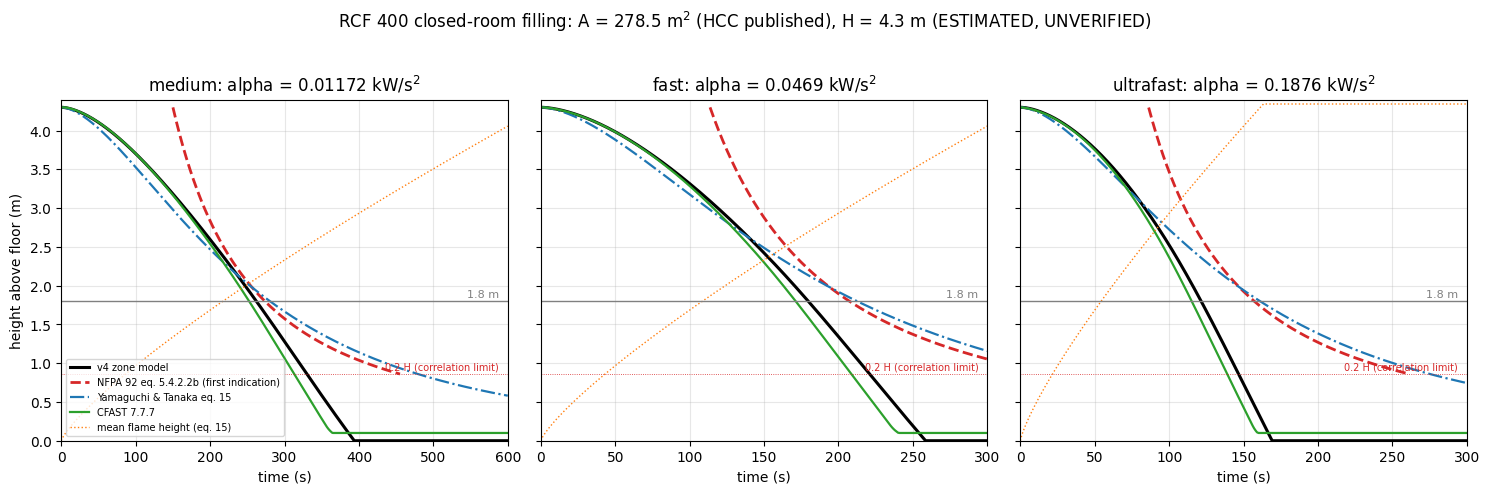

TIME FOR THE LAYER TO REACH 1.8 m  (RCF 400, closed room)
   growth   alpha  v4 model (s)  NFPA 92B (s)  Yamaguchi-Tanaka (s)  CFAST (s)  Q at v4 1.8 m (kW)  flame ht then (m)  T_layer then (C)
   medium 0.01172         262.1         273.6                 280.3      253.0                 805                2.1              93.4
     fast  0.0469         179.7         207.3                 212.5      172.0                1514                2.7             122.0
ultrafast  0.1876         121.5         157.1                 161.0      116.0                2767                3.4             157.2

NFPA 92B column: NFPA 92 (2018) eq. 5.4.2.2b, verified against NFPA 92 (2018) by the author.


In [14]:
# --- Compare all methods: RCF 400, three growth classes ---
T_END = 600
summary = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, cls in zip(axes, ("medium", "fast", "ultrafast")):
    a = ALPHA[cls]
    r = fill_closed_room(A_400, H_400, a, t_end=T_END)
    t = r["t"]
    z_nfpa = nfpa92b_unsteady_z(t, H_400, A_400, a)
    z_yt = yamaguchi_tanaka_z(t, H_400, A_400, a)
    cf = cfast_runs[cls]
    ax.plot(t, r["z"], lw=2.2, color="black", label="v4 zone model")
    ax.plot(t, z_nfpa, lw=2, ls="--", color="tab:red",
            label="NFPA 92 eq. 5.4.2.2b (first indication)")
    ax.plot(t, z_yt, lw=1.6, ls="-.", color="tab:blue", label="Yamaguchi & Tanaka eq. 15")
    ax.plot(cf["Time"], cf["HGT_1"], lw=1.6, color="tab:green", label="CFAST 7.7.7")
    ax.plot(t, r["zf"], lw=1, ls=":", color="tab:orange", label="mean flame height (eq. 15)")
    x_max = 300 if cls != "medium" else T_END
    ax.axhline(LEVEL, color="gray", lw=1)
    ax.text(x_max * 0.98, LEVEL + 0.05, "1.8 m", ha="right", fontsize=8, color="gray")
    ax.axhline(0.2 * H_400, color="tab:red", lw=0.6, ls=":")
    ax.text(x_max * 0.98, 0.2 * H_400 + 0.05, "0.2 H (correlation limit)", ha="right",
            fontsize=7, color="tab:red")
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, H_400 + 0.1)
    ax.set_title(f"{cls}: alpha = {a} kW/s$^2$")
    ax.set_xlabel("time (s)"); ax.grid(alpha=0.3)
    # CFAST time to 1.8 m
    t_cf = time_to(cf["Time"].to_numpy(), cf["HGT_1"].to_numpy(), LEVEL)
    i18 = np.nonzero(r["z"] <= LEVEL)[0]
    i18 = i18[0] if len(i18) else -1
    summary.append({
        "growth": cls, "alpha": str(a),
        "v4 model (s)": time_to(t, r["z"], LEVEL),
        "NFPA 92B (s)": time_to(t, np.nan_to_num(z_nfpa, nan=H_400), LEVEL),
        "Yamaguchi-Tanaka (s)": time_to(t, z_yt, LEVEL),
        "CFAST (s)": t_cf,
        "Q at v4 1.8 m (kW)": round(r["Q"][i18]),
        "flame ht then (m)": round(r["zf"][i18], 2),
        "T_layer then (C)": round(r["T"][i18], 1),
    })
axes[0].set_ylabel("height above floor (m)")
axes[0].legend(fontsize=7, loc="lower left")
plt.suptitle(f"RCF 400 closed-room filling: A = {A_400:.1f} m$^2$ (HCC published), "
             f"H = {H_400} m (ESTIMATED, UNVERIFIED)", y=1.02)
plt.tight_layout(); plt.show()

sum_df = pd.DataFrame(summary)
print("TIME FOR THE LAYER TO REACH 1.8 m  (RCF 400, closed room)")
print(sum_df.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print("\nNFPA 92B column: NFPA 92 (2018) eq. 5.4.2.2b, verified against NFPA 92 (2018) by the author.")

Fast fire, time to 1.8 m relative to the v4 model:
  NFPA 92B (s)            207.3 s  (+15% vs v4 model)
  Yamaguchi-Tanaka (s)    212.5 s  (+18% vs v4 model)
  CFAST (s)               172.0 s  (-4% vs v4 model)


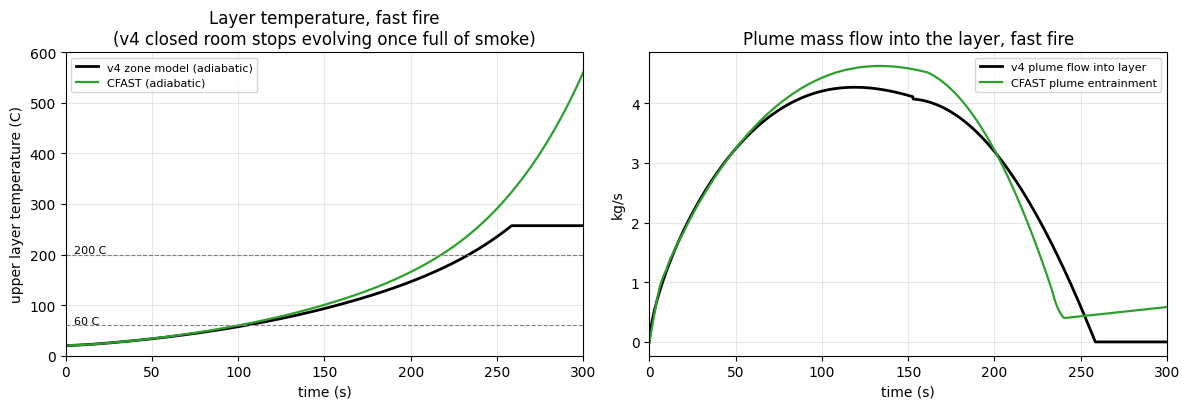

In [15]:
# --- Ratios and layer temperature, fast fire ---
fs = sum_df.set_index("growth").loc["fast"]
base = fs["v4 model (s)"]
print("Fast fire, time to 1.8 m relative to the v4 model:")
for col in ("NFPA 92B (s)", "Yamaguchi-Tanaka (s)", "CFAST (s)"):
    print(f"  {col:22s} {fs[col]:6.1f} s  ({100*(fs[col]-base)/base:+.0f}% vs v4 model)")

r = fill_closed_room(A_400, H_400, ALPHA["fast"], t_end=300)
cf = cfast_runs["fast"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(r["t"], r["T"], color="black", lw=2, label="v4 zone model (adiabatic)")
ax1.plot(cf["Time"], cf["ULT_1"], color="tab:green", lw=1.6, label="CFAST (adiabatic)")
ax1.axhline(60, color="gray", lw=0.8, ls="--"); ax1.text(5, 63, "60 C", fontsize=8)
ax1.axhline(200, color="gray", lw=0.8, ls="--"); ax1.text(5, 203, "200 C", fontsize=8)
ax1.set_xlim(0, 300); ax1.set_ylim(0, 600); ax1.set_xlabel("time (s)"); ax1.set_ylabel("upper layer temperature (C)")
ax1.set_title("Layer temperature, fast fire" + chr(10) + "(v4 closed room stops evolving once full of smoke)"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)
ax2.plot(r["t"], r["mp"], color="black", lw=2, label="v4 plume flow into layer")
ax2.plot(cf["Time"], cf["PLUM_1"], color="tab:green", lw=1.6, label="CFAST plume entrainment")
ax2.set_xlim(0, 300); ax2.set_xlabel("time (s)"); ax2.set_ylabel("kg/s")
ax2.set_title("Plume mass flow into the layer, fast fire"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 2.9 Why the methods disagree, and which way is conservative

The diagnostic below reruns the v4 model with each of its two room-scale features switched off, to see which one moves the answer toward the correlations.

In [16]:
diag = []
for cls in ("medium", "fast", "ultrafast"):
    a = ALPHA[cls]
    row = {"growth": cls}
    for label, kw in (("v4 model", {}),
                      ("no thermal expansion", {"expansion": False}),
                      ("far-field plume only", {"in_flame": False}),
                      ("neither", {"expansion": False, "in_flame": False})):
        r = fill_closed_room(A_400, H_400, a, t_end=600, **kw)
        row[label + " (s)"] = time_to(r["t"], r["z"], LEVEL)
    s = sum_df.set_index("growth").loc[cls]
    row["NFPA 92B (s)"] = s["NFPA 92B (s)"]
    row["Y-T (s)"] = s["Yamaguchi-Tanaka (s)"]
    row["CFAST (s)"] = s["CFAST (s)"]
    diag.append(row)
diag_df = pd.DataFrame(diag)
print("DIAGNOSTIC: time to 1.8 m (s), RCF 400 closed room")
print(diag_df.to_string(index=False, float_format=lambda v: f"{v:.0f}"))
r = fill_closed_room(A_400, H_400, ALPHA["fast"])
i = np.nonzero(r["z"] <= LEVEL)[0][0]
print(f"\nFast fire at 1.8 m: layer {r['T'][i]:.0f} C, so each kg of smoke occupies "
      f"{(r['T'][i]+273.15)/T_AMB:.2f}x the volume it would at ambient density.")

DIAGNOSTIC: time to 1.8 m (s), RCF 400 closed room
   growth  v4 model (s)  no thermal expansion (s)  far-field plume only (s)  neither (s)  NFPA 92B (s)  Y-T (s)  CFAST (s)
   medium           262                       303                       262          303           274      280        253
     fast           180                       215                       180          215           207      212        172
ultrafast           121                       151                       121          149           157      161        116

Fast fire at 1.8 m: layer 122 C, so each kg of smoke occupies 1.35x the volume it would at ambient density.


**Reading the results.**

- **CFAST agrees with the v4 model to within about 3 to 5%** (CFAST slightly faster) for all three growth rates. CFAST is an independent, validated NIST zone model that uses the full Heskestad plume with a virtual origin, the same adiabatic walls, and a real fire area. Agreement here checks the mass and energy bookkeeping and the plume choice.
- **The two correlation-style methods (NFPA 92B and Yamaguchi-Tanaka) are slower,** by about 4 to 33% depending on growth rate, with the biggest gap for the ultrafast fire. The diagnostic shows the main reason is **thermal expansion**: in the adiabatic v4 model and CFAST, the layer is about 90 to 160 C when it reaches 1.8 m, so the same smoke mass takes up 27 to 53% more volume. With expansion switched off, the v4 model lands at or slightly beyond the two correlations (303 / 215 / 151 s against 274 to 280 / 207 to 212 / 157 to 161 s), so expansion accounts for essentially the whole gap. Yamaguchi-Tanaka fixes the layer density at 1 kg/m^3 (about 80 C) and has no flame region. The NFPA 92B correlation is fit to large-space experiments in which the layer is cooler relative to ambient because of heat loss to the enclosure and much larger dilution.
- **The flame-height effect is real but smaller.** At 1.8 m the mean flame height (2.1 to 3.4 m) is above the interface for all three growth rates, so the interface is inside the flame zone. Using the far-field equation everywhere ("far-field plume only") changes the time by at most 2 s here, because the in-flame branch only matters once the interface is below the flame tip, which happens just before 1.8 m is reached.
- **Validity edge.** RCF 400 is inside the correlation's stated A/H^2 and z/H ranges, but those ranges were set for atrium-scale spaces where the flame is short compared with the ceiling. In a 4.3 m room the flame is as tall as the layer depth that matters, so the correlation is being used at the edge of its physical basis, even though the numbers are in range.

**Conclusion for v4.** The v4 single-room model is **faster** (more conservative) than both empirical correlations and within a few percent of CFAST. It is the adiabatic assumption that makes it conservative, and that assumption was chosen deliberately (Section 2.3). The model is accepted for Gate 3, with the note that real heat loss to the ceiling and walls would slow the descent, likely by tens of seconds, moving it toward the correlations.

### 2.10 Realistic heat loss case

**Why it is needed.** With adiabatic walls the layer is 90 to 160 C when it reaches 1.8 m, so the "interface below 1.8 m AND temperature above 60 C" condition is met the moment the interface passes 1.8 m. Visibility, and therefore the material scenarios, could then never decide ASET. Real layers lose heat to the ceiling and walls. v4 therefore carries **two heat loss cases** through every later gate:

- **Adiabatic** (Sections 2.1 to 2.9): no heat loss. The conservative baseline.
- **Realistic:** convective heat transfer from the layer to the ceiling and upper walls, with transient conduction into those surfaces.

**Method (CFAST Technical Reference Guide, NIST TN 1889v1, Section 5.2 to 5.3, pp. 31 to 32).**

- Convective flux to a surface: q'' = h (T_u - T_w) (eq. 5.22).
- Natural convection coefficient: h = C |T_u - T_w|^(1/3), with C = 1.31 for walls and 1.52 for the ceiling (eq. 5.23, from Holman, *Heat Transfer*).
- Ceiling in the fire room, early stage: the ceiling jet heats the ceiling before a layer forms. Area-averaged ceiling-jet flux (Alpert, via eq. 5.25): q''_avg = 0.27 Q_c / ((LW)^0.68 H^0.64), with Q_c in W. CFAST uses h = max(q''_avg / (T_u - T_s), C|T_u - T_s|^(1/3)) (eq. 5.26), so the ceiling flux is the larger of the ceiling-jet flux and natural convection.
- Conduction into each surface: 1D transient heat equation dT/dt = (k / rho c) d^2T/dx^2 (eq. 5.28), solved here with an explicit finite-difference scheme (CFAST uses an implicit solver; the physics is the same).
- Surfaces exposed to the layer: the whole ceiling, plus the wall band from the ceiling down to the interface (perimeter x layer depth). The lower layer stays at ambient.

**Not modeled: radiation from the layer to the walls.** CFAST includes it; v4 does not. Omitting a heat loss path makes the layer hotter and deeper than reality, so this is **conservative** and is expected to make v4's realistic case slightly hotter than CFAST.

**Surfaces, flagged `# ASSUMPTION`.** No construction drawings were available, so walls are taken as gypsum board and the ceiling as a concrete deck. Thermal properties are those distributed with NIST CFAST 7.7.7 in its example input files (`Examples/*.in`):
- Gypsum board: k = 0.16 W/(m K), rho = 480 kg/m^3, c = 1.0 kJ/(kg K). Thickness 5/8 in (15.9 mm), a common single-layer wall board.
- Concrete, normal weight: k = 1.75 W/(m K), rho = 2200 kg/m^3, c = 1.0 kJ/(kg K). Thickness 6 in (0.152 m), the CFAST material "Concrete Normal Weight (6 in)".
- Back faces insulated (no heat passes through). This keeps the inner surface hotter and reduces heat loss slightly: conservative.

**Cross-check against ASET's heat loss fraction.** The ASET model (Cooper 1981, 1982; described in NISTIR 5516 Appendix E, Section 4.2.1) lumps all losses into one fraction lambda_c of the total heat release, with a stated range of 0.6 to 0.9. The equivalent fraction for v4 is (radiated fraction 0.3) + (convective loss to surfaces) / Q. It is printed below for comparison.

**Validation.** CFAST is rerun for the same single RCF 400 room with gypsum walls and a concrete ceiling and compared with v4's realistic case.

In [17]:
# ============================================================
# HEAT LOSS: surfaces with 1D transient conduction
# ============================================================
MATERIALS = {
    # From NIST CFAST 7.7.7 example inputs (Examples/*.in).   # ASSUMPTION (materials)
    "gypsum":   {"k": 0.16, "rho": 480.0,  "c": 1000.0, "thick": 0.0159},  # 5/8 in board, ASSUMPTION
    "concrete": {"k": 1.75, "rho": 2200.0, "c": 1000.0, "thick": 0.1524},  # 6 in deck, ASSUMPTION
}
WALL_MATL, CEIL_MATL = "gypsum", "concrete"     # ASSUMPTION: no construction drawings
C_WALL, C_CEIL = 1.31, 1.52                     # CFAST Tech. Ref. eq. 5.23

class Surface:
    # One wall or ceiling: explicit 1D conduction, insulated back face.
    def __init__(self, matl, dx_target):
        p = MATERIALS[matl]
        self.k, self.rho, self.c = p["k"], p["rho"], p["c"]
        n = max(int(round(p["thick"] / dx_target)) + 1, 3)
        self.dx = p["thick"] / (n - 1)
        self.a = self.k / (self.rho * self.c)       # thermal diffusivity, m^2/s
        self.T = np.full(n, T_AMB)                  # node temperatures, K

    @property
    def Ts(self):
        return self.T[0]                            # exposed surface temperature

    def step(self, q_in, dt):
        # Advance one step with heat flux q_in (W/m^2) into the exposed face.
        T, dx, a = self.T, self.dx, self.a
        r = a * dt / dx**2
        assert r <= 0.5, "explicit conduction unstable: reduce dt or increase dx"
        new = T.copy()
        new[1:-1] = T[1:-1] + r * (T[2:] - 2 * T[1:-1] + T[:-2])
        # Half cells at the faces: front receives q_in, back is insulated.
        new[0] = T[0] + dt / (self.rho * self.c * dx / 2) * (q_in - self.k * (T[0] - T[1]) / dx)
        new[-1] = T[-1] + dt / (self.rho * self.c * dx / 2) * (self.k * (T[-2] - T[-1]) / dx)
        self.T = new

def h_natural(C, dT):
    # CFAST eq. 5.23, W/(m^2 K)
    return C * abs(dT) ** (1 / 3)

def ceiling_jet_flux(qc_kw, A, H):
    # Area-averaged ceiling-jet convective flux (W/m^2), CFAST eq. 5.25.
    # (LW) = ceiling area A.
    return 0.27 * (qc_kw * 1000.0) / (A ** 0.68 * H ** 0.64) if qc_kw > 0 else 0.0

def layer_heat_loss(T_u, z, A, H, perim, ceil, wall, dt, qc_kw=0.0, fire_room=False):
    # Convective loss from the layer (kW) to ceiling + upper walls, and
    # advance the surface conduction. Returns loss in kW.
    depth = max(H - z, 0.0)
    if depth <= 1e-6:                     # no layer yet: surfaces see ambient air
        ceil.step(0.0, dt); wall.step(0.0, dt)
        return 0.0
    dTc = T_u - ceil.Ts
    q_ceil = h_natural(C_CEIL, dTc) * dTc
    if fire_room:                         # CFAST eq. 5.26: max(ceiling jet, natural)
        q_ceil = max(q_ceil, ceiling_jet_flux(qc_kw, A, H))
    dTw = T_u - wall.Ts
    q_wall = h_natural(C_WALL, dTw) * dTw
    ceil.step(q_ceil, dt); wall.step(q_wall, dt)
    return (q_ceil * A + q_wall * perim * depth) / 1000.0

In [18]:
# --- Zone perimeters (needed for the wall band in contact with the layer) ---
# Count exposed cell faces on the grid, then scale by sqrt(smoke area /
# grid area) so the perimeter matches the smoke-model floor area at the
# same shape. For RCF 400 this equals the CFAST room's 2 x (13.92 + 20.01).
def grid_perimeter(cells):
    n = 0
    for (c, r) in cells:
        for dc, dr in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            if (c + dc, r + dr) not in cells:
                n += 1
    return n * CELL_SIZE_M

ZONE_PERIM = {z: grid_perimeter(ZONE_CELLS[z]) * math.sqrt(SMOKE_AREA_M2[z] / GRID_AREA_M2[z])
              for z in ZONES}
for z in ZONES:
    print(f"{z:20s} perimeter {ZONE_PERIM[z]:6.1f} m (grid {grid_perimeter(ZONE_CELLS[z]):.0f} m)")

RCF 400              perimeter   67.9 m (grid 78 m)
RCF 401              perimeter   47.4 m (grid 46 m)
Lobby                perimeter   46.9 m (grid 70 m)
Corridor + NW nook   perimeter  132.0 m (grid 132 m)
S stair nook         perimeter   34.0 m (grid 34 m)


In [19]:
def fill_room(A, H, perim, alpha, heat_loss, t_end=600.0, dt=0.1, q_max=Q_MAX_KW,
              chi_c=CHI_CONV):
    # Single closed room, constant pressure. Tracks layer mass m (kg) and
    # excess enthalpy E = m cp (T_u - T_a) (kJ). Volume follows from
    # V = m / rho_a + E / (rho_a cp T_a), the same relation as Sec. 2.3.
    n = int(round(t_end / dt)) + 1
    t_arr = np.linspace(0.0, t_end, n)
    out = {k: np.zeros(n) for k in ("Q", "z", "T", "mp", "loss")}
    m = E = 0.0
    V_room = A * H
    ceil, wall = Surface(CEIL_MATL, 0.002), Surface(WALL_MATL, 0.0005)
    E_loss_total = 0.0
    for i, t in enumerate(t_arr):
        Q = hrr(t, alpha, q_max); qc = chi_c * Q
        V = m / RHO_AMB + E / (RHO_AMB * CP_AIR * T_AMB)
        z = max(H - V / A, 0.0)
        T_u = T_AMB + E / (m * CP_AIR) if m > 1e-9 else T_AMB
        mp = plume_mass_flow(qc, z)
        if T_u > T_AMB + 1e-9:
            mp = min(mp, qc / (CP_AIR * (T_u - T_AMB)))
        loss = 0.0
        if heat_loss:
            loss = layer_heat_loss(T_u, z, A, H, perim, ceil, wall, dt, qc, fire_room=True)
            loss = min(loss, (E + qc * dt) / dt)      # cannot remove more heat than the layer holds
        out["Q"][i], out["z"][i], out["T"][i] = Q, z, T_u - 273.15
        out["mp"][i], out["loss"][i] = mp, loss
        if i == n - 1:
            break
        if V < V_room:
            m += mp * dt
            E += (qc - loss) * dt
            E_loss_total += loss * dt
    out["t"] = t_arr
    out["E_loss_kJ"] = E_loss_total
    return out

P_400 = ZONE_PERIM[Z400]
# Consistency: with heat loss off, fill_room must reproduce Sec. 2 (fill_closed_room).
ra = fill_room(A_400, H_400, P_400, ALPHA["fast"], heat_loss=False)
rb = fill_closed_room(A_400, H_400, ALPHA["fast"], dt=0.1)
print(f"Consistency (adiabatic): t(1.8 m) = {time_to(ra['t'], ra['z'], LEVEL):.1f} s vs "
      f"{time_to(rb['t'], rb['z'], LEVEL):.1f} s from the Sec. 2 solver")

Consistency (adiabatic): t(1.8 m) = 179.7 s vs 179.7 s from the Sec. 2 solver


In [20]:
# --- CFAST with gypsum walls and concrete ceiling (same room as Sec. 2.8) ---
def write_cfast_input_hl(name, alpha, t_end=600):
    g, cc = MATERIALS["gypsum"], MATERIALS["concrete"]
    lines = [
        f"&HEAD VERSION = 7700, TITLE = 'v4 Gate 2 heat loss {name}: RCF 400 single room' /",
        f"&TIME SIMULATION = {t_end} PRINT = 60 SMOKEVIEW = 0 SPREADSHEET = 1 /",
        "&INIT PRESSURE = 101325 RELATIVE_HUMIDITY = 50 INTERIOR_TEMPERATURE = 20 EXTERIOR_TEMPERATURE = 20 /",
        f"&MATL ID = 'GYPSUM' MATERIAL = 'Gypsum Board' CONDUCTIVITY = {g['k']} DENSITY = {g['rho']} "
        f"SPECIFIC_HEAT = {g['c']/1000} THICKNESS = {g['thick']} EMISSIVITY = 0.9 /",
        f"&MATL ID = 'CONCRETE' MATERIAL = 'Concrete Normal Weight (6 in)' CONDUCTIVITY = {cc['k']} "
        f"DENSITY = {cc['rho']} SPECIFIC_HEAT = {cc['c']/1000} THICKNESS = {cc['thick']} EMISSIVITY = 0.94 /",
        f"&COMP ID = 'RCF400' DEPTH = {ROOM_D:.3f} HEIGHT = {H_400} WIDTH = {ROOM_W:.3f}",
        f"  CEILING_MATL_ID = 'CONCRETE' CEILING_THICKNESS = {cc['thick']}",
        f"  WALL_MATL_ID = 'GYPSUM' WALL_THICKNESS = {g['thick']}",
        f"  FLOOR_MATL_ID = 'CONCRETE' FLOOR_THICKNESS = {cc['thick']}",
        "  ORIGIN = 0, 0, 0 GRID = 50, 50, 50 /",
        "&VENT TYPE = 'WALL' ID = 'Leak' COMP_IDS = 'RCF400' 'OUTSIDE', BOTTOM = 0 TOP = 0.2, "
        "WIDTH = 0.5 FACE = 'FRONT' OFFSET = 1 /",
        f"&FIRE ID = 'Fire' COMP_ID = 'RCF400', FIRE_ID = 'T2' LOCATION = {ROOM_W/2:.3f}, {ROOM_D/2:.3f} /",
        "&CHEM ID = 'T2' CARBON = 1 CHLORINE = 0 HYDROGEN = 4 NITROGEN = 0 OXYGEN = 0",
        "   HEAT_OF_COMBUSTION = 50000 RADIATIVE_FRACTION = 0.3 /",
        "&TABL ID = 'T2' LABELS = 'TIME', 'HRR', 'HEIGHT', 'AREA', 'CO_YIELD', 'SOOT_YIELD', "
        "'HCN_YIELD', 'HCL_YIELD', 'TRACE_YIELD' /",
    ]
    for t in range(0, t_end + 1, 5):
        q = hrr(t, alpha)
        lines.append(f"&TABL ID = 'T2', DATA = {t}, {q:.2f}, 0, {max(q/HRRPUA_FIRE, 0.01):.4f}, 0, 0, 0, 0, 0 /")
    lines.append("&TAIL /")
    (CFAST_DIR / f"{name}.in").write_text("\n".join(lines) + "\n")

def run_cfast(name):
    if have_exe:
        res = subprocess.run([CFAST_EXE, f"{name}.in"], cwd=CFAST_DIR, capture_output=True, text=True)
        ok = "Normal exit" in res.stdout
        print(f"  {name}: {'normal exit' if ok else 'FAILED'}")
        if not ok:   # fail loudly: never fall back to a partial or stale CSV
            raise RuntimeError(f"CFAST failed for {name}: {res.stdout[-400:]}")
        for ext in (".log", ".out", ".plt", ".smv", ".status", "_calculations.csv",
                    "_devices.csv", "_masses.csv", "_vents.csv", "_walls.csv", "_zone.csv"):
            (CFAST_DIR / f"{name}{ext}").unlink(missing_ok=True)
    return read_cfast_compartments(name)

cfast_hl = {}
for cls in ("medium", "fast", "ultrafast"):
    name = f"rcf400_{cls}_gypsum_concrete"
    write_cfast_input_hl(name, ALPHA[cls])
    cfast_hl[cls] = run_cfast(name)

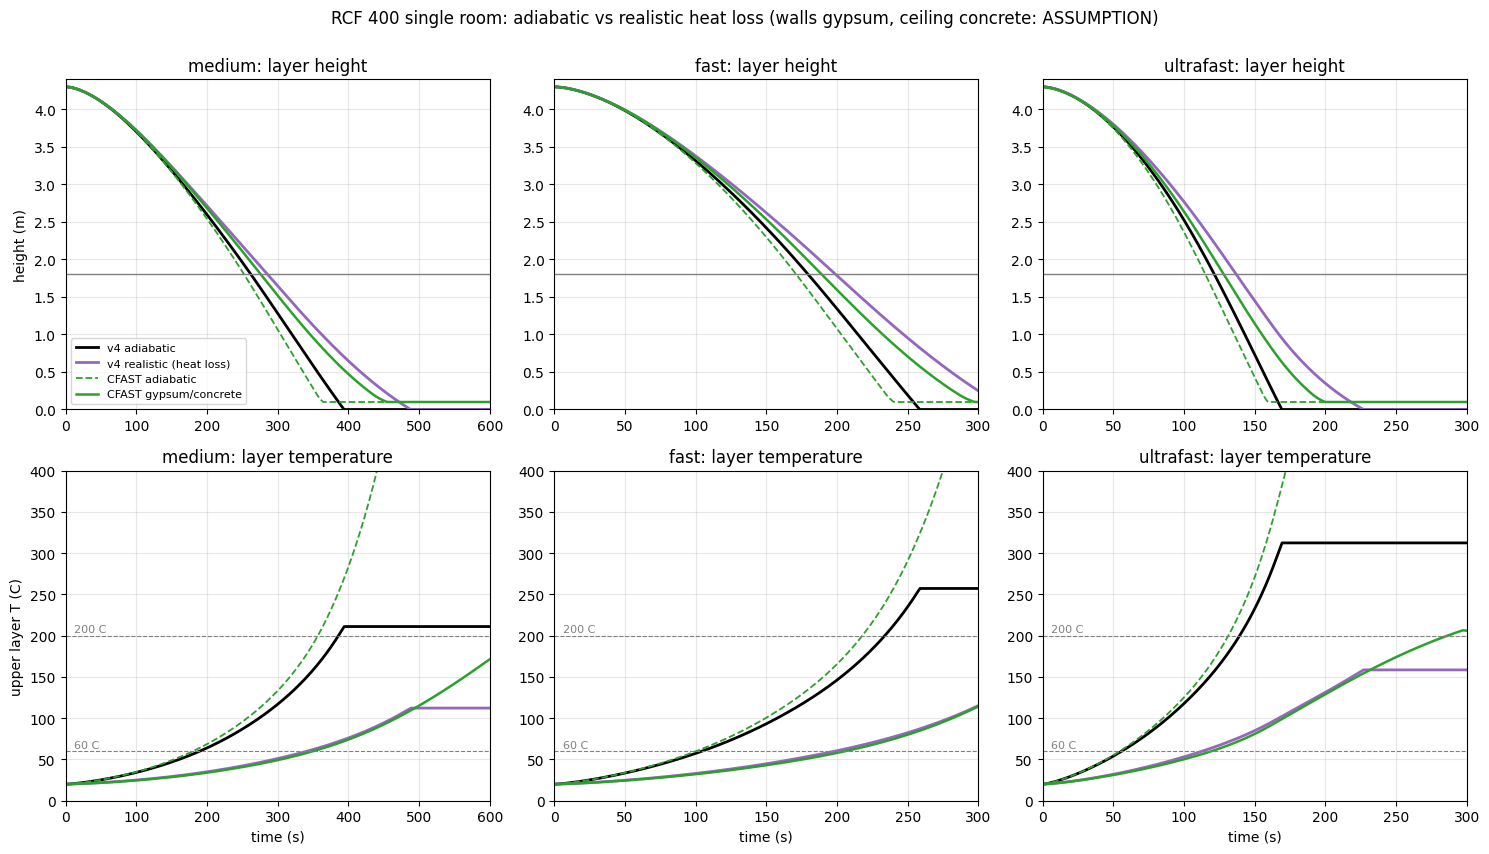

AT THE MOMENT THE INTERFACE REACHES 1.8 m (t = time, T = layer temperature)
   growth  v4 adiab t(s)  v4 adiab T(C)  CFAST adiab t(s)  CFAST adiab T(C)  v4 real t(s)  v4 real T(C)  CFAST real t(s)  CFAST real T(C)  equiv lambda_c  equiv Ks
   medium          262.2           93.4             253.0              97.6         285.5          48.3            277.0             45.1            0.77      0.33
     fast          179.7          122.0             172.0             124.9         199.1          60.2            190.0             54.5            0.76      0.34
ultrafast          121.5          157.2             116.0             158.5         137.0          75.1            129.0             65.7            0.76      0.34

equiv lambda_c = radiated fraction (0.3) + convective loss / Q at that moment; ASET (Cooper) range is 0.6 to 0.9.
equiv Ks = share of the convective heat still in the layer at that moment (1 = adiabatic); NFPA 92 (2018) eq. 5.5.5 uses Ks = 1.0 (5.5.5.1) and 0.5 (5.5.

In [21]:
# --- Compare: adiabatic vs realistic, v4 vs CFAST ---
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for j, cls in enumerate(("medium", "fast", "ultrafast")):
    a = ALPHA[cls]
    ad = fill_room(A_400, H_400, P_400, a, heat_loss=False, t_end=600)
    hl = fill_room(A_400, H_400, P_400, a, heat_loss=True, t_end=600)
    cfa, cfh = cfast_runs[cls], cfast_hl[cls]
    x_max = 600 if cls == "medium" else 300
    ax = axes[0, j]
    ax.plot(ad["t"], ad["z"], color="black", lw=2, label="v4 adiabatic")
    ax.plot(hl["t"], hl["z"], color="tab:purple", lw=2, label="v4 realistic (heat loss)")
    ax.plot(cfa["Time"], cfa["HGT_1"], color="tab:green", lw=1.3, ls="--", label="CFAST adiabatic")
    ax.plot(cfh["Time"], cfh["HGT_1"], color="tab:green", lw=1.8, label="CFAST gypsum/concrete")
    ax.axhline(LEVEL, color="gray", lw=1)
    ax.set_xlim(0, x_max); ax.set_ylim(0, H_400 + 0.1)
    ax.set_title(f"{cls}: layer height"); ax.grid(alpha=0.3)
    ax = axes[1, j]
    ax.plot(ad["t"], ad["T"], color="black", lw=2)
    ax.plot(hl["t"], hl["T"], color="tab:purple", lw=2)
    ax.plot(cfa["Time"], cfa["ULT_1"], color="tab:green", lw=1.3, ls="--")
    ax.plot(cfh["Time"], cfh["ULT_1"], color="tab:green", lw=1.8)
    for lvl in (60, 200):
        ax.axhline(lvl, color="gray", lw=0.8, ls="--")
        ax.text(x_max * 0.02, lvl + 4, f"{lvl} C", fontsize=8, color="gray")
    ax.set_xlim(0, x_max); ax.set_ylim(0, 400)
    ax.set_title(f"{cls}: layer temperature"); ax.set_xlabel("time (s)"); ax.grid(alpha=0.3)

    def at18(t, z, T):
        i = np.nonzero(np.asarray(z) <= LEVEL)[0]
        return (float(np.asarray(t)[i[0]]), float(np.asarray(T)[i[0]])) if len(i) else (np.nan, np.nan)
    ta, Ta = at18(ad["t"], ad["z"], ad["T"])
    th, Th = at18(hl["t"], hl["z"], hl["T"])
    tca, Tca = at18(cfa["Time"], cfa["HGT_1"], cfa["ULT_1"])
    tch, Tch = at18(cfh["Time"], cfh["HGT_1"], cfh["ULT_1"])
    ih = np.nonzero(hl["z"] <= LEVEL)[0][0]
    lam_eq = (1 - CHI_CONV) + hl["loss"][ih] / hl["Q"][ih]
    ks_eq = 1 - hl["loss"][ih] / (CHI_CONV * hl["Q"][ih])   # share of convective heat kept by the layer
    rows.append({"growth": cls,
                 "v4 adiab t(s)": ta, "v4 adiab T(C)": Ta,
                 "CFAST adiab t(s)": tca, "CFAST adiab T(C)": Tca,
                 "v4 real t(s)": th, "v4 real T(C)": Th,
                 "CFAST real t(s)": tch, "CFAST real T(C)": Tch,
                 "equiv lambda_c": lam_eq, "equiv Ks": ks_eq})
axes[0, 0].set_ylabel("height (m)"); axes[1, 0].set_ylabel("upper layer T (C)")
axes[0, 0].legend(fontsize=8, loc="lower left")
plt.suptitle("RCF 400 single room: adiabatic vs realistic heat loss (walls gypsum, ceiling concrete: ASSUMPTION)",
             y=1.0)
plt.tight_layout(); plt.show()

hl_df = pd.DataFrame(rows)
print("AT THE MOMENT THE INTERFACE REACHES 1.8 m (t = time, T = layer temperature)")
print(hl_df.to_string(index=False, float_format=lambda v: f"{v:.1f}" if abs(v) >= 1 else f"{v:.2f}"))
print("\nequiv lambda_c = radiated fraction (0.3) + convective loss / Q at that moment;"
      " ASET (Cooper) range is 0.6 to 0.9.")
print("equiv Ks = share of the convective heat still in the layer at that moment (1 = adiabatic);"
      " NFPA 92 (2018) eq. 5.5.5 uses Ks = 1.0 (5.5.5.1) and 0.5 (5.5.5.2).")

**Reading the heat loss comparison** (table above).

- **Realistic case versus adiabatic.** Plume entrainment is unchanged, but heat leaves the layer, so it is cooler and occupies less volume. It reaches 1.8 m about 15 to 20 s later (285 / 199 / 137 s against 262 / 180 / 121 s) and at about half the temperature rise (48 / 60 / 75 C against 93 / 122 / 157 C).
- **The temperature criterion no longer triggers automatically.** At 1.8 m the realistic layer is below 60 C for the medium fire, right at 60 C for the fast fire, and above it for the ultrafast fire. Visibility can now govern ASET, which is the reason this case exists.
- **Agreement with CFAST.** With gypsum walls and a concrete ceiling, CFAST reaches 1.8 m at 277 / 190 / 129 s at 45 / 55 / 66 C. v4 is 3 to 9 C hotter, as expected: CFAST also loses heat by radiation from the layer to the walls, which v4 omits on purpose (conservative). v4 reaches 1.8 m 8 s later than CFAST, the same 3 to 6% offset seen in the adiabatic comparison. That offset comes from the plume equation (CFAST's full Heskestad plume with a virtual origin entrains slightly more than the NFPA 92B simple plume), not from the heat loss model.
- **ASET cross-check.** The equivalent heat loss fraction at 1.8 m is about 0.76 for all three growth rates, inside Cooper's published range of 0.6 to 0.9. This is a plausibility check, not a calibration: nothing was tuned to hit it.
- **NFPA 92 (2018) cross-check, eq. 5.5.5.** NFPA 92 writes the smoke temperature as T_s = T_o + K_s Q_c / (m c_p), where K_s is the share of the convective heat that stays in the smoke: K_s = 1.0 for exhaust calculations (5.5.5.1) and K_s = 0.5 for plugholing (5.5.5.2) (verified against NFPA 92 (2018) by the author). The table above prints the equivalent for v4's realistic case: **K_s is about 0.34 when the interface reaches 1.8 m, which is below NFPA 92's lower value of 0.5, not between 0.5 and 1.0.** In other words the realistic case retains less heat than either NFPA 92 assumption, and the adiabatic case corresponds to K_s = 1.0. Two cautions in reading this: (1) NFPA 92's K_s values are design choices, each picked to be conservative for its own purpose (high K_s gives a hot, buoyant layer for exhaust sizing; low K_s gives a cool layer that plugholes more easily), not measurements of heat loss; (2) CFAST, run independently with the same materials, retains even less heat than v4. So v4's realistic case is consistent with CFAST and with Cooper's range, but it is outside the NFPA 92 bracket on the low-heat side. **This is why the adiabatic case is kept as the conservative bound in every later gate.**

**Both cases are carried forward.** Adiabatic is the conservative bound; realistic is the best estimate. Gates 4 and 5 report both, and record which tenability criterion sets ASET in each case.

## Gate 3: Multi-zone smoke spill

The single-room model of Gate 2 is extended to all five zones. The fire plume feeds the origin room only. Smoke leaves a zone only through the openings defined in Gate 1, and **only once that zone's layer has dropped below the opening's soffit.** That is the bottleneck this gate is about: a room first fills its own ceiling volume above the door head, and only then does smoke spill, at a rate limited by the opening width and by how far the layer sits below the soffit.

### 3.1 Flow through an opening

The flow law is Bernoulli's equation integrated over the height of the opening, the same starting point CFAST uses (CFAST Tech. Ref., NIST TN 1889v1, eq. 4.1 to 4.3, p. 19):

$$\dot m = \int C\, w\, \sqrt{2 \rho\, \Delta P(z)}\; dz$$

**Discharge (orifice) coefficient C = 0.7.** Source: CFAST Tech. Ref. p. 19 ("C is the orifice coefficient taken to be 0.7"), citing Steckler, Baum and Quintiere, *Fire Induced Flows Through Room Openings: Flow Coefficients*, NBSIR 83-2801, National Bureau of Standards, 1984.

**Pressure difference, simplified (stated assumptions).**
1. Every zone's lower layer is at ambient pressure at floor level (the same leaky-room assumption as Gate 2). The neutral plane of an opening is taken at the source zone's interface.
2. Inside the smoke band, hydrostatics gives Delta P(z) = (rho_a - rho_u) g (z - z_src): the hot, light layer pushes outward more the higher you go.
3. If the receiving zone also has smoke below the same soffit, both layers push against each other. With equal layer densities, the net push is set by the **difference** in how far each layer sits below the soffit.

With d_src = soffit - z_src and d_rcv = soffit - z_rcv (each zero if that layer is above the soffit), flow goes from the deeper side to the shallower side, with delta = d_src - d_rcv > 0:

$$\dot m = C\, w\, \sqrt{2 g\, \rho_u (\rho_a - \rho_u)}\;\left[\tfrac{2}{3}\,\delta^{3/2} + d_{rcv}\,\delta^{1/2}\right]$$

When the receiving side has no smoke at the soffit (d_rcv = 0) this is the classic result: flow proportional to w d^(3/2). The flow stops when the two layers stand at the same depth below the soffit, so smoke can also flow **back** into a room if the lobby's layer is deeper.

### 3.2 Smoke entering the receiving zone

- The part of the outflow that enters **below** the receiving zone's interface rises to its layer as a **spill plume** and entrains ambient air on the way. CFAST Tech. Ref. eq. 4.6 to 4.7 (p. 20), from Poreh, Morgan, Marshall and Harrison, "Entrainment by Two-Dimensional Spill Plumes," *Fire Safety Journal* 30 (1998) 1 to 19:

$$\dot m_{e} = C_m \left(\frac{T_l}{T_u}\right)^{2/3}\left(\frac{g \rho_l^2}{c_p T_l}\right)^{1/3} \dot h^{1/3} w^{2/3}\,(z_I - z_N), \qquad \dot h = c_p (T_u - T_l)\,\dot m_{u \to l}, \quad C_m = 0.44$$

  with z_I the receiving interface and z_N the neutral plane (here, the source interface).
- The part entering **at or above** the receiving interface joins its layer directly.
- Smoke carries its mass, its excess heat, and its share of the combustion products (the tracer below) with it.

**Why include the spill plume.** Entrained air makes the receiving layer deeper, so it lowers the interface faster: **conservative for layer height**. It also dilutes smoke, so soot concentration and temperature are lower than they would be without it. Gate 4 uses both, so the effect on ASET depends on which criterion governs, and that will be reported.

### 3.3 Other rules

- **Heat loss:** the same two cases as Gate 2 (adiabatic, and realistic gypsum walls and concrete ceiling in every zone). The ceiling-jet term applies only in the fire room.
- **Full zones:** when a zone's layer reaches the floor, any further smoke is assumed to leak out of the floor through cracks and undercuts (the leaky-room assumption). The leaked mass, heat and products are counted, so the conservation check still closes.
- **Stair doors closed for smoke** (Gate 1): nothing leaves the floor through the stairs.
- **Products tracer.** The solver carries a passive tracer equal to the total heat released by the fire (kJ). Any combustion product made in proportion to the heat release rate, such as soot (Gate 4: soot made = yield x Q / heat of combustion), is then the tracer times a constant. **The smoke flow does not depend on the material, so one smoke run serves all three material scenarios.**
- **Time step** 0.1 s, with two numerical safeguards described in Section 3.3a. Flows are recorded as averages over each 1 s interval.

In [22]:
# ============================================================
# GATE 3: MULTI-ZONE SOLVER
# ============================================================
G_ACC = 9.81
C_VENT = 0.7          # orifice coefficient, CFAST Tech. Ref. p. 19 (Steckler et al., NBSIR 83-2801)
CM_SPILL = 0.44       # spill plume constant, CFAST Tech. Ref. eq. 4.7 (Poreh et al. 1998)
CP_J = CP_AIR * 1000  # J/(kg K)

def vent_flow(z_src, z_rcv, s, w, T_src):
    # Returns (total, below-receiving-interface part) in kg/s from src to rcv.
    d_s = max(s - z_src, 0.0)
    d_r = max(s - z_rcv, 0.0)
    delta = d_s - d_r
    if delta <= 0 or T_src <= T_AMB:
        return 0.0, 0.0
    rho_u = RHO_AMB * T_AMB / T_src
    k = C_VENT * w * math.sqrt(2 * G_ACC * rho_u * (RHO_AMB - rho_u))
    below = k * (2 / 3) * delta ** 1.5          # enters receiving lower layer
    above = k * d_r * delta ** 0.5              # enters receiving layer directly
    return below + above, below

def spill_entrainment(m_below, T_src, z_I, z_N, w):
    # Extra ambient air entrained by the spill plume (kg/s), CFAST eq. 4.7.
    if m_below <= 0 or z_I <= z_N or T_src <= T_AMB:
        return 0.0
    hdot = CP_J * (T_src - T_AMB) * m_below                       # W
    return (CM_SPILL * (T_AMB / T_src) ** (2 / 3)
            * (G_ACC * RHO_AMB**2 / (CP_J * T_AMB)) ** (1 / 3)
            * hdot ** (1 / 3) * w ** (2 / 3) * (z_I - z_N))

def run_smoke(fire_zone, alpha, heat_loss, t_end=900.0, dt=0.1, ceil_scale=1.0,
              q_max=Q_MAX_KW, openings=None, record_every=1.0):
    # Multi-zone two-layer smoke model. Returns a dict with time series per
    # zone (z, T, tracer concentration) and conservation bookkeeping.
    openings = OPENINGS if openings is None else openings
    H = {zz: ZONE_H[zz] * ceil_scale for zz in ZONES}
    A = SMOKE_AREA_M2
    Vroom = {zz: A[zz] * H[zz] for zz in ZONES}
    # Passage soffits follow the scaled ceilings; door heads stay at 2.13 m.
    ops = []
    for a, b, kind, w, s in openings:
        s_eff = s if "door" in kind else min(H[a], H[b])
        ops.append((a, b, w, s_eff))
    m = {zz: 0.0 for zz in ZONES}; E = dict(m); P = dict(m)   # mass, excess enthalpy, tracer
    surf = {zz: (Surface(CEIL_MATL, 0.002), Surface(WALL_MATL, 0.0005)) for zz in ZONES}
    book = {"plume_in": 0.0, "spill_entrained": 0.0, "Qc_in": 0.0, "Q_in": 0.0,
            "loss": 0.0, "leak_m": 0.0, "leak_E": 0.0, "leak_P": 0.0, "cap_hits": 0}
    n = int(round(t_end / dt))
    stride = int(round(record_every / dt))
    rec = {"t": [], "Q": []}
    for zz in ZONES:
        rec[zz + ":z"], rec[zz + ":T"], rec[zz + ":P"], rec[zz + ":V"] = [], [], [], []
    rec_flow = {f"{a}->{b}": [] for a, b, *_ in ops}
    acc_flow = {f"{a}->{b}": 0.0 for a, b, *_ in ops}

    def state(zz):
        V = m[zz] / RHO_AMB + E[zz] / (RHO_AMB * CP_AIR * T_AMB)
        z = max(H[zz] - V / A[zz], 0.0)
        T = T_AMB + E[zz] / (m[zz] * CP_AIR) if m[zz] > 1e-9 else T_AMB
        return V, z, T

    for step in range(n + 1):
        t = step * dt
        S = {zz: state(zz) for zz in ZONES}
        Q = hrr(t, alpha, q_max); qc = CHI_CONV * Q
        if step % stride == 0:
            rec["t"].append(t); rec["Q"].append(Q)
            for zz in ZONES:
                V, z, T = S[zz]
                rec[zz + ":z"].append(z); rec[zz + ":T"].append(T - 273.15)
                rec[zz + ":V"].append(V)
                rec[zz + ":P"].append(P[zz] / V if V > 1e-6 else 0.0)   # kJ released per m^3 of layer
        if step == n:
            break
        dm = {zz: 0.0 for zz in ZONES}; dE = dict(dm); dP = dict(dm)
        # --- fire plume into the origin zone ---
        V, z, T = S[fire_zone]
        mp = plume_mass_flow(qc, z)
        if T > T_AMB + 1e-9:
            mp = min(mp, qc / (CP_AIR * (T - T_AMB)))
        dm[fire_zone] += mp * dt; dE[fire_zone] += qc * dt; dP[fire_zone] += Q * dt
        book["plume_in"] += mp * dt; book["Qc_in"] += qc * dt; book["Q_in"] += Q * dt
        # --- vent flows ---
        moved = {}
        for (a, b, w, s) in ops:
            moved[(a, b)] = moved[(b, a)] = 0.0
            za, Ta = S[a][1], S[a][2]
            zb, Tb = S[b][1], S[b][2]
            f_ab, below_ab = vent_flow(za, zb, s, w, Ta)
            f_ba, below_ba = vent_flow(zb, za, s, w, Tb)
            for src, rcv, f, below, z_src, z_rcv, T_src in (
                    (a, b, f_ab, below_ab, za, zb, Ta), (b, a, f_ba, below_ba, zb, za, Tb)):
                if f <= 0:
                    continue
                f_dt = min(f * dt, 0.2 * m[src])          # stability cap
                # No-overshoot cap: moving volume dV from src to rcv changes the
                # depth difference by dV (1/A_src + 1/A_rcv). Never move more than
                # half the volume that would level the two layers in one step,
                # otherwise the flow flips direction every step (chatter).
                delta = (s - z_src) - max(s - z_rcv, 0.0)
                rho_src = RHO_AMB * T_AMB / T_src
                dV_level = delta / (1 / A[src] + 1 / A[rcv])
                if 0.5 * dV_level * rho_src < f_dt:
                    book["cap_hits"] += 1
                f_dt = min(f_dt, 0.5 * dV_level * rho_src)
                if f_dt <= 0:
                    continue
                frac = f_dt / m[src]
                scale = f_dt / (f * dt)
                ent = spill_entrainment(below * scale, T_src, z_rcv, z_src, w) * dt
                moved[(src, rcv)] += f_dt
                dm[src] -= f_dt; dE[src] -= frac * E[src]; dP[src] -= frac * P[src]
                dm[rcv] += f_dt + ent; dE[rcv] += frac * E[src]; dP[rcv] += frac * P[src]
                book["spill_entrained"] += ent
            acc_flow[f"{a}->{b}"] += (moved[(a, b)] - moved[(b, a)])
            if (step + 1) % stride == 0:   # record the mean net flow over the last interval
                rec_flow[f"{a}->{b}"].append(acc_flow[f"{a}->{b}"] / record_every)
                acc_flow[f"{a}->{b}"] = 0.0
        # --- heat loss ---
        if heat_loss:
            for zz in ZONES:
                V, z, T = S[zz]
                c_s, w_s = surf[zz]
                L = layer_heat_loss(T, z, A[zz], H[zz], ZONE_PERIM[zz], c_s, w_s, dt,
                                    qc if zz == fire_zone else 0.0, fire_room=(zz == fire_zone))
                L = min(L, max(E[zz] + dE[zz], 0.0) / dt)
                dE[zz] -= L * dt; book["loss"] += L * dt
        # --- apply, then leak anything beyond the zone volume ---
        for zz in ZONES:
            m[zz] += dm[zz]; E[zz] += dE[zz]; P[zz] += dP[zz]
            V = m[zz] / RHO_AMB + E[zz] / (RHO_AMB * CP_AIR * T_AMB)
            if V > Vroom[zz]:
                keep = Vroom[zz] / V
                book["leak_m"] += m[zz] * (1 - keep); book["leak_E"] += E[zz] * (1 - keep)
                book["leak_P"] += P[zz] * (1 - keep)
                m[zz] *= keep; E[zz] *= keep; P[zz] *= keep
    out = {k: np.array(v) for k, v in rec.items()}
    out["flows"] = {k: np.array(v) for k, v in rec_flow.items()}
    out["book"] = book
    out["final"] = {"m": dict(m), "E": dict(E), "P": dict(P)}
    out["H"] = H; out["fire_zone"] = fire_zone
    return out

def conservation_report(res):
    b, f = res["book"], res["final"]
    m_now, E_now, P_now = sum(f["m"].values()), sum(f["E"].values()), sum(f["P"].values())
    m_in = b["plume_in"] + b["spill_entrained"]
    print(f"  mass:    in zones {m_now:9.1f} + leaked {b['leak_m']:8.1f} = {m_now+b['leak_m']:9.1f} kg"
          f" | plume + spill entrainment {m_in:9.1f} kg | error {100*(m_now+b['leak_m']-m_in)/m_in:+.4f}%")
    E_acc = E_now + b["leak_E"] + b["loss"]
    print(f"  energy:  in zones {E_now:9.0f} + leaked {b['leak_E']:8.0f} + lost to walls {b['loss']:9.0f}"
          f" = {E_acc:9.0f} kJ | convective heat released {b['Qc_in']:9.0f} kJ"
          f" | error {100*(E_acc-b['Qc_in'])/b['Qc_in']:+.4f}%")
    print(f"  tracer:  in zones {P_now:9.0f} + leaked {b['leak_P']:8.0f} = {P_now+b['leak_P']:9.0f} kJ"
          f" | heat released {b['Q_in']:9.0f} kJ | error {100*(P_now+b['leak_P']-b['Q_in'])/b['Q_in']:+.4f}%")

### 3.4 Consistency check: with every opening closed, the fire room must reproduce Gate 2

In [23]:
closed = [(a, b, k, 0.0, s) for a, b, k, w, s in OPENINGS]   # zero-width openings
for hl in (False, True):
    rz = run_smoke(Z400, ALPHA["fast"], heat_loss=hl, t_end=400, openings=closed)
    r1 = fill_room(A_400, H_400, P_400, ALPHA["fast"], heat_loss=hl, t_end=400)
    tz = time_to(rz["t"], rz[Z400 + ":z"], LEVEL); t1 = time_to(r1["t"], r1["z"], LEVEL)
    print(f"{'realistic' if hl else 'adiabatic':9s}: multi-zone t(1.8 m) = {tz:.1f} s, "
          f"Gate 2 single room = {t1:.1f} s")

adiabatic: multi-zone t(1.8 m) = 180.0 s, Gate 2 single room = 179.7 s


realistic: multi-zone t(1.8 m) = 200.0 s, Gate 2 single room = 199.1 s


In [24]:
# --- Gate 3 runs: fast fire, both origins, both heat loss cases ---
T_END_G3 = 900
g3 = {}
for origin in (Z400, Z401):
    for hl in (False, True):
        key = (origin, "realistic" if hl else "adiabatic")
        g3[key] = run_smoke(origin, ALPHA["fast"], heat_loss=hl, t_end=T_END_G3)
        print(f"Fire in {origin}, {key[1]} walls:")
        conservation_report(g3[key])

Fire in RCF 400, adiabatic walls:
  mass:    in zones    1293.8 + leaked    339.6 =    1633.4 kg | plume + spill entrainment    1633.4 kg | error +0.0000%
  energy:  in zones    727789 + leaked  1660175 + lost to walls         0 =   2387965 kJ | convective heat released   2387965 kJ | error -0.0000%
  tracer:  in zones   1039699 + leaked  2371679 =   3411378 kJ | heat released   3411378 kJ | error +0.0000%


Fire in RCF 400, realistic walls:
  mass:    in zones    2521.1 + leaked     22.4 =    2543.5 kg | plume + spill entrainment    2543.5 kg | error -0.0000%
  energy:  in zones    367589 + leaked    11224 + lost to walls   2009152 =   2387965 kJ | convective heat released   2387965 kJ | error +0.0000%
  tracer:  in zones   3337994 + leaked    73384 =   3411378 kJ | heat released   3411378 kJ | error +0.0000%


Fire in RCF 401, adiabatic walls:
  mass:    in zones    1403.7 + leaked     46.0 =    1449.7 kg | plume + spill entrainment    1449.7 kg | error +0.0000%
  energy:  in zones    695581 + leaked  1692383 + lost to walls         0 =   2387965 kJ | convective heat released   2387965 kJ | error -0.0000%
  tracer:  in zones    993688 + leaked  2417690 =   3411378 kJ | heat released   3411378 kJ | error -0.0000%


Fire in RCF 401, realistic walls:
  mass:    in zones    2584.9 + leaked      0.0 =    2584.9 kg | plume + spill entrainment    2584.9 kg | error +0.0000%
  energy:  in zones    305671 + leaked        0 + lost to walls   2082294 =   2387965 kJ | convective heat released   2387965 kJ | error -0.0000%
  tracer:  in zones   3411378 + leaked        0 =   3411378 kJ | heat released   3411378 kJ | error -0.0000%


### 3.3a Numerical safeguards, and a convergence check with them active

The solver advances in fixed steps of 0.1 s. Two safeguards keep that explicit stepping stable:

1. **Mass cap.** No zone may lose more than 20% of its layer mass through one opening in one step.
2. **No-overshoot cap.** Moving a volume dV of smoke from zone A to zone B through an opening raises A's interface by dV / A_A and lowers B's by dV / A_B, so the difference in layer depth below the soffit shrinks by dV (1/A_A + 1/A_B). The volume that would bring the two layers exactly level is therefore dV_level = delta / (1/A_A + 1/A_B). In any one step, the solver moves **at most half** of dV_level.

**Why the second cap is needed.** The flow law makes the flow grow like the square root of the depth difference, so it stays large even when the layers are nearly level. Near equilibrium, an explicit step can overshoot: zone A pushes too much smoke into B, then B pushes it back the next step, and so on. Before the cap was added, the lobby and the south stair nook (joined by a 13 m passage) did exactly that, swapping smoke every 0.1 s. Every swap also added spill-plume air, so the chatter **manufactured smoke volume** that is not physical. With the cap, the layers approach equilibrium smoothly from one side, the way the physical flow does.

**Does the cap change the answer?** A numerical safeguard is acceptable only if the result does not depend on it. The check below reruns all four Gate 3 cases with the time step halved (0.05 s) and compares the time each zone's interface reaches 1.8 m. It also reports how many steps the cap was active.

In [25]:
conv_rows = []
for origin in (Z400, Z401):
    for hl in (False, True):
        tag = "realistic" if hl else "adiabatic"
        r_a = g3[(origin, tag)]
        r_b = run_smoke(origin, ALPHA["fast"], heat_loss=hl, t_end=T_END_G3, dt=0.05)
        for zz in ZONES:
            ta = time_to(r_a["t"], r_a[zz + ":z"], LEVEL)
            tb = time_to(r_b["t"], r_b[zz + ":z"], LEVEL)
            conv_rows.append({"fire in": origin, "walls": tag, "zone": zz,
                              "t(1.8 m) dt=0.1": ta, "t(1.8 m) dt=0.05": tb, "change (s)": tb - ta})
        print(f"fire in {origin}, {tag}: no-overshoot cap active in {r_a['book']['cap_hits']} "
              f"flow evaluations at dt=0.1 s, {r_b['book']['cap_hits']} at dt=0.05 s")
conv_df = pd.DataFrame(conv_rows)
print()
print(conv_df.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print(f"\nLargest change in any zone's 1.8 m time from halving the step: "
      f"{conv_df['change (s)'].abs().max():.1f} s (results are recorded every 1 s, so 0.0 means under 1 s)")

fire in RCF 400, adiabatic: no-overshoot cap active in 9192 flow evaluations at dt=0.1 s, 17550 at dt=0.05 s


fire in RCF 400, realistic: no-overshoot cap active in 12708 flow evaluations at dt=0.1 s, 20257 at dt=0.05 s


fire in RCF 401, adiabatic: no-overshoot cap active in 19346 flow evaluations at dt=0.1 s, 27214 at dt=0.05 s


fire in RCF 401, realistic: no-overshoot cap active in 13139 flow evaluations at dt=0.1 s, 19658 at dt=0.05 s

fire in     walls               zone  t(1.8 m) dt=0.1  t(1.8 m) dt=0.05  change (s)
RCF 400 adiabatic            RCF 400            181.0             181.0         0.0
RCF 400 adiabatic            RCF 401            322.0             322.0         0.0
RCF 400 adiabatic              Lobby            251.0             251.0         0.0
RCF 400 adiabatic Corridor + NW nook            271.0             271.0         0.0
RCF 400 adiabatic       S stair nook            251.0             251.0         0.0
RCF 400 realistic            RCF 400            200.0             200.0         0.0
RCF 400 realistic            RCF 401            404.0             404.0         0.0
RCF 400 realistic              Lobby            291.0             291.0         0.0
RCF 400 realistic Corridor + NW nook            328.0             328.0         0.0
RCF 400 realistic       S stair nook            2

### 3.5 Independent check: CFAST with the same five zones and openings

CFAST is run with five compartments that have the smoke-model floor areas, ceiling heights, wall and ceiling materials, and the same four openings (width and soffit). CFAST needs rectangular rooms and vents that fit on one wall, so the shapes are rectangles of the right area (the lobby to south nook passage, 13 m, is split into two 6.5 m vents). **Leakage (revised after Gate 3 review).** The first CFAST runs gave each compartment one small 0.1 m^2 leak, which let the whole floor pressurize to about 130 Pa. They now use distributed leakage from the CFAST User's Guide (NIST TN 1889v2), Table 4.1, p. 16, reproduced from Klote et al., *Handbook of Smoke Control Engineering*: "Average" construction, **1.7e-4 m^2 per m^2 of wall** and **5.2e-5 m^2 per m^2 of floor**, flagged `# ASSUMPTION` (the building's actual leakage is unknown). Stair doors stay closed, consistent with v4. The runs also carry a soot yield (non-FR polyurethane, used in Gate 4); soot does not change the flows in a way that matters here. CFAST computes the full stratified vent flow, including lower-layer counterflow and door jets, so this checks the simplified spill rule above against a full zone-model treatment.

In [26]:
CF_SHAPE = {   # (width, depth) in m, area = smoke area; rectangles only (CFAST)
    Z400: (ROOM_W, ROOM_D),
    Z401: (9.0, SMOKE_AREA_M2[Z401] / 9.0),
    ZLOB: (9.0, SMOKE_AREA_M2[ZLOB] / 9.0),
    ZCOR: (5.0, SMOKE_AREA_M2[ZCOR] / 5.0),
    ZSN:  (4.0, SMOKE_AREA_M2[ZSN] / 4.0),
}
CF_ID = {Z400: "RCF400", Z401: "RCF401", ZLOB: "LOBBY", ZCOR: "CORRIDOR", ZSN: "SNOOK"}
# Leakage to the rest of the building, "Average" construction, CFAST User's Guide
# (NIST TN 1889v2) Table 4.1, p. 16, from Klote et al., Handbook of Smoke Control Engineering.
LEAK_WALL  = 1.7e-4    # m^2 leak per m^2 of wall (exterior walls, average)   # ASSUMPTION
LEAK_FLOOR = 5.2e-5    # m^2 leak per m^2 of floor (floors, average)          # ASSUMPTION
# Reference material for CFAST soot (Gate 4 visibility check): non-FR flexible PU,
# Tewarson via FDS User's Guide p. 182-183 (soot yield 0.131, CO yield 0.01, dHc 26.2 MJ/kg).
CF_SOOT, CF_CO, CF_HOC = 0.131, 0.01, 26200.0

def write_cfast_multizone(name, fire_zone, alpha, heat_loss, t_end=900, ceil_scale=1.0):
    g, cc = MATERIALS["gypsum"], MATERIALS["concrete"]
    L = [f"&HEAD VERSION = 7700, TITLE = 'v4 Gate 3 {name}' /",
         f"&TIME SIMULATION = {t_end} PRINT = 60 SMOKEVIEW = 0 SPREADSHEET = 2 /",
         "&INIT PRESSURE = 101325 RELATIVE_HUMIDITY = 50 INTERIOR_TEMPERATURE = 20 EXTERIOR_TEMPERATURE = 20 /",
         f"&MATL ID = 'GYPSUM' MATERIAL = 'Gypsum Board' CONDUCTIVITY = {g['k']} DENSITY = {g['rho']} "
         f"SPECIFIC_HEAT = {g['c']/1000} THICKNESS = {g['thick']} EMISSIVITY = 0.9 /",
         f"&MATL ID = 'CONCRETE' MATERIAL = 'Concrete Normal Weight (6 in)' CONDUCTIVITY = {cc['k']} "
         f"DENSITY = {cc['rho']} SPECIFIC_HEAT = {cc['c']/1000} THICKNESS = {cc['thick']} EMISSIVITY = 0.94 /"]
    x0 = 0.0
    for zz in ZONES:
        w_, d_ = CF_SHAPE[zz]
        if heat_loss:
            mats = (f"  CEILING_MATL_ID = 'CONCRETE' CEILING_THICKNESS = {cc['thick']} "
                    f"WALL_MATL_ID = 'GYPSUM' WALL_THICKNESS = {g['thick']} "
                    f"FLOOR_MATL_ID = 'CONCRETE' FLOOR_THICKNESS = {cc['thick']}")
        else:
            mats = "  CEILING_MATL_ID = 'OFF' WALL_MATL_ID = 'OFF' FLOOR_MATL_ID = 'OFF'"
        L += [f"&COMP ID = '{CF_ID[zz]}' DEPTH = {d_:.3f} HEIGHT = {ZONE_H[zz]*ceil_scale:.3f} WIDTH = {w_:.3f}",
              mats, f"  ORIGIN = {x0:.1f}, 0, 0 GRID = 50, 50, 50",
              f"  LEAK_AREA_RATIO = {LEAK_WALL}, {LEAK_FLOOR} /"]
        x0 += w_ + 2.0
        pass
    k = 0
    for a, b, kind, w, s in OPENINGS:
        if "door" not in kind:               # passage soffit follows the scaled ceilings
            s = min(ZONE_H[a], ZONE_H[b]) * ceil_scale
        pieces = [w] if w <= 9.0 else [w / 2, w / 2]
        for p_ in pieces:
            k += 1
            L.append(f"&VENT TYPE = 'WALL' ID = 'V{k}' COMP_IDS = '{CF_ID[a]}' '{CF_ID[b]}', "
                     f"BOTTOM = 0 TOP = {s:.3f}, WIDTH = {p_:.3f} FACE = 'FRONT' OFFSET = 0 /")
    fw, fd = CF_SHAPE[fire_zone]
    L += [f"&FIRE ID = 'Fire' COMP_ID = '{CF_ID[fire_zone]}', FIRE_ID = 'T2' LOCATION = {fw/2:.3f}, {fd/2:.3f} /",
          "&CHEM ID = 'T2' CARBON = 1 CHLORINE = 0 HYDROGEN = 4 NITROGEN = 0 OXYGEN = 0",
          f"   HEAT_OF_COMBUSTION = {CF_HOC:.0f} RADIATIVE_FRACTION = 0.3 /",
          "&TABL ID = 'T2' LABELS = 'TIME', 'HRR', 'HEIGHT', 'AREA', 'CO_YIELD', 'SOOT_YIELD', "
          "'HCN_YIELD', 'HCL_YIELD', 'TRACE_YIELD' /"]
    # CFAST fails at start-up with ~300 fire-table rows (found at Gate 5), so write rows
    # every 5 s only while the fire grows, then one row at t_end (the cap holds constant).
    t_cap = math.sqrt(Q_MAX_KW / alpha)
    t_rows = [t for t in range(0, t_end + 1, 5) if t <= t_cap + 5] + [t_end]
    for t in sorted(set(t_rows)):
        q = hrr(t, alpha)
        L.append(f"&TABL ID = 'T2', DATA = {t}, {q:.2f}, 0, {max(q/HRRPUA_FIRE, 0.01):.4f}, "
                 f"{CF_CO}, {CF_SOOT}, 0, 0, 0 /")
    L.append("&TAIL /")
    (CFAST_DIR / f"{name}.in").write_text("\n".join(L) + "\n")

cf3 = {}
for origin in (Z400, Z401):
    for hl in (False, True):
        tag = "realistic" if hl else "adiabatic"
        name = f"multizone_{CF_ID[origin].lower()}_fast_{tag}"
        write_cfast_multizone(name, origin, ALPHA["fast"], hl)
        cf3[(origin, tag)] = run_cfast(name)
CF_COL = {zz: i + 1 for i, zz in enumerate(ZONES)}   # CFAST numbers compartments in input order

print()
print("CFAST floor pressure above ambient (Pa), with the cited leakage:")
for key, cf in cf3.items():
    p = cf[[f"PRS_{CF_COL[zz]}" for zz in ZONES]]
    at = {tt: cf.iloc[(cf["Time"] - tt).abs().argmin()][f"PRS_{CF_COL[ZLOB]}"] for tt in (100, 200, 300)}
    print(f"  fire in {key[0]}, {key[1]:9s}: max over all zones {p.max().max():6.1f} Pa; "
          f"lobby at 100/200/300 s: {at[100]:.1f} / {at[200]:.1f} / {at[300]:.1f} Pa")


CFAST floor pressure above ambient (Pa), with the cited leakage:
  fire in RCF 400, adiabatic: max over all zones 2549.2 Pa; lobby at 100/200/300 s: 36.9 / 524.8 / 2000.2 Pa
  fire in RCF 400, realistic: max over all zones  222.4 Pa; lobby at 100/200/300 s: 2.8 / 47.2 / 183.7 Pa
  fire in RCF 401, adiabatic: max over all zones 1363.3 Pa; lobby at 100/200/300 s: 36.6 / 500.1 / 1258.7 Pa
  fire in RCF 401, realistic: max over all zones  111.8 Pa; lobby at 100/200/300 s: 4.1 / 49.6 / 60.7 Pa


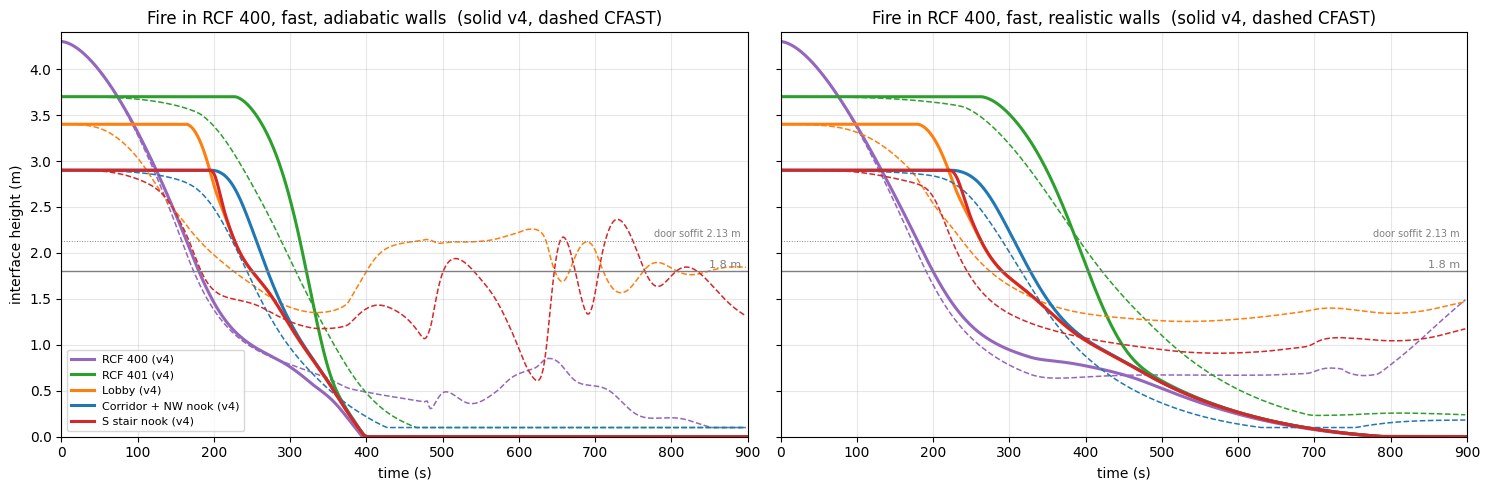

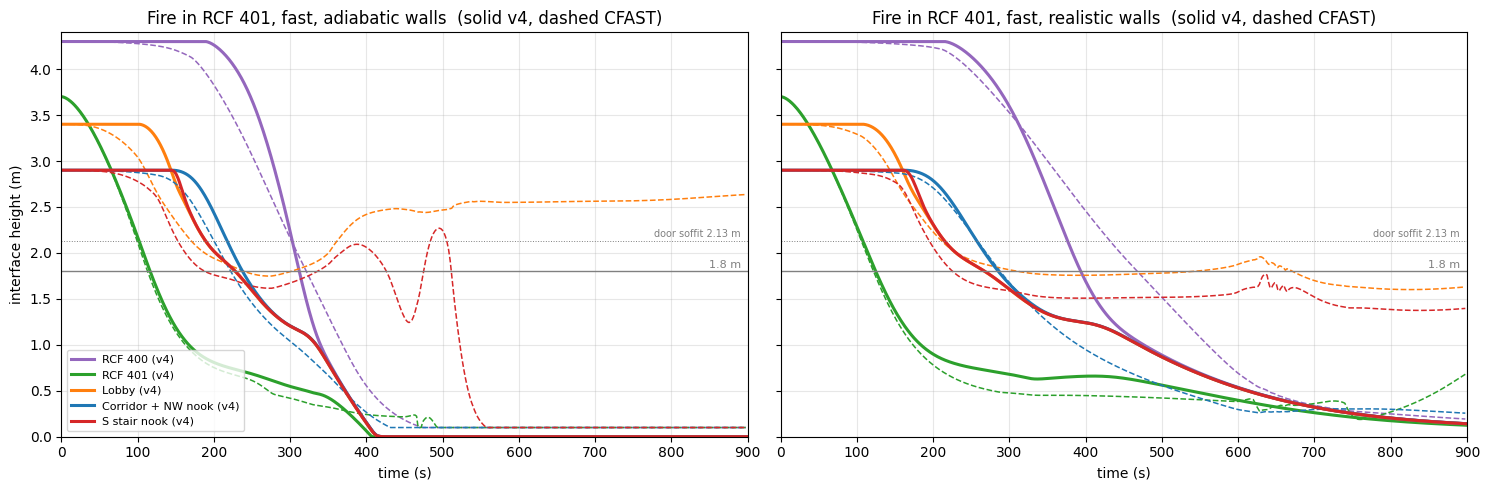

In [27]:
# --- Plot z(t) for every zone ---
for origin in (Z400, Z401):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for ax, tag in zip(axes, ("adiabatic", "realistic")):
        r = g3[(origin, tag)]; cf = cf3[(origin, tag)]
        for zz in ZONES:
            col = {Z400: "tab:purple", Z401: "tab:green", ZLOB: "tab:orange",
                   ZCOR: "tab:blue", ZSN: "tab:red"}[zz]
            ax.plot(r["t"], r[zz + ":z"], color=col, lw=2.2, label=f"{zz} (v4)")
            ax.plot(cf["Time"], cf[f"HGT_{CF_COL[zz]}"], color=col, lw=1.1, ls="--")
        ax.axhline(LEVEL, color="gray", lw=1); ax.text(T_END_G3 * 0.99, LEVEL + 0.04, "1.8 m",
                                                        ha="right", fontsize=8, color="gray")
        ax.axhline(DOOR_SOFFIT, color="gray", lw=0.7, ls=":")
        ax.text(T_END_G3 * 0.99, DOOR_SOFFIT + 0.04, "door soffit 2.13 m", ha="right", fontsize=7, color="gray")
        ax.set_xlim(0, T_END_G3); ax.set_ylim(0, 4.4)
        ax.set_title(f"Fire in {origin}, fast, {tag} walls  (solid v4, dashed CFAST)")
        ax.set_xlabel("time (s)"); ax.grid(alpha=0.3)
    axes[0].set_ylabel("interface height (m)"); axes[0].legend(fontsize=8, loc="lower left")
    plt.tight_layout(); plt.show()

In [28]:
# --- Key times per zone: spill start, 1.8 m; v4 vs CFAST ---
def first_time(t, y, cond):
    i = np.nonzero(cond(np.asarray(y)))[0]
    return float(np.asarray(t)[i[0]]) if len(i) else np.nan

rows = []
for (origin, tag), r in g3.items():
    cf = cf3[(origin, tag)]
    for zz in ZONES:
        z = r[zz + ":z"]; T = r[zz + ":T"]
        t18 = first_time(r["t"], z, lambda y: y <= LEVEL)
        T18 = float(np.interp(t18, r["t"], T)) if not np.isnan(t18) else np.nan
        tcf = first_time(cf["Time"], cf[f"HGT_{CF_COL[zz]}"], lambda y: y <= LEVEL)
        Tcf = float(np.interp(tcf, cf["Time"], cf[f"ULT_{CF_COL[zz]}"])) if not np.isnan(tcf) else np.nan
        t_smoke = first_time(r["t"], z, lambda y: y < r["H"][zz] - 0.05)   # first 5 cm of layer
        rows.append({"fire in": origin, "walls": tag, "zone": zz,
                     "smoke arrives (s)": t_smoke, "v4 t(1.8 m) s": t18,
                     "CFAST t(1.8 m) s": tcf, "v4 T at 1.8 m (C)": T18,
                     "CFAST T at its 1.8 m (C)": Tcf})
g3_df = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print("GATE 3 KEY TIMES (fast fire)  NaN = never within", T_END_G3, "s")
print(g3_df.to_string(index=False, float_format=lambda v: f"{v:.0f}"))

GATE 3 KEY TIMES (fast fire)  NaN = never within 900 s
fire in     walls               zone  smoke arrives (s)  v4 t(1.8 m) s  CFAST t(1.8 m) s  v4 T at 1.8 m (C)  CFAST T at its 1.8 m (C)
RCF 400 adiabatic            RCF 400                 17            181               174                123                       129
RCF 400 adiabatic            RCF 401                240            322               308                117                        74
RCF 400 adiabatic              Lobby                173            251               228                129                        95
RCF 400 adiabatic Corridor + NW nook                214            271               244                101                        61
RCF 400 adiabatic       S stair nook                201            251               184                 79                        29
RCF 400 realistic            RCF 400                 17            200               192                 61                        55
RCF 400

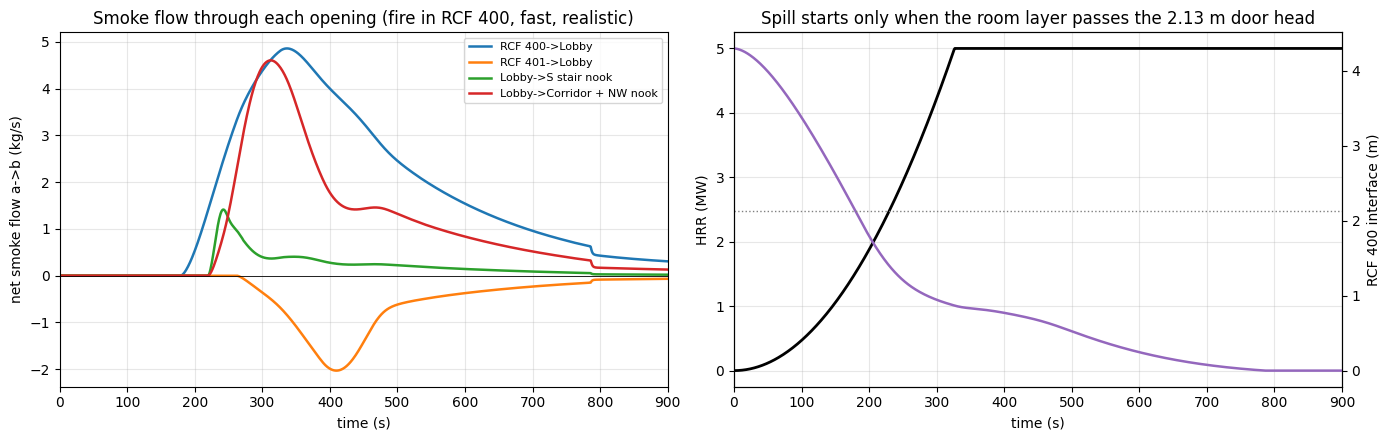

Fire in RCF 400 (fast, realistic): first spill into the lobby at t = 179 s, RCF 400 interface then 2.14 m
Peak spill RCF 400 -> lobby: 4.86 kg/s; peak plume flow in RCF 400 was 18.41 kg/s at the ceiling
Interpretation: the plume pours smoke into the room far faster than one pair of doors can pass it,
so the room fills its ceiling, then spills at a rate set by the door width and the depth below the soffit.


In [29]:
# --- The bottleneck: flow through each opening, fire in RCF 400, realistic walls ---
r = g3[(Z400, "realistic")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
t_f = r["t"][:len(next(iter(r["flows"].values())))]   # flows are recorded up to the last step
for k, f in r["flows"].items():
    ax1.plot(t_f, f, lw=1.8, label=k)
ax1.axhline(0, color="black", lw=0.6)
ax1.set_xlabel("time (s)"); ax1.set_ylabel("net smoke flow a->b (kg/s)")
ax1.set_title("Smoke flow through each opening (fire in RCF 400, fast, realistic)")
ax1.legend(fontsize=8); ax1.grid(alpha=0.3); ax1.set_xlim(0, T_END_G3)
ax2.plot(r["t"], r["Q"] / 1000, color="black", lw=2, label="HRR (MW)")
ax2b = ax2.twinx()
ax2b.plot(r["t"], r[Z400 + ":z"], color="tab:purple", lw=1.8, label="RCF 400 interface")
ax2b.axhline(DOOR_SOFFIT, color="gray", ls=":", lw=1)
ax2.set_xlabel("time (s)"); ax2.set_ylabel("HRR (MW)"); ax2b.set_ylabel("RCF 400 interface (m)")
ax2.set_title("Spill starts only when the room layer passes the 2.13 m door head")
ax2.grid(alpha=0.3); ax2.set_xlim(0, T_END_G3)
plt.tight_layout(); plt.show()

i_sp = np.nonzero(r["flows"][f"{Z400}->{ZLOB}"] > 1e-6)[0]
t_sp = t_f[i_sp[0]] if len(i_sp) else np.nan
print(f"Fire in RCF 400 (fast, realistic): first spill into the lobby at t = {t_sp:.0f} s, "
      f"RCF 400 interface then {np.interp(t_sp, r['t'], r[Z400+':z']):.2f} m")
print(f"Peak spill RCF 400 -> lobby: {r['flows'][f'{Z400}->{ZLOB}'].max():.2f} kg/s; "
      f"peak plume flow in RCF 400 was {max(plume_mass_flow(CHI_CONV*hrr(t, ALPHA['fast']), H_400) for t in r['t']):.2f} kg/s at the ceiling")
print("Interpretation: the plume pours smoke into the room far faster than one pair of doors can pass it,")
print("so the room fills its ceiling, then spills at a rate set by the door width and the depth below the soffit.")

In [30]:
# --- Why CFAST's downstream layers come down sooner ---
cf = cf3[(Z400, "adiabatic")]
print("CFAST, fire in RCF 400, fast, adiabatic: early downstream 'layers' are displaced air, not smoke")
print(f"{'t (s)':>5} {'RCF400 z':>9} {'RCF400 T':>9} {'lobby z':>8} {'lobby T':>8} {'S nook z':>9} {'S nook T':>9} {'floor P (Pa)':>12}")
for tt in (60, 100, 140, 180, 200):
    row = cf.iloc[(cf["Time"] - tt).abs().argmin()]
    print(f"{tt:5d} {row['HGT_1']:9.2f} {row['ULT_1']:9.1f} {row['HGT_3']:8.2f} {row['ULT_3']:8.1f} "
          f"{row['HGT_5']:9.2f} {row['ULT_5']:9.1f} {row['PRS_3']:12.1f}")

CFAST, fire in RCF 400, fast, adiabatic: early downstream 'layers' are displaced air, not smoke
t (s)  RCF400 z  RCF400 T  lobby z  lobby T  S nook z  S nook T floor P (Pa)
   60      3.87      38.0     3.32     20.3      2.88      20.0          4.9
  100      3.29      59.9     3.03     21.4      2.80      20.0         36.9
  140      2.52      91.6     2.55     24.0      2.57      21.3        136.8
  180      1.68     136.4     2.14     36.8      1.87      27.2        355.7
  200      1.38     166.4     1.98     57.3      1.59      38.4        524.8


### 3.6 Reading the Gate 3 results

**What behaves as intended.**
- **Conservation closes** to round-off for mass, energy and the products tracer in all four runs.
- **The fire room matches Gate 2** when the openings are closed (within 1 s), and **matches CFAST within 3 to 8 s** with the openings open.
- **The bottleneck appears.** Smoke does not leave RCF 400 until its layer reaches the 2.13 m door head (about 180 s for the fast fire). The plume is then delivering about 18 kg/s to the ceiling, while the two doors pass at most about 5 kg/s, so the room keeps filling while it spills. The lobby and south nook then fill together, because the 13 m open passage lets their layers equalize below the 2.9 m soffit. RCF 401 is reached last, back through its door.
- **Heat loss matters downstream.** For a fire in RCF 400, the zones away from the fire are 38 to 59 C when their interface reaches 1.8 m in the realistic case, against 79 to 127 C adiabatic. For a fire in RCF 401 the lobby is hotter (95 C realistic), because RCF 401's single door feeds the lobby directly and the small room fills fast. Where the realistic layer stays under 60 C, visibility will decide ASET (Gate 4).
- **Late time.** With the leaky-room assumption and no smoke leaving the floor, every v4 zone eventually fills to the floor (by about 800 s for the fast fire). CFAST's layers level off instead, because its compartments reach a pressure balance with their leaks. The v4 behavior is the conservative one, and it happens well after the times that matter for egress.

**Where v4 and CFAST disagree, and why.** In most downstream zones CFAST's interface reaches 1.8 m earlier than v4's, by up to about 70 s; the biggest gap is the south stair nook. In a few cases v4 is earlier (RCF 400 with the fire in RCF 401, realistic walls: 394 s against CFAST's 468 s). Two reasons, shown in the tables above:
1. **CFAST's early downstream "layers" are mostly displaced air.** As the fire room's layer expands, it pushes lower-layer air out through the doors well before any smoke spills (at 60 s the lobby already has a 20 C "layer" at 3.3 m while RCF 400's smoke is still 1.7 m above the door head). CFAST counts that air as upper layer. When CFAST's south nook layer crosses 1.8 m it is only about 29 C. In v4 the displaced air leaves through the leaky-room assumption, and only smoke (plus the air its spill plume entrains) forms a layer.
2. **CFAST's floor pressurizes, and the cited leakage makes it worse, not better.** With the "Average" construction leakage of CFAST User's Guide Table 4.1, the whole floor has far less leakage area than the single 0.1 m^2 leaks used in the first runs: about 0.06 m^2 for RCF 400 (292 m^2 of wall x 1.7e-4 + 278.5 m^2 of floor x 5.2e-5), and about 0.2 m^2 for the five zones together. The pressures printed above are the result: up to about **2,500 Pa with adiabatic walls** and about **220 Pa with gypsum and concrete**. A sealed floor cannot vent a growing fire. At 5 MW the convective heat expands the gas by roughly Q_c / (rho c_p T) = 3500 / (1.2 x 1.0 x 293), about 10 m^3/s, and pushing that through a leak at a modest 25 Pa takes an opening of about 10 / (0.7 x sqrt(2 x 25 / 1.2)), about 2.2 m^2, the size of an open double door. In the real building that relief would come from doors opened during evacuation, HVAC paths, and failing glazing, none of which is in either model. The CFAST pressures are therefore an artifact of treating the floor as sealed except for construction cracks, and they push smoke through every opening harder than in reality. **Pressures in the thousands of Pa are a sealed-floor artifact:** a 0.9 m by 2.1 m door held shut against 2,500 Pa carries a net force of about 4.7 kN (2,500 x 0.9 x 2.1), roughly the weight of half a tonne. In the real building, doors would be forced open or glazing would fail long before the floor reached such pressures, and that would relieve it. (No glazing failure pressure is used or cited here; the point is only that these pressures are not physically sustainable on a real floor.) (The 2,500 Pa figure is the CFAST adiabatic case; the realistic-wall case peaks near 220 Pa.)

**What this means for v4 (carried into Gate 4).** v4 and CFAST bracket the real floor: v4 assumes perfect pressure relief, CFAST with construction leakage assumes almost none. Following the conservative principle, Gate 4 compares the two zone by zone on the quantity that actually decides tenability (interface height plus visibility, 60 C, and the radiant limit, 180 C after the Gate 4 review), and wherever CFAST makes a zone untenable **earlier** than v4, **v4 adopts CFAST's earlier time for that zone.** That is the correction applied; the cause (pressure-driven flow) is not added to v4 itself, because modeling floor pressure properly needs the very relief paths that are unknown.

## Gate 4: Tenability and agent coupling

### 4.1 Material scenarios

Smoke visibility depends on how much soot the fire makes per unit of heat released: soot mass produced = soot yield x (heat release / effective heat of combustion). Three scenarios bracket the furnishings in the assembly rooms. Every value is loaded from `data/material_scenarios.csv`, which records the source, URL, table or page, and whether the value was **read** in that source (`verified = Y`) or **derived** from values that were read (`verified = N`, with the arithmetic in the `table_or_page` column). Rows with `selected = Y` are the ones the model uses; the others are candidates kept for comparison.

| Scenario | Selected source | Soot yield | Heat of combustion |
|---|---|---|---|
| Non-FR flexible PU foam seating | Tewarson (SFPE Handbook 5th ed.), as reproduced in the FDS User's Guide, NIST SP 1019, p. 182 to 183 | 0.131 | 26.2 MJ/kg |
| FR flexible PU foam seating | NISTIR 4652 (Villa and Babrauskas 1991), nylon over melamine-treated PU foam, 35 kW/m^2 | 0.032 (derived) | 24 MJ/kg |
| Wood / fabric mix | Tewarson wood, as reproduced in the FDS User's Guide, p. 182 to 183 | 0.015 | 16.4 MJ/kg |

**How the NISTIR 4652 soot yields are derived.** NISTIR 4652 reports cone calorimeter results per unit of sample area: total heat released (Table 3, MJ/m^2), smoke produced as extinction area (Table 13, m^2 of extinction per m^2 of sample), and CO produced (Table 9, kg/m^2). Dividing total heat by the effective heat of combustion (Table 4) gives the mass burned per m^2. Smoke produced divided by mass burned is the specific extinction area (m^2/kg), and dividing that by the specific extinction coefficient Km = 8700 m^2/kg (Section 4.2) gives the soot yield.

**Disagreement between sources, and the conservative choice.** For non-FR polyurethane, the Tewarson value (soot yield 0.131) is about four times the value derived from the NISTIR 4652 nylon-over-PU composite (0.034). They describe different things: Tewarson's value is for the foam itself in a fire propagation apparatus; NISTIR 4652's is for a fabric-covered composite in the cone. Following the author's rule, both are recorded and the smokier one is used. No public Tewarson value for FR foam was found, so the FR scenario uses the NISTIR 4652 composite. As a result, the non-FR and FR scenarios come from different test methods; their difference in v4 reflects the source as much as the fire retardant, and that is stated wherever they are compared.

**Wood / fabric.** No public soot yield for polyester or nylon upholstery fabric was found (NISTIR 89-4065, Harkleroad 1989, gives the heat of combustion of polyester wall coverings but no smoke or CO data). The scenario therefore uses **wood values only**, and it **likely understates smoke**, because the upholstery fabric's own contribution is left out. It is an open item.

**Limitations of the yields.** All yields are **well-ventilated** values. Under-ventilated burning makes far more CO and often more soot; ventilation-dependent CO yield belongs with a toxicity (fractional effective dose) model and is out of scope for v4. Bench-scale (cone) heat release is **never** scaled up to the room fire: the design fire stays the t-squared fire of Gate 2. Measured full-scale heat release curves for upholstered furniture (NIST furniture calorimeter studies, the CBUF programme) are the right future source for a measured fire curve.

In [31]:
# ============================================================
# 4.1 MATERIAL SCENARIOS (loaded from data/material_scenarios.csv)
# ============================================================
MAT_CSV = Path("data") / "material_scenarios.csv"
mat_df = pd.read_csv(MAT_CSV)
sel = mat_df[mat_df["selected"] == "Y"]
MATERIAL = {sc: {r.parameter: float(r.value) for r in g.itertuples()}
            for sc, g in sel.groupby("scenario")}
MATERIAL_ORDER = ["nonFR_PU", "FR_PU", "wood_fabric"]
MAT_LABEL = {"nonFR_PU": "non-FR PU", "FR_PU": "FR PU", "wood_fabric": "wood/fabric"}

print("SELECTED MATERIAL VALUES")
show = sel[["scenario", "parameter", "value", "units", "verified", "table_or_page"]]
print(show.to_string(index=False, max_colwidth=60))

unverified = sel[sel["verified"] != "Y"]
PROVISIONAL = len(unverified) > 0
print(f"\n{len(unverified)} selected value(s) are NOT verified (read) in a source:")
for r in unverified.itertuples():
    print(f"  UNVERIFIED  {r.scenario:12s} {r.parameter:20s} {r.value:<8} ({r.notes})")
PROV_TAG = "  [PROVISIONAL: uses unverified material values]" if PROVISIONAL else ""
print(f"\nResults that use these values are labeled PROVISIONAL: {PROVISIONAL}")

# Re-derive the derived values from the rows that were read, as a check on the CSV.
def row(sc, par):
    return float(mat_df[(mat_df.scenario == sc) & (mat_df.parameter == par)].value.iloc[0])
KM = 8700.0   # m^2/kg, Sec. 4.2
m_fr = row("FR_PU", "total_heat_release") / row("FR_PU", "heat_of_combustion")
print(f"\nCheck FR_PU: mass burned {m_fr:.3f} kg/m^2 -> soot yield "
      f"{row('FR_PU','smoke_production')/m_fr/KM:.4f} (CSV {MATERIAL['FR_PU']['soot_yield']}), "
      f"CO yield {row('FR_PU','co_production')/m_fr:.4f} (CSV {MATERIAL['FR_PU']['co_yield']})")
a = "nonFR_PU:alt_nylon_PU_composite_35kW"
m_a = row(a, "total_heat_release") / row(a, "effective_heat_of_combustion")
print(f"Check nylon/PU composite: soot yield {row(a,'smoke_production')/m_a/KM:.4f} "
      f"vs Tewarson 0.131 -> Tewarson is {0.131/(row(a,'smoke_production')/m_a/KM):.1f}x smokier, used")

# What matters for visibility is soot per unit of heat released: y_s / dHc
for sc in MATERIAL_ORDER:
    p = MATERIAL[sc]
    print(f"  {MAT_LABEL[sc]:12s} soot per MJ released = {p['soot_yield']/p['heat_of_combustion']*1000:.2f} g/MJ")

SELECTED MATERIAL VALUES
   scenario          parameter   value units verified                                                table_or_page
   nonFR_PU         soot_yield  0.1310 kg/kg        Y                           Sec. 13.3.4, p. 182 (polyurethane)
   nonFR_PU           co_yield  0.0100 kg/kg        Y                           Sec. 13.3.4, p. 182 (polyurethane)
   nonFR_PU heat_of_combustion 26.2000 MJ/kg        Y Sec. 13.3.4, p. 183, REAC 'plastic' HEAT_OF_COMBUSTION=26200
   nonFR_PU          co2_yield  1.8620 kg/kg        N                                          eq. (13.17), p. 182
      FR_PU heat_of_combustion 24.0000 MJ/kg        Y          Table 4, p. 16, nylon/melamine-treated PU, 35 kW/m2
      FR_PU          co2_yield  1.5000 kg/kg        Y                    Table 10, p. 22, nylon/melamine, 35 kW/m2
      FR_PU         soot_yield  0.0323 kg/kg        N                                       (750 / (64/24)) / 8700
      FR_PU           co_yield  0.0165 kg/kg        N  

### 4.2 Tenability criteria

A zone is **untenable** at the first moment either condition holds:

1. **Interface below 1.8 m** AND (**visibility in the layer below 10 m** OR **layer temperature above 60 C**), or
2. **Layer temperature above 180 C**, at any interface height (radiant heat from the layer).

Condition 2 is checked **every second, independent of the interface height**: a hot layer high above the occupants can still burn them by radiation.

| Quantity | Value | Source |
|---|---|---|
| Interface height | 1.8 m | Author-specified (6 ft). **Open item:** the author is checking the NFPA 92 (2018) Annex A tenability discussion; no clause is cited until the author confirms one. `# UNVERIFIED` |
| Visibility | 10 m | Engineers Australia / Society of Fire Safety, *Practice Note for Tenability Criteria in Building Fires*, v2.0 (2014), pp. 15 and 17, citing Purser (SFPE Handbook): 10 m for large enclosures to support way-finding; 5 m may be used for small enclosures. v4 uses 10 m everywhere (conservative). https://www.engineersaustralia.org.au/sites/default/files/2024-01/tenability-criteria-practice-note_0.pdf |
| Visibility constant C | 3 (light-reflecting signs) | FDS User's Guide, NIST SP 1019, eq. (22.24), p. 363: S = C/K with C = 8 for light-emitting and C = 3 for light-reflecting signs (citing Mulholland, SFPE Handbook, which draws on Jin) |
| Specific extinction coefficient Km | 8700 m^2/kg | CFAST Tech. Ref. (NIST TN 1889v1), eq. (6.3), pp. 35 to 36 (Mulholland); FDS Tech. Ref. (NIST SP 1018-1), p. 109: 8700 +/- 1100 m^2/kg (95% confidence) for most flaming fuels (Mulholland and Croarkin, *Fire and Materials* 24, 2000). Two NIST sources agree |
| Layer temperature (with interface below 1.8 m) | 60 C | Author-specified and kept because it is the **more conservative** value. **Open item:** no public primary source found yet; the author is looking for one. Less conservative comparison: the Engineers Australia / SFS practice note uses 100 C for a 10-minute exposure in humid air (p. 15). `# UNVERIFIED` |
| Radiant (any height) | 180 C | The practice note (p. 14) states that the 2.5 kW/m^2 severe-pain radiant threshold (Purser) "generally may be reached when the hot layer temperature rises above 180 to 200 C." v4 uses **180 C, the conservative end of the cited range** (changed from 200 C at the Gate 4 review, per the conservative principle) |

**Visibility from the zone model.** Soot concentration in the layer (kg/m^3) = soot mass in the layer / layer volume. The Gate 3 tracer gives the heat released whose products are in each layer, so soot concentration = (y_s / dH_c) x (tracer per m^3). Then K = Km x soot concentration (1/m), and S = C / K (m).

**Governing criterion.** For every zone, run and scenario, v4 records which criterion fired first: `height + visibility`, `height + 60 C`, or `radiant 180 C` (several can fire in the same second; all are listed).

In [32]:
# ============================================================
# 4.2 TENABILITY
# ============================================================
LEVEL_TEN = 1.8     # m, interface height                        # UNVERIFIED (author to confirm NFPA clause)
VIS_LIMIT = 10.0    # m, Engineers Australia/SFS practice note pp. 15, 17
C_VIS     = 3.0     # light-reflecting signs, FDS User's Guide eq. 22.24
# KM = 8700 m^2/kg defined above: CFAST Tech. Ref. eq. 6.3; FDS Tech. Ref. p. 109
T_HEAT    = 60.0    # C, with interface below 1.8 m             # UNVERIFIED (author-specified)
T_RAD     = 180.0   # C, any height; conservative end of 180-200 C, practice note p. 14

def soot_per_kJ(material):
    # kg of soot per kJ released = y_s / (dHc in kJ/kg)
    p = MATERIAL[material]
    return p["soot_yield"] / (p["heat_of_combustion"] * 1000.0)

def tenability(t, z, T, K):
    # Given time series of interface z (m), layer T (C), extinction K (1/m),
    # return (ASET or NaN, list of criteria that fired at that moment, masks).
    t, z, T, K = map(np.asarray, (t, z, T, K))
    with np.errstate(divide="ignore"):
        S = np.where(K > 0, C_VIS / np.maximum(K, 1e-12), np.inf)
    low = z < LEVEL_TEN
    c_vis = low & (S < VIS_LIMIT)
    c_heat = low & (T > T_HEAT)
    c_rad = T > T_RAD                        # every step, independent of height
    any_ = c_vis | c_heat | c_rad
    idx = np.nonzero(any_)[0]
    if len(idx) == 0:
        return np.nan, [], S
    i = idx[0]
    crit = [name for name, c in ((f"radiant {T_RAD:.0f} C", c_rad), ("height + 60 C", c_heat),
                                 ("height + visibility", c_vis)) if c[i]]
    return float(t[i]), crit, S

def v4_zone_tenability(res, material):
    # ASET per zone from a run_smoke() result for a given material.
    k_per_P = KM * soot_per_kJ(material)          # (1/m) per (kJ released per m^3)
    out = {}
    for zz in ZONES:
        K = k_per_P * res[zz + ":P"]
        out[zz] = tenability(res["t"], res[zz + ":z"], res[zz + ":T"], K)
    return out

# --- Check: the radiant criterion fires with the interface far above 1.8 m ---
t_chk = np.arange(5.0)
a_, c_, _ = tenability(t_chk, z=np.full(5, 3.5), T=np.array([20, 100, 179, 181, 250.0]), K=np.zeros(5))
print(f"Radiant check: interface held at 3.5 m, layer 20->250 C: untenable at t = {a_:.0f} s by {c_}")
a_, c_, _ = tenability(t_chk, z=np.full(5, 3.5), T=np.full(5, 150.0), K=np.full(5, 5.0))
print(f"Height check: interface at 3.5 m, 150 C, visibility 0.6 m: ASET = {a_} (NaN = tenable; correct)")

Radiant check: interface held at 3.5 m, layer 20->250 C: untenable at t = 3 s by ['radiant 180 C']
Height check: interface at 3.5 m, 150 C, visibility 0.6 m: ASET = nan (NaN = tenable; correct)


In [33]:
# --- v4 ASET per zone: fast fire, both origins, both heat loss cases, all materials ---
rows = []
for (origin, tag), r in g3.items():
    for mat in MATERIAL_ORDER:
        ten = v4_zone_tenability(r, mat)
        for zz in ZONES:
            aset, crit, _ = ten[zz]
            rows.append({"fire in": origin, "walls": tag, "material": MAT_LABEL[mat], "zone": zz,
                         "v4 ASET (s)": aset, "criterion": " & ".join(crit) if crit else "-"})
v4_aset_df = pd.DataFrame(rows)
print("v4 ASET BY ZONE (fast fire)" + PROV_TAG)
piv = v4_aset_df.pivot_table(index=["fire in", "zone"], columns=["walls", "material"],
                             values="v4 ASET (s)", aggfunc="first")
print(piv.round(0).to_string())
print("\nGoverning criterion, realistic walls:")
pc = v4_aset_df[v4_aset_df.walls == "realistic"].pivot_table(
    index=["fire in", "zone"], columns="material", values="criterion", aggfunc="first")
print(pc.to_string())

v4 ASET BY ZONE (fast fire)  [PROVISIONAL: uses unverified material values]
walls                      adiabatic                       realistic                      
material                       FR PU non-FR PU wood/fabric     FR PU non-FR PU wood/fabric
fire in zone                                                                              
RCF 400 Corridor + NW nook     271.0     271.0       271.0     328.0     328.0       328.0
        Lobby                  251.0     251.0       251.0     291.0     291.0       291.0
        RCF 400                181.0     181.0       181.0     200.0     200.0       200.0
        RCF 401                322.0     322.0       322.0     404.0     404.0       404.0
        S stair nook           251.0     251.0       251.0     291.0     291.0       291.0
RCF 401 Corridor + NW nook     238.0     238.0       238.0     286.0     286.0       286.0
        Lobby                  225.0     225.0       225.0     268.0     268.0       268.0
        RCF 40

In [34]:
# --- Why the material barely moves ASET: visibility at the moment the interface reaches 1.8 m ---
rows = []
for (origin, tag), r in g3.items():
    if tag != "realistic":
        continue
    for zz in ZONES:
        i = np.nonzero(r[zz + ":z"] < LEVEL_TEN)[0]
        if not len(i):
            continue
        i = i[0]
        row = {"fire in": origin, "zone": zz, "t (s)": r["t"][i], "T (C)": r[zz + ":T"][i]}
        for mat in MATERIAL_ORDER:
            K = KM * soot_per_kJ(mat) * r[zz + ":P"][i]
            row[f"S {MAT_LABEL[mat]} (m)"] = C_VIS / K if K > 0 else np.inf
        rows.append(row)
print("Layer visibility S at the moment each interface reaches 1.8 m (fast fire, realistic walls)" + PROV_TAG)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print(f"Visibility limit {VIS_LIMIT:.0f} m: any S below it means visibility fires the moment the interface passes 1.8 m.")

Layer visibility S at the moment each interface reaches 1.8 m (fast fire, realistic walls)  [PROVISIONAL: uses unverified material values]
fire in               zone  t (s)  T (C)  S non-FR PU (m)  S FR PU (m)  S wood/fabric (m)
RCF 400            RCF 400  200.0   60.6              0.4          1.4                2.1
RCF 400            RCF 401  404.0   51.9              0.3          1.3                1.9
RCF 400              Lobby  291.0   59.1              0.4          1.3                1.9
RCF 400 Corridor + NW nook  328.0   46.7              0.4          1.5                2.2
RCF 400       S stair nook  291.0   38.5              0.6          2.2                3.2
RCF 401            RCF 400  394.0   72.7              0.2          0.9                1.3
RCF 401            RCF 401  125.0   55.3              0.6          2.0                3.0
RCF 401              Lobby  268.0   95.5              0.2          0.9                1.3
RCF 401 Corridor + NW nook  286.0   56.5           

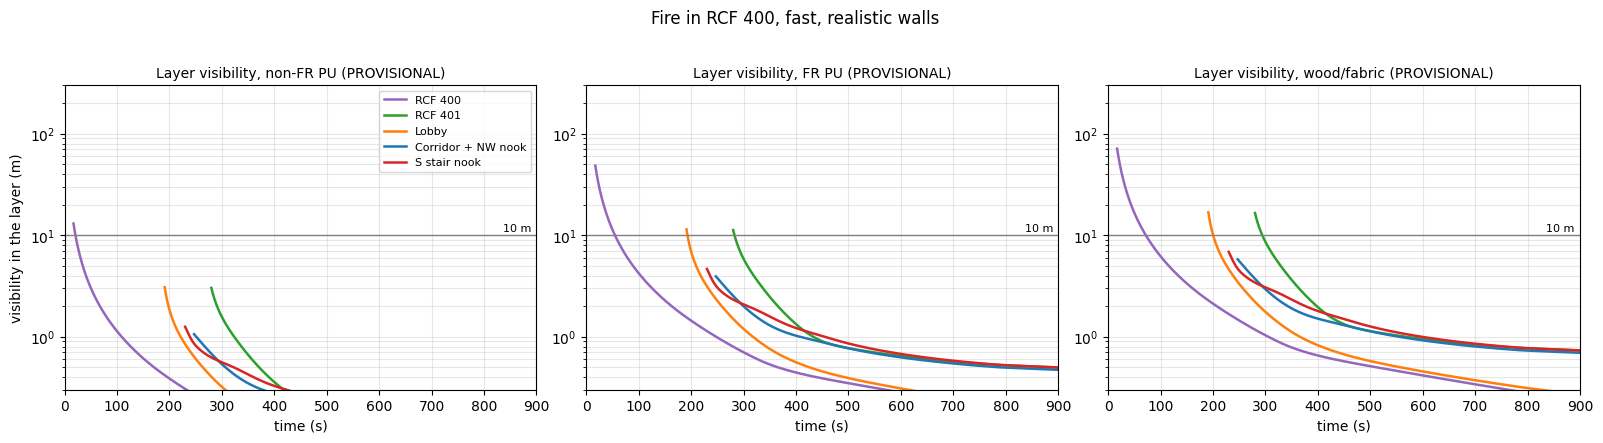

In [35]:
# --- Visibility and temperature in each zone: fire in RCF 400, fast, realistic ---
r = g3[(Z400, "realistic")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cols = {Z400: "tab:purple", Z401: "tab:green", ZLOB: "tab:orange", ZCOR: "tab:blue", ZSN: "tab:red"}
for ax, mat in zip(axes, MATERIAL_ORDER):
    k_per_P = KM * soot_per_kJ(mat)
    for zz in ZONES:
        K = k_per_P * r[zz + ":P"]
        S = np.where(K > 0, C_VIS / np.maximum(K, 1e-12), np.nan)
        S = np.where(r[zz + ":z"] < r["H"][zz] - 0.05, S, np.nan)   # only once a layer exists
        ax.plot(r["t"], S, color=cols[zz], lw=1.8, label=zz)
    ax.axhline(VIS_LIMIT, color="gray", lw=1); ax.text(890, VIS_LIMIT * 1.08, "10 m", ha="right", fontsize=8)
    ax.set_yscale("log"); ax.set_ylim(0.3, 300); ax.set_xlim(0, 900)
    ax.set_title(f"Layer visibility, {MAT_LABEL[mat]}{' (PROVISIONAL)' if PROVISIONAL else ''}", fontsize=10)
    ax.set_xlabel("time (s)"); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("visibility in the layer (m)"); axes[0].legend(fontsize=8)
plt.suptitle("Fire in RCF 400, fast, realistic walls", y=1.02)
plt.tight_layout(); plt.show()

### 4.3 Downstream conservatism: v4 against CFAST, on untenability

The Gate 3 CFAST runs (five zones, cited leakage, closed stair doors) carry a soot yield for the non-FR PU material, so CFAST reports the upper-layer optical density in every zone. CFAST's optical density is decadic (Tech. Ref. eq. 6.3: D_u = Km m_s / ln 10), so the extinction coefficient is K = ln(10) x D_u. The same three criteria are then applied to CFAST's interface height, layer temperature and K.

For the other two materials, CFAST's soot concentration is scaled by the ratio of soot per unit heat (y_s / dH_c) between that material and the non-FR PU run. This is exact for a passive tracer; in CFAST, soot also absorbs radiation and slightly changes layer temperature, which the scaling ignores (a small effect at these temperatures).

**Rule (conservative principle, per the author's Gate 3 condition).** For every zone, scenario and material: **ASET = the earlier of v4's and CFAST's untenable times.** The table records which model governs.

In [36]:
CF_REF = {"soot_yield": CF_SOOT, "hoc_kJ": CF_HOC}

def cfast_zone_tenability(cf, material):
    scale = soot_per_kJ(material) / (CF_REF["soot_yield"] / CF_REF["hoc_kJ"])
    out = {}
    for zz in ZONES:
        n = CF_COL[zz]
        K = math.log(10) * cf[f"ULOD_{n}"].to_numpy() * scale
        out[zz] = tenability(cf["Time"].to_numpy(), cf[f"HGT_{n}"].to_numpy(),
                             cf[f"ULT_{n}"].to_numpy(), K)
    return out

def combined_aset(res, cf, material):
    # Per zone: (ASET, criterion, governing model) using the earlier of v4 and CFAST.
    v, c = v4_zone_tenability(res, material), cfast_zone_tenability(cf, material)
    out = {}
    for zz in ZONES:
        tv, cv, _ = v[zz]; tc, cc, _ = c[zz]
        tv_ = tv if not np.isnan(tv) else np.inf
        tc_ = tc if not np.isnan(tc) else np.inf
        if tc_ < tv_:
            out[zz] = (tc, " & ".join(cc), "CFAST", tv, tc)
        else:
            out[zz] = (tv, " & ".join(cv) if cv else "-", "v4", tv, tc)
    return out

rows = []
for (origin, tag), r in g3.items():
    for mat in MATERIAL_ORDER:
        comb = combined_aset(r, cf3[(origin, tag)], mat)
        for zz in ZONES:
            aset, crit, gov, tv, tc = comb[zz]
            rows.append({"fire in": origin, "walls": tag, "material": MAT_LABEL[mat], "zone": zz,
                         "v4 (s)": tv, "CFAST (s)": tc, "v4 - CFAST (s)": tv - tc,
                         "ASET used (s)": aset, "governs": gov, "criterion": crit})
cmp_df = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print("UNTENABLE TIME BY ZONE: v4 vs CFAST (fast fire)" + PROV_TAG)
print(cmp_df.to_string(index=False, float_format=lambda v: f"{v:.0f}"))
later = cmp_df[cmp_df["governs"] == "CFAST"]
print(f"\nCFAST earlier than v4 in {len(later)} of {len(cmp_df)} zone-cases; "
      f"largest correction {later['v4 - CFAST (s)'].max():.0f} s" if len(later) else "\nv4 never later than CFAST")
print(later.groupby(["walls", "zone"]).size().to_string())

UNTENABLE TIME BY ZONE: v4 vs CFAST (fast fire)  [PROVISIONAL: uses unverified material values]
fire in     walls    material               zone  v4 (s)  CFAST (s)  v4 - CFAST (s)  ASET used (s) governs                           criterion
RCF 400 adiabatic   non-FR PU            RCF 400     181        174               7            174   CFAST height + 60 C & height + visibility
RCF 400 adiabatic   non-FR PU            RCF 401     322        308              14            308   CFAST height + 60 C & height + visibility
RCF 400 adiabatic   non-FR PU              Lobby     251        228              23            228   CFAST height + 60 C & height + visibility
RCF 400 adiabatic   non-FR PU Corridor + NW nook     271        244              27            244   CFAST height + 60 C & height + visibility
RCF 400 adiabatic   non-FR PU       S stair nook     251        190              61            190   CFAST                 height + visibility
RCF 400 adiabatic       FR PU            RCF 4

### 4.4 Coupling occupants to the zones

The v3 occupant rules are kept (Weibull pre-movement with shape 1.8 and scale 35 s, imposed 50/50 stair split, 0.8 persons/s stair doors, cellular flame region, flame-contact casualties, 1 m radiant standoff, re-planning every 10 s). v3's cellular smoke is gone; the zones now carry the smoke. New rules:

- **Untenable zone casualties.** Every occupant inside a zone at the moment it becomes untenable, and anyone who is in it at any later second, becomes a casualty. **Conservative:** in reality an occupant who has just walked in might walk back out. Untenable status is checked at the start of each 1 s step, so someone who steps into an untenable zone becomes a casualty at the next step.
- **Routing around untenable zones.** Distance fields are computed twice: a *safe* field that treats burning cells and every untenable zone as walls, and a *fallback* field that blocks only burning cells. Occupants follow the safe field whenever their position is on it, and use the fallback (walking into an untenable zone) only when no safe route exists. Fields are recomputed immediately when a zone becomes untenable, and every 10 s for fire spread, as in v3.
- **Pre-movement cue.** When the origin room's interface drops below its door soffit (2.13 m), every occupant still in pre-movement **in that room** starts moving. `# ASSUMPTION` (author's choice): that is when smoke visibly spills into the lobby; it is conservative because it is late. Occupants elsewhere keep their Weibull delays.
- **Smoke slowdown.** An occupant in a zone whose interface is below 1.8 m moves only every other second (half speed). **Conservative.**
- **RSET per zone** is the last second at which a living occupant was present in the zone, recorded at the start of each step (so someone who dies when the zone turns untenable counts as present at that moment, and the margin is zero or negative, a failure). **Margin = ASET - RSET.**

The smoke model does not depend on where in the room the fire starts, only on which room, so the smoke and the ASET table are computed once per origin room and shared by every seed.

In [37]:
# ============================================================
# 4.4 OCCUPANTS AND MODEL
# ============================================================
from collections import Counter
REROUTE_INTERVAL = 10          # s, as v3
DOOR_FLOW = 0.8                # persons/s per stair door, as v2/v3
CUE_LAYER_HEIGHT = DOOR_SOFFIT # m, ASSUMPTION: origin-room cue when layer passes the door head
ZONE_CELLSET = {zz: frozenset(ZONE_CELLS[zz]) for zz in ZONES}

class Occupant(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.state = "moving"                     # moving | escaped | casualty
        self.reaction_delay = int(self.random.weibullvariate(35.0, 1.8))
        self.steps_waited = 0
        self.target_stair = "stair3"
        self._skip = False

    def step(self):
        m = self.model
        if self.state != "moving":
            return
        zone = CELL_ZONE.get(self.pos)
        # Cue: origin-room layer below the door head ends pre-movement in that room.
        if zone == m.origin_room and m.zone_z(m.origin_room) < CUE_LAYER_HEIGHT:
            self.steps_waited = max(self.steps_waited, self.reaction_delay)
        if self.steps_waited < self.reaction_delay:
            self.steps_waited += 1
            return
        # Smoke slowdown: interface below 1.8 m in my zone -> act every other second.
        if zone is not None and m.zone_z(zone) < LEVEL_TEN:
            self._skip = not self._skip
            if self._skip:
                return
        # Escape through my stair door (door budget throttle, as v3).
        if self.pos in exits and m.cell_to_door.get(self.pos) == self.target_stair:
            door = self.target_stair
            if m.door_budget[door] >= 1.0:
                m.door_budget[door] -= 1.0
                self.state = "escaped"
                m.escaped_count += 1
                m.door_escape_count[door] += 1
                m.grid.remove_agent(self)
            return
        field = m.field_for(self)
        if field is None:
            return
        neighbors = m.grid.get_neighborhood(self.pos, moore=True, include_center=False)
        candidates = [c for c in neighbors if c in field and c not in m.burning]
        if not candidates:
            return
        my_dist = field.get(self.pos, float("inf"))
        safe = [c for c in candidates if c not in m.fire_halo]
        for pool in (safe, candidates):            # radiant standoff first (v3)
            if pool:
                best = min(pool, key=lambda c: field[c])
                if field[best] < my_dist:
                    m.grid.move_agent(self, best)
                    return


class RCFTenabilityModel(mesa.Model):
    def __init__(self, n_400, n_401, smoke_by_room, aset_by_room, seed=None):
        super().__init__(rng=seed)     # Mesa 3.5: 'rng' replaces the deprecated 'seed' keyword
        self.grid = mesa.space.MultiGrid(WIDTH, HEIGHT, torus=False)
        # Fire origin random in the assembly rooms (v3); smoke + ASET follow the room.
        self.fire_origin = self.random.choice(sorted(spawn400 | spawn401))
        self.origin_room = Z400 if self.fire_origin in spawn400 else Z401
        self.smoke = smoke_by_room[self.origin_room]
        self.aset = aset_by_room[self.origin_room]          # zone -> (time, criterion, model)
        self.burning = {self.fire_origin}
        self.fire_halo = self._halo()
        self.stair_cells = {"stair2": {c for c in exits if c[1] < 30},
                            "stair3": {c for c in exits if c[1] >= 30}}
        self.cell_to_door = {c: ("stair2" if c[1] < 30 else "stair3") for c in exits}
        self.untenable = set()
        self.zone_untenable_at = {}
        self._recompute_fields()
        self.door_budget = {"stair2": 0.0, "stair3": 0.0}
        self.door_escape_count = {"stair2": 0, "stair3": 0}
        self.escaped_count = 0
        self.casualty_count = 0
        self.casualty_cause = Counter()
        self.total_occupants = n_400 + n_401
        self.step_num = 0
        self.zone_last_present = {zz: np.nan for zz in ZONES}
        self.zone_initial = Counter()
        s400 = sorted(spawn400 - self.burning); s401 = sorted(spawn401 - self.burning)
        placed = []
        for n, cells in ((n_400, s400), (n_401, s401)):
            for _ in range(n):
                a = Occupant(self)
                self.grid.place_agent(a, self.random.choice(cells))
                placed.append(a)
        # Imposed 50/50 split, as v2/v3 (farthest from Stair 3 go to Stair 2).
        d3 = compute_distance_field(walkable, self.stair_cells["stair3"])
        placed.sort(key=lambda a: d3.get(a.pos, 0), reverse=True)
        for i, a in enumerate(placed):
            a.target_stair = "stair2" if i < len(placed) // 2 else "stair3"
            self.zone_initial[CELL_ZONE[a.pos]] += 1
        self.datacollector = mesa.DataCollector(
            model_reporters={"Escaped": "escaped_count", "Casualties": "casualty_count"})

    # ---- helpers ----
    def zone_z(self, zz):
        i = min(self.step_num, len(self.smoke["t"]) - 1)
        return self.smoke[zz + ":z"][i]

    def _halo(self):
        h = set(self.burning)
        for (cx, cy) in self.burning:
            for dx, dy in SPREAD_DIRS:
                h.add((cx + dx, cy + dy))
        return h

    def _recompute_fields(self):
        open_cells = walkable - self.burning
        bad = set().union(*(ZONE_CELLSET[zz] for zz in self.untenable)) if self.untenable else set()
        safe_cells = open_cells - bad
        self.dist_any = {s: compute_distance_field(open_cells, c - self.burning)
                         for s, c in self.stair_cells.items()}
        self.dist_safe = {s: compute_distance_field(safe_cells, c - self.burning - bad)
                          for s, c in self.stair_cells.items()}

    def field_for(self, a):
        if a.pos in self.dist_safe[a.target_stair]:
            return self.dist_safe[a.target_stair]
        if a.pos in self.dist_any[a.target_stair]:
            return self.dist_any[a.target_stair]
        return None

    def _reassign(self):
        for a in self.agents:
            if a.state != "moving" or a.pos is None:
                continue
            other = "stair2" if a.target_stair == "stair3" else "stair3"
            if a.pos not in self.dist_safe[a.target_stair] and a.pos in self.dist_safe[other]:
                a.target_stair = other
            elif a.pos not in self.dist_any[a.target_stair] and a.pos in self.dist_any[other]:
                a.target_stair = other

    def _kill(self, a, cause):
        a.state = "casualty"
        self.casualty_count += 1
        self.casualty_cause[cause] += 1
        self.grid.remove_agent(a)

    # ---- step ----
    def step(self):
        self.step_num += 1
        t = self.step_num
        # RSET bookkeeping: who is where at the start of this second.
        for a in self.agents:
            if a.state == "moving" and a.pos is not None:
                self.zone_last_present[CELL_ZONE[a.pos]] = t
        for door in self.door_budget:
            self.door_budget[door] = min(self.door_budget[door] + DOOR_FLOW, 2.0)
        # Flame contact (v3: cells burning since last step).
        for a in [a for c in self.burning for a in self.grid.get_cell_list_contents([c])]:
            if a.state == "moving":
                self._kill(a, "flame contact")
        self.burning = spread_step(self.burning, FIRE_SPREAD_P, self.random)
        self.fire_halo = self._halo()
        # Zone tenability.
        newly = {zz for zz, v in self.aset.items()
                 if not np.isnan(v[0]) and v[0] <= t and zz not in self.untenable}
        if newly:
            self.untenable |= newly
            for zz in newly:
                self.zone_untenable_at[zz] = t
            self._recompute_fields(); self._reassign()
        if self.untenable:
            for a in list(self.agents):
                if a.state == "moving" and a.pos is not None and CELL_ZONE[a.pos] in self.untenable:
                    self._kill(a, f"untenable: {CELL_ZONE[a.pos]}")
        if t % REROUTE_INTERVAL == 0:
            self._recompute_fields(); self._reassign()
        self.datacollector.collect(self)
        self.agents.shuffle_do("step")

def run_one(seed, n_400, n_401, smoke_by_room, aset_by_room, max_steps=2000, keep_model=False):
    m = RCFTenabilityModel(n_400, n_401, smoke_by_room, aset_by_room, seed=seed)
    while (m.escaped_count + m.casualty_count) < m.total_occupants and m.step_num < max_steps:
        m.step()
    out = {"seed": seed, "origin_room": m.origin_room, "escaped": m.escaped_count,
           "casualties": m.casualty_count,
           "unresolved": m.total_occupants - m.escaped_count - m.casualty_count,
           "time": m.step_num, "cause": dict(m.casualty_cause)}
    for zz in ZONES:
        aset = m.aset[zz][0]
        rset = m.zone_last_present[zz]
        out[f"ASET|{zz}"] = aset
        out[f"RSET|{zz}"] = rset
        out[f"crit|{zz}"] = m.aset[zz][1]
        out[f"gov|{zz}"] = m.aset[zz][2]
        out[f"margin|{zz}"] = (aset if not np.isnan(aset) else np.inf) - rset if not np.isnan(rset) else np.nan
    return (out, m) if keep_model else out
print("Model defined.")

Model defined.


In [38]:
# --- Demonstration: fast fire, realistic walls, non-FR PU, Case A loads (304 / 87) ---
def aset_by_room_for(results_by_room, cf_by_room, material):
    return {room: {zz: v[:3] for zz, v in combined_aset(results_by_room[room], cf_by_room[room], material).items()}
            for room in (Z400, Z401)}

smoke_fast_real = {room: g3[(room, "realistic")] for room in (Z400, Z401)}
cf_fast_real = {room: cf3[(room, "realistic")] for room in (Z400, Z401)}
aset_demo = aset_by_room_for(smoke_fast_real, cf_fast_real, "nonFR_PU")

for seed in (42, 1):
    res, mdl = run_one(seed, 304, 87, smoke_fast_real, aset_demo, keep_model=True)
    print(f"seed {seed}: fire in {res['origin_room']} at {mdl.fire_origin}; run {res['time']} s; "
          f"escaped {res['escaped']}, casualties {res['casualties']}, unresolved {res['unresolved']}"
          f"  (total {res['escaped']+res['casualties']+res['unresolved']} = {mdl.total_occupants})"
          + PROV_TAG)
    print("   casualties by cause:", dict(sorted(res["cause"].items(), key=lambda kv: -kv[1])))
    tab = pd.DataFrame([{"zone": zz, "ASET (s)": res[f"ASET|{zz}"], "criterion": res[f"crit|{zz}"],
                         "from": res[f"gov|{zz}"], "RSET (s)": res[f"RSET|{zz}"],
                         "margin (s)": res[f"margin|{zz}"]} for zz in ZONES])
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.0f}"))
    print()

seed 42: fire in RCF 400 at (51, 44); run 298 s; escaped 377, casualties 14, unresolved 0  (total 391 = 391)  [PROVISIONAL: uses unverified material values]
   casualties by cause: {'flame contact': 8, 'untenable: S stair nook': 6}
              zone  ASET (s)           criterion  from  RSET (s)  margin (s)
           RCF 400       192 height + visibility CFAST       106          86
           RCF 401       404 height + visibility    v4        76         328
             Lobby       276 height + visibility CFAST       122         154
Corridor + NW nook       316 height + visibility CFAST       298          18
      S stair nook       246 height + visibility CFAST       246           0



seed 1: fire in RCF 401 at (26, 63); run 286 s; escaped 259, casualties 132, unresolved 0  (total 391 = 391)  [PROVISIONAL: uses unverified material values]
   casualties by cause: {'flame contact': 114, 'untenable: Corridor + NW nook': 18}
              zone  ASET (s)                           criterion  from  RSET (s)  margin (s)
           RCF 400       394 height + 60 C & height + visibility    v4        87         307
           RCF 401       122                 height + visibility CFAST        91          31
             Lobby       268 height + 60 C & height + visibility    v4        98         170
Corridor + NW nook       286                 height + visibility    v4       286           0
      S stair nook       226                 height + visibility CFAST       108         118



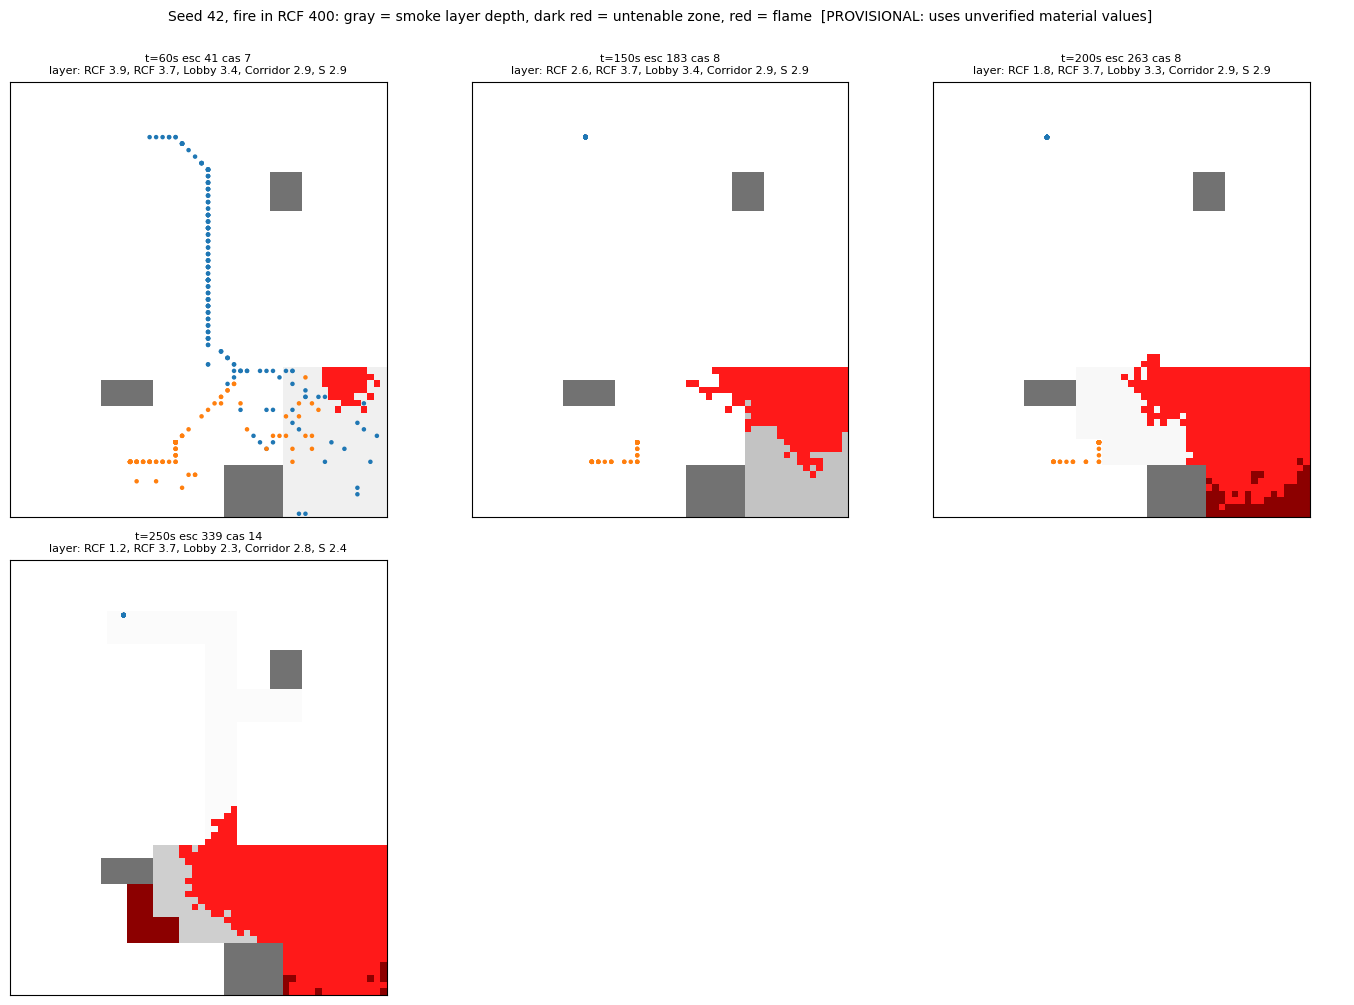

In [39]:
# --- Snapshots of one run (seed 42) ---
snap_times = [60, 150, 200, 250, 300, 400]
snap = {}
m = RCFTenabilityModel(304, 87, smoke_fast_real, aset_demo, seed=42)
while m.step_num < max(snap_times) and (m.escaped_count + m.casualty_count) < m.total_occupants:
    m.step()
    if m.step_num in snap_times:
        snap[m.step_num] = (set(m.burning), set(m.untenable),
                            {zz: m.zone_z(zz) for zz in ZONES},
                            [(a.pos, a.target_stair) for a in m.agents if a.state == "moving"],
                            m.escaped_count, m.casualty_count)
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
for ax, t in zip(axes.flat, snap_times):
    if t not in snap:
        ax.axis("off"); continue
    burn, unt, zs, ags, esc, cas = snap[t]
    img = np.ones((HEIGHT, WIDTH, 3))
    for zz in ZONES:
        H_ = ZONE_H[zz]
        depth = 1 - zs[zz] / H_                    # 0 clear, 1 full of smoke
        shade = (0.55, 0.0, 0.0) if zz in unt else tuple(1 - 0.6 * depth for _ in range(3))
        for (c, r_) in ZONE_CELLS[zz]:
            img[r_, c] = shade
    for (c, r_) in dead:
        img[r_, c] = (0.45, 0.45, 0.45)
    for (c, r_) in burn:
        img[r_, c] = (1.0, 0.1, 0.1)
    ax.imshow(img, origin="upper", interpolation="nearest")
    if ags:
        ax.scatter([p[0] for p, s_ in ags], [p[1] for p, s_ in ags], s=5,
                   c=["tab:blue" if s_ == "stair2" else "tab:orange" for p, s_ in ags])
    ax.set_title(f"t={t}s esc {esc} cas {cas}\nlayer: " +
                 ", ".join(f"{zz.split()[0]} {zs[zz]:.1f}" for zz in ZONES), fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"Seed 42, fire in {m.origin_room}: gray = smoke layer depth, dark red = untenable zone, "
             f"red = flame{PROV_TAG}", y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

### 4.5 Reading the Gate 4 results

**In plain terms: ASET here is set by how fast the smoke layer descends, not by the material.** Visibility in the layer drops below 10 m as soon as the interface reaches 1.8 m, for every material. That is a result of the physics (all three materials make the layer far too smoky to see through), not a flaw in the model.

**Visibility governs, and it governs immediately.** In every zone, for both heat loss cases and all three materials, the layer is already far too smoky to see 10 m through by the time its interface reaches 1.8 m (the table of visibility at 1.8 m above: even the least smoky material, wood, gives a few metres at most). The 60 C criterion fires as well in the fire rooms and, for a fire in RCF 401, in the lobby. With the radiant limit at 180 C, the radiant criterion fires first in only one place for the fast fire: the lobby with the fire in RCF 401 and adiabatic walls (CFAST 222 s, v4 225 s, a few seconds before the interface reaches 1.8 m). With realistic walls it never fires first. **Consequence: ASET is effectively the time for each zone's interface to reach 1.8 m, and the material scenario barely changes it in these runs.** That is a finding, not an error: a layer only needs about 3.4e-5 kg/m^3 of soot to cut visibility to 10 m (K = 3 / 10 = 0.3 1/m, divided by Km = 8700), and a room-scale fire puts far more than that into the first few hundred cubic metres of layer. Materials would matter for visibility criteria applied **below** the layer (for example, a smoke-logged lower layer) or for smaller fires, neither of which is in v4's two-layer, t-squared design.

**Downstream conservatism: CFAST governs most downstream zones.** With the cited leakage, CFAST makes a zone untenable earlier than v4 in 45 of 60 zone-cases (fast fire). The biggest corrections are in the south stair nook (31 to 61 s earlier) and in the corridor (12 to 27 s earlier); in the lobby and RCF 401 they are 3 to 23 s, and in RCF 400 7 to 8 s. Following the author's rule, **v4 now uses the earlier of the two times in every zone** (the `governs` column), so the downstream bias found in Gate 3 is removed rather than flagged. The cause is the floor pressurization explained in Gate 3, which is itself conservative. In some zones v4 is earlier than CFAST (for example RCF 400 and the lobby when the fire is in RCF 401, realistic walls), and there v4's own time is kept.

**Agent coupling works as intended** (two seeds above). In seed 42 (fire in RCF 400), occupants clear RCF 400 by 106 s and the lobby by 122 s, well before those zones become untenable (192 s and 276 s). The binding zone is the **south stair nook**: its queue is still there when it becomes untenable at 246 s, so the margin is 0 and the people still queuing become casualties. In seed 1 (fire in RCF 401, next to the south stair), flame contact dominates, as in v3, and the corridor to the northwest stair becomes the binding zone (margin 0 at 286 s, still holding the end of the Stair 2 queue). **Both stair queues end up inside zones that turn untenable while people are still waiting in them.** That is the v4 version of v2's bottleneck finding: the 32 in stair doors keep people in the nooks and corridor longer than the smoke allows.

**Checks.** The radiant check confirms that 180 C makes a zone untenable even with the interface at 3.5 m, and that a high, smoky layer alone does not. Every run reconciles: escaped + casualties + unresolved = total occupants.

**Open items from this gate** (also listed at the end of the notebook): the 1.8 m and 60 C thresholds need a primary citation (the author is checking); the radiant limit is now 180 C, the conservative end of the cited 180 to 200 C range; the wood/fabric scenario has no fabric soot data; and the FR PU yields are derived (verified = N).

## Gate 5: ASET vs RSET and the scenario matrix

### 5.1 What is being compared

- **ASET (available safe egress time)** for a zone is the moment that zone becomes untenable (Section 4.2), taken as the **earlier of v4 and CFAST** for that zone (Section 4.3).
- **RSET (required safe egress time)** for a zone is the last second a living occupant is in it (Section 4.4).
- **Margin = ASET - RSET.** A positive margin means the zone emptied before it became untenable. A margin of **zero or less is a failure**: someone was still in the zone when it became untenable. Because the model steps in whole seconds and untenable status is applied at the start of a step, an occupant caught in a zone gives a margin of exactly 0 (or slightly below 0 when ASET falls between two steps). The tables therefore report both the fraction of runs with **margin below 0** (the prompt's definition) and with **margin at or below 0** (the failure count actually used in the discussion).
- **Floor-level result.** For each run, the floor margin is the **smallest margin over the zones that held occupants**, and the zone that gives it is the **binding zone**. The floor RSET is the last second anyone living was on the floor.

### 5.2 The matrix

| Factor | Levels | Notes |
|---|---|---|
| Design fire growth | medium (0.01172 kW/s^2), fast (0.0469), ultrafast (0.1876), each capped at 5 MW | t-squared fire, Gate 1 |
| Occupant load | Case A: 304 in RCF 400, 87 in RCF 401. Case B: 200 in RCF 400, 91 in RCF 401 | see below |
| Material | non-FR PU, FR PU, wood/fabric | Section 4.1; changes ASET through visibility only |
| Heat loss | adiabatic, realistic (gypsum walls, concrete ceiling) | both run, per the author's approval |
| Ceiling height | all ceilings x 0.8, x 1.0, x 1.2 | x 0.8 and x 1.2 for the fast fire, Case A, non-FR PU only (author's choice) |

That is 3 x 2 x 3 x 2 = 36 base scenarios plus 2 x 2 = 4 ceiling scenarios, **40 scenarios x 30 seeds = 1,200 agent runs**. The smoke model and CFAST are run once per (fire growth, heat loss, ceiling, origin room), 20 runs each, to 1,500 s so that even the medium fire reaches every zone.

**Common seeds.** Every scenario uses seeds 0 to 29. The seed fixes the fire origin (drawn first, as in v3), the pre-movement delays and the starting positions, so differences between scenarios come from the factor being changed, not from different random draws. (Case B has fewer occupants, so its draws diverge from Case A's after the origin is chosen.)

**Occupant load sources.**
- **Case A, course floor plans**: RCF 400 = 4,556.59 sf (OL 304), RCF 401 = 1,290.38 sf (OL 87), from the author's ENES-250 floor plans, provided by the course professor. This is the v2 and v3 basis.
- **Case B, published areas**: RCF 400 = 2,998 sf and RCF 401 = 1,369 sf, from Howard Community College's naming-opportunities page (https://www.howardcc.edu/donors-alumni-and-friends/support-hcc-students/naming-opportunities/rouse-company-foundation-student-services-hall/), which also lists a 1,443 sf wrap-around balcony and a 1,370 sf lobby. At 15 sf per person (unconcentrated assembly, as in v2): 2,998 / 15 = 200 and 1,369 / 15 = 91. Two further public sources broadly agree: HCC's venue page (https://howardcc.edu/services--support/event-and-conference-center/multipurpose-venues/) lists the RCF 400 auditorium at 200 and RCF 401 at 60, and a 2006 Penn State architectural engineering thesis on the building (https://engr.psu.edu/ae/thesis/portfolios/2006/jpf161/FAIR_TECH_1.pdf and https://engr.psu.edu/ae/thesis/portfolios/2006/jpf161/FAIR_Tech2.pdf) lists 2,995 sf (200 occupants) and 1,360 sf (90 occupants). (These figures are as given in the author's brief.)
- **The discrepancy is an input uncertainty, not an error.** 2,998 + 1,443 = 4,441 sf, close to the course figure of 4,556.59 sf, so the course plans probably include the balcony. If the balcony is occupiable and its occupants egress through the fourth-floor lobby, counting them (Case A) is defensible; v4 does not know which is true and so runs both. Case B's 200 occupants are spawned in the existing RCF 400 spawn cells; the geometry is not redrawn. Case B has **more** people in RCF 401 than Case A (91 against 87), because Case B uses the published RCF 401 area.

**Ceiling sensitivity.** Scaling a ceiling changes the room volume, the plume height (so its entrainment), and the passage soffits, which follow the ceilings. The door heads stay at 2.13 m, and the 1.8 m tenability height stays at 1.8 m, because it is set by the occupants, not the room.

In [40]:
# ============================================================
# 5.2 SMOKE AND CFAST RUNS FOR THE MATRIX
# ============================================================
import time as _time
T_END_G5 = 1500
GROWTHS = ("medium", "fast", "ultrafast")
WALLS = ("adiabatic", "realistic")
CEIL_SCALES = (0.8, 1.2)            # fast fire, Case A, non-FR PU only
SEEDS = list(range(30))
LOADS = {"A": (304, 87), "B": (200, 91)}

smoke5, cf5 = {}, {}
_t0 = _time.time()
for growth in GROWTHS:
    for tag in WALLS:
        for cs in ((1.0,) + CEIL_SCALES if growth == "fast" else (1.0,)):
            for origin in (Z400, Z401):
                key = (growth, tag, cs, origin)
                smoke5[key] = run_smoke(origin, ALPHA[growth], heat_loss=(tag == "realistic"),
                                        t_end=T_END_G5, ceil_scale=cs)
                name = f"g5_{CF_ID[origin].lower()}_{growth}_{tag}" + ("" if cs == 1.0 else f"_ceil{round(cs*100):03d}")
                write_cfast_multizone(name, origin, ALPHA[growth], tag == "realistic",
                                      t_end=T_END_G5, ceil_scale=cs)
                cf5[key] = run_cfast(name)
print(f"{len(smoke5)} smoke runs and {len(cf5)} CFAST runs in {_time.time() - _t0:.0f} s")
short = [k for k, cf in cf5.items() if cf["Time"].iloc[-1] < T_END_G5 - 5]
assert not short, f"CFAST output ends early for {short}"
print(f"Every CFAST run reaches {T_END_G5} s (last output row within 5 s of the end).")

# Time each zone's interface reaches 1.8 m: v4 and CFAST
rows = []
for (growth, tag, cs, origin), r in smoke5.items():
    cf = cf5[(growth, tag, cs, origin)]
    row = {"growth": growth, "walls": tag, "ceil": f"x{cs:.1f}", "fire in": origin}
    for zz in ZONES:
        row[f"{zz} v4"] = time_to(r["t"], r[zz + ":z"], LEVEL)
        row[f"{zz} CF"] = time_to(cf["Time"].to_numpy(), cf[f"HGT_{CF_COL[zz]}"].to_numpy(), LEVEL)
    rows.append(row)
t18_df = pd.DataFrame(rows)
print("\nTime (s) for each zone's interface to reach 1.8 m, v4 and CFAST (NaN = not within 1,500 s)")
print(t18_df.to_string(index=False, float_format=lambda v: f"{v:.0f}"))

20 smoke runs and 20 CFAST runs in 24 s
Every CFAST run reaches 1500 s (last output row within 5 s of the end).

Time (s) for each zone's interface to reach 1.8 m, v4 and CFAST (NaN = not within 1,500 s)
   growth     walls ceil fire in  RCF 400 v4  RCF 400 CF  RCF 401 v4  RCF 401 CF  Lobby v4  Lobby CF  Corridor + NW nook v4  Corridor + NW nook CF  S stair nook v4  S stair nook CF
   medium adiabatic x1.0 RCF 400         264         258         463         436       374       340                    390                    344              374              262
   medium adiabatic x1.0 RCF 401         448         446         168         166       336       362                    343                    314              336              310
   medium realistic x1.0 RCF 400         288         280         566         590       426       408                    463                    448              426              350
   medium realistic x1.0 RCF 401         547         628         177    

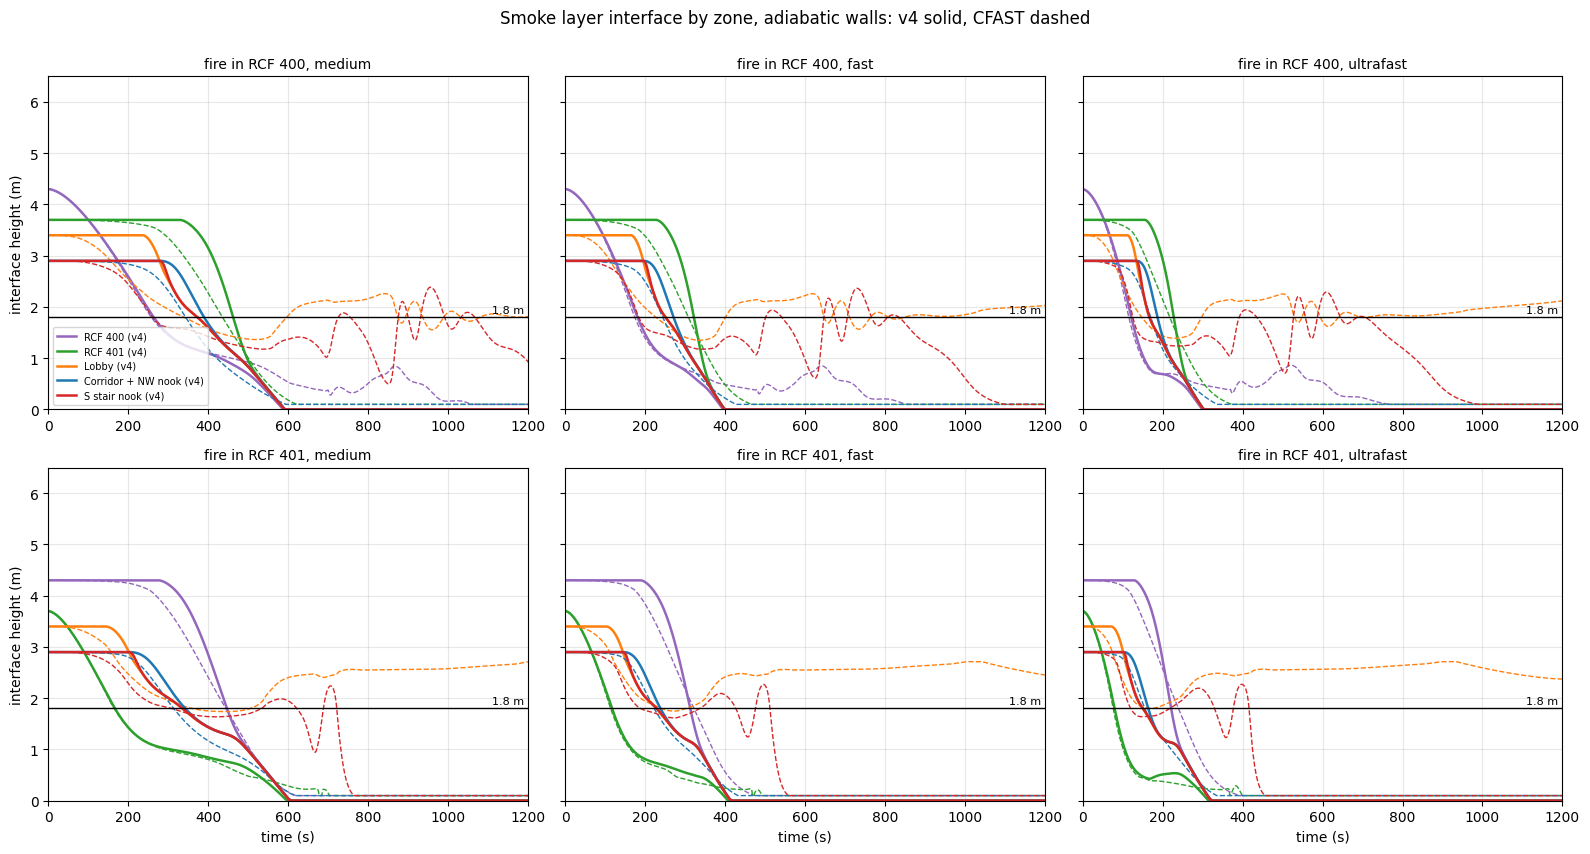

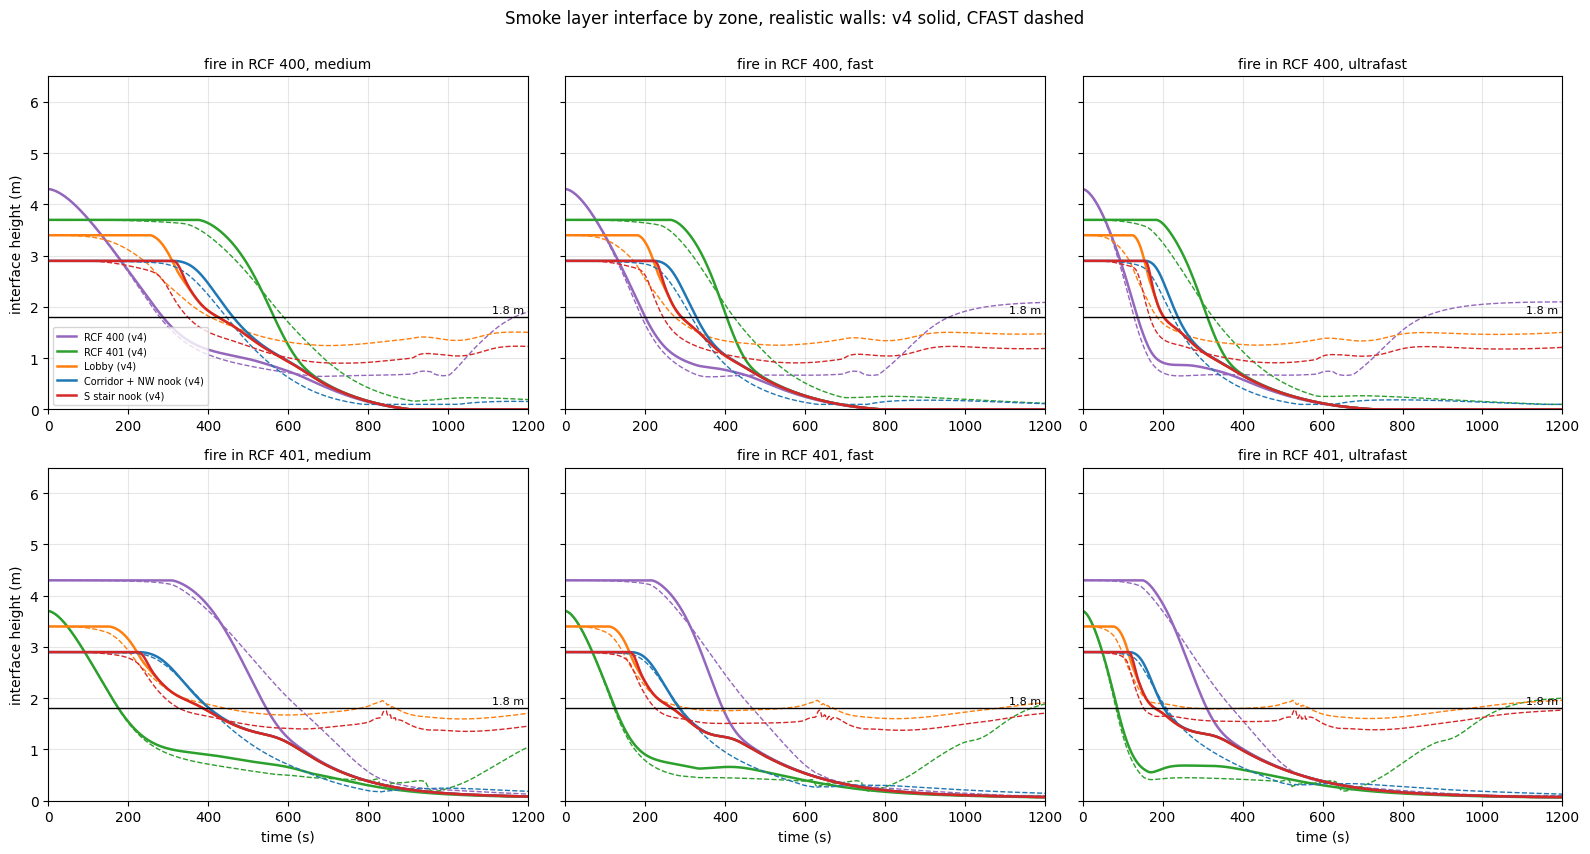

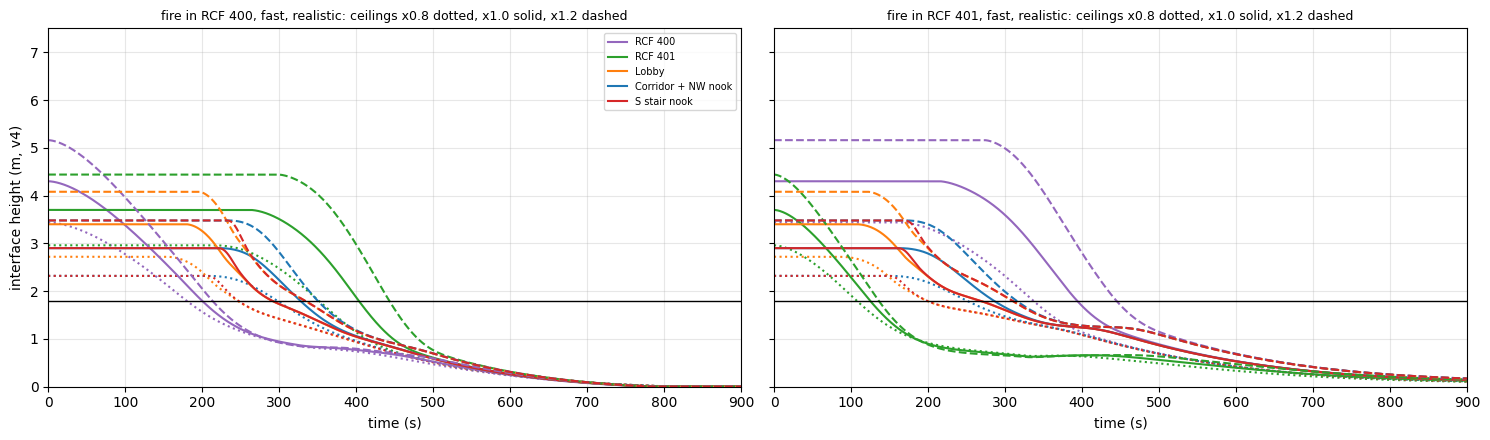

In [41]:
# --- Layer height in every zone, v4 (solid) and CFAST (dashed), ceilings x 1.0 ---
zcols = {Z400: "tab:purple", Z401: "tab:green", ZLOB: "tab:orange", ZCOR: "tab:blue", ZSN: "tab:red"}
for tag in WALLS:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
    for i, origin in enumerate((Z400, Z401)):
        for j, growth in enumerate(GROWTHS):
            ax = axes[i, j]
            r = smoke5[(growth, tag, 1.0, origin)]; cf = cf5[(growth, tag, 1.0, origin)]
            for zz in ZONES:
                ax.plot(r["t"], r[zz + ":z"], color=zcols[zz], lw=1.8, label=f"{zz} (v4)")
                ax.plot(cf["Time"], cf[f"HGT_{CF_COL[zz]}"], color=zcols[zz], lw=1.0, ls="--")
            ax.axhline(LEVEL, color="black", lw=1)
            ax.text(1190, LEVEL + 0.08, "1.8 m", ha="right", fontsize=8)
            ax.set_xlim(0, 1200); ax.set_ylim(0, 6.5); ax.grid(alpha=0.3)
            ax.set_title(f"fire in {origin}, {growth}", fontsize=10)
            if i == 1: ax.set_xlabel("time (s)")
            if j == 0: ax.set_ylabel("interface height (m)")
    axes[0, 0].legend(fontsize=7, loc="lower left")
    plt.suptitle(f"Smoke layer interface by zone, {tag} walls: v4 solid, CFAST dashed", y=1.0)
    plt.tight_layout(); plt.show()

# --- Ceiling sensitivity: fast fire, realistic walls ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, origin in zip(axes, (Z400, Z401)):
    for cs, ls in ((0.8, ":"), (1.0, "-"), (1.2, "--")):
        r = smoke5[("fast", "realistic", cs, origin)]
        for zz in ZONES:
            ax.plot(r["t"], r[zz + ":z"], color=zcols[zz], lw=1.5, ls=ls,
                    label=f"{zz}" if cs == 1.0 else None)
    ax.axhline(LEVEL, color="black", lw=1)
    ax.set_xlim(0, 900); ax.set_ylim(0, 7.5); ax.grid(alpha=0.3)
    ax.set_title(f"fire in {origin}, fast, realistic: ceilings x0.8 dotted, x1.0 solid, x1.2 dashed", fontsize=9)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("interface height (m, v4)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5.3 Running the 1,200 agent runs

For each scenario, the ASET table (earlier of v4 and CFAST, per zone, for that material) is built once per origin room, and the 30 seeds are run against it. Every run is saved to `results/gate5_runs.csv` (one row per run, with ASET, RSET, margin, criterion and governing model per zone) so that the Gate 6 dashboard can read the results without rerunning them.

In [42]:
# ============================================================
# 5.3 AGENT RUNS
# ============================================================
SCEN = []
for growth in GROWTHS:
    for case in ("A", "B"):
        for mat in MATERIAL_ORDER:
            for tag in WALLS:
                SCEN.append({"growth": growth, "case": case, "material": mat, "walls": tag, "ceil": 1.0})
for cs in CEIL_SCALES:
    for tag in WALLS:
        SCEN.append({"growth": "fast", "case": "A", "material": "nonFR_PU", "walls": tag, "ceil": cs})

def scen_label(s):
    return f"{s['growth']:9s} {s['case']} {MAT_LABEL[s['material']]:11s} ceil x{s['ceil']:.1f}"

run_rows = []
_t0 = _time.time()
for s in SCEN:
    sm = {o: smoke5[(s["growth"], s["walls"], s["ceil"], o)] for o in (Z400, Z401)}
    cf = {o: cf5[(s["growth"], s["walls"], s["ceil"], o)] for o in (Z400, Z401)}
    aset = aset_by_room_for(sm, cf, s["material"])
    n4, n1 = LOADS[s["case"]]
    for seed in SEEDS:
        out = run_one(seed, n4, n1, sm, aset, max_steps=T_END_G5)
        cause = out.pop("cause")
        out["cas_flame"] = cause.get("flame contact", 0)
        out["cas_smoke"] = out["casualties"] - out["cas_flame"]
        for zz in ZONES:
            out[f"cas|{zz}"] = cause.get(f"untenable: {zz}", 0)
        out.update(s); out["scenario"] = scen_label(s)
        run_rows.append(out)
runs5 = pd.DataFrame(run_rows)
print(f"{len(runs5)} agent runs in {_time.time() - _t0:.0f} s")

# Floor-level result per run: binding zone = occupied zone with the smallest margin.
def floor_row(r):
    best, bz = np.inf, None
    for zz in ZONES:
        if np.isnan(r[f"RSET|{zz}"]):
            continue
        mg = r[f"margin|{zz}"]
        if mg < best:
            best, bz = mg, zz
    rset = np.nanmax([r[f"RSET|{zz}"] for zz in ZONES])
    return pd.Series({"floor_margin": best, "binding_zone": bz, "floor_RSET": rset,
                      "floor_ASET": r[f"ASET|{bz}"] if bz else np.nan})
runs5 = pd.concat([runs5, runs5.apply(floor_row, axis=1)], axis=1)

# Accounting check on every run.
bad = runs5[runs5.escaped + runs5.casualties + runs5.unresolved != np.where(runs5.case == "A", 391, 291)]
print(f"Runs where escaped + casualties + unresolved != occupants: {len(bad)}")
print(f"Runs with unresolved occupants at {T_END_G5} s: {(runs5.unresolved > 0).sum()}")
print(f"Zone-runs never untenable within {T_END_G5} s: "
      f"{int(sum(runs5[f'ASET|{zz}'].isna().sum() for zz in ZONES))}")

Path("results").mkdir(exist_ok=True)
runs5.to_csv(Path("results") / "gate5_runs.csv", index=False)
print("Saved results/gate5_runs.csv" + PROV_TAG)

1200 agent runs in 480 s


Runs where escaped + casualties + unresolved != occupants: 0
Runs with unresolved occupants at 1500 s: 0
Zone-runs never untenable within 1500 s: 0
Saved results/gate5_runs.csv  [PROVISIONAL: uses unverified material values]


### 5.4 Summary tables

**Scenario x zone.** Mean ASET, mean RSET, mean margin, the fraction of the 30 runs with margin below 0 and at or below 0, and the mean number of casualties **in that zone from untenability**. Means are over the runs in which the zone held occupants (RSET defined). Where a zone never became untenable within 1,500 s, ASET is taken as 1,500 s for the mean, a lower bound; the count is printed above. Flame-contact casualties are not tied to a smoke zone and appear in the floor table.

Values labeled PROVISIONAL use material values that are not yet verified (Section 4.1).

In [43]:
# ============================================================
# 5.4 SUMMARY: SCENARIO x ZONE
# ============================================================
SCOLS = ["growth", "case", "material", "walls", "ceil"]
long = []
for _, r in runs5.iterrows():
    for zz in ZONES:
        a = r[f"ASET|{zz}"]; rs = r[f"RSET|{zz}"]
        a_c = T_END_G5 if np.isnan(a) else a
        long.append({**{k: r[k] for k in SCOLS}, "zone": zz, "ASET": a_c, "RSET": rs,
                     "margin": (a_c - rs) if not np.isnan(rs) else np.nan,
                     "cas": r[f"cas|{zz}"], "gov": r[f"gov|{zz}"], "crit": r[f"crit|{zz}"]})
long5 = pd.DataFrame(long)
occ = long5.dropna(subset=["RSET"])
zone_sum = occ.groupby(SCOLS + ["zone"], sort=False).agg(
    runs_occupied=("RSET", "size"),
    ASET=("ASET", "mean"), RSET=("RSET", "mean"), margin=("margin", "mean"),
    P_neg=("margin", lambda m: (m < 0).mean()), P_fail=("margin", lambda m: (m <= 0).mean()),
    cas=("cas", "mean")).reset_index()
zone_sum["material"] = zone_sum["material"].map(MAT_LABEL)
zone_sum["ceil"] = zone_sum["ceil"].map(lambda c: f"x{c:.1f}")
zone_sum.to_csv(Path("results") / "gate5_summary_by_zone.csv", index=False)
pd.set_option("display.max_rows", 400)
print("SCENARIO x ZONE (means over runs where the zone held occupants)" + PROV_TAG)
print("P_neg = fraction of runs with margin < 0; P_fail = margin <= 0; cas = mean untenability casualties in the zone")
print(zone_sum.to_string(index=False, float_format=lambda v: f"{v:.2f}" if abs(v) < 1 else f"{v:.0f}"))

SCENARIO x ZONE (means over runs where the zone held occupants)  [PROVISIONAL: uses unverified material values]
P_neg = fraction of runs with margin < 0; P_fail = margin <= 0; cas = mean untenability casualties in the zone
   growth case    material     walls ceil               zone  runs_occupied  ASET  RSET  margin  P_neg  P_fail  cas
   medium    A   non-FR PU adiabatic x1.0            RCF 400             30   302   105     196   0.00    0.00 0.00
   medium    A   non-FR PU adiabatic x1.0            RCF 401             30   373    89     284   0.00    0.00 0.00
   medium    A   non-FR PU adiabatic x1.0              Lobby             30   339   113     226   0.00    0.00 0.00
   medium    A   non-FR PU adiabatic x1.0 Corridor + NW nook             30   337   293      44   0.00    0.00 0.00
   medium    A   non-FR PU adiabatic x1.0       S stair nook             30   287   220      68   0.00    0.00 0.00
   medium    A   non-FR PU realistic x1.0            RCF 400             30   342

In [44]:
# ============================================================
# 5.4 SUMMARY: FLOOR LEVEL
# ============================================================
fl = runs5.groupby(SCOLS, sort=False).agg(
    floor_ASET=("floor_ASET", "mean"), floor_RSET=("floor_RSET", "mean"),
    floor_margin=("floor_margin", "mean"),
    P_neg=("floor_margin", lambda m: (m < 0).mean()), P_fail=("floor_margin", lambda m: (m <= 0).mean()),
    binding=("binding_zone", lambda b: b.value_counts().index[0]),
    cas=("casualties", "mean"), cas_smoke=("cas_smoke", "mean"), cas_flame=("cas_flame", "mean"),
    escaped=("escaped", "mean")).reset_index()
fl["material"] = fl["material"].map(MAT_LABEL)
fl["ceil"] = fl["ceil"].map(lambda c: f"x{c:.1f}")
fl.to_csv(Path("results") / "gate5_summary_floor.csv", index=False)
print("FLOOR LEVEL (30 runs per scenario)" + PROV_TAG)
print("binding = zone that most often sets the floor margin")
print(fl.to_string(index=False, float_format=lambda v: f"{v:.2f}" if abs(v) < 1 else f"{v:.0f}"))

print("\nGoverning criterion and model for the zone ASETs used (all scenarios, both origins):")
gc = long5.drop_duplicates(SCOLS + ["zone", "ASET"]).groupby(["crit", "gov"]).size()
print(gc.to_string())

FLOOR LEVEL (30 runs per scenario)  [PROVISIONAL: uses unverified material values]
binding = zone that most often sets the floor margin
   growth case    material     walls ceil  floor_ASET  floor_RSET  floor_margin  P_neg  P_fail            binding  cas  cas_smoke  cas_flame  escaped
   medium    A   non-FR PU adiabatic x1.0         294         293            30   0.00    0.00       S stair nook   36       0.00         36      355
   medium    A   non-FR PU realistic x1.0         317         293           103   0.00    0.00       S stair nook   36       0.00         36      355
   medium    A       FR PU adiabatic x1.0         333         293            43   0.00    0.00 Corridor + NW nook   36       0.00         36      355
   medium    A       FR PU realistic x1.0         317         293           103   0.00    0.00       S stair nook   36       0.00         36      355
   medium    A wood/fabric adiabatic x1.0         344         293            54   0.00    0.00 Corridor + NW nook 

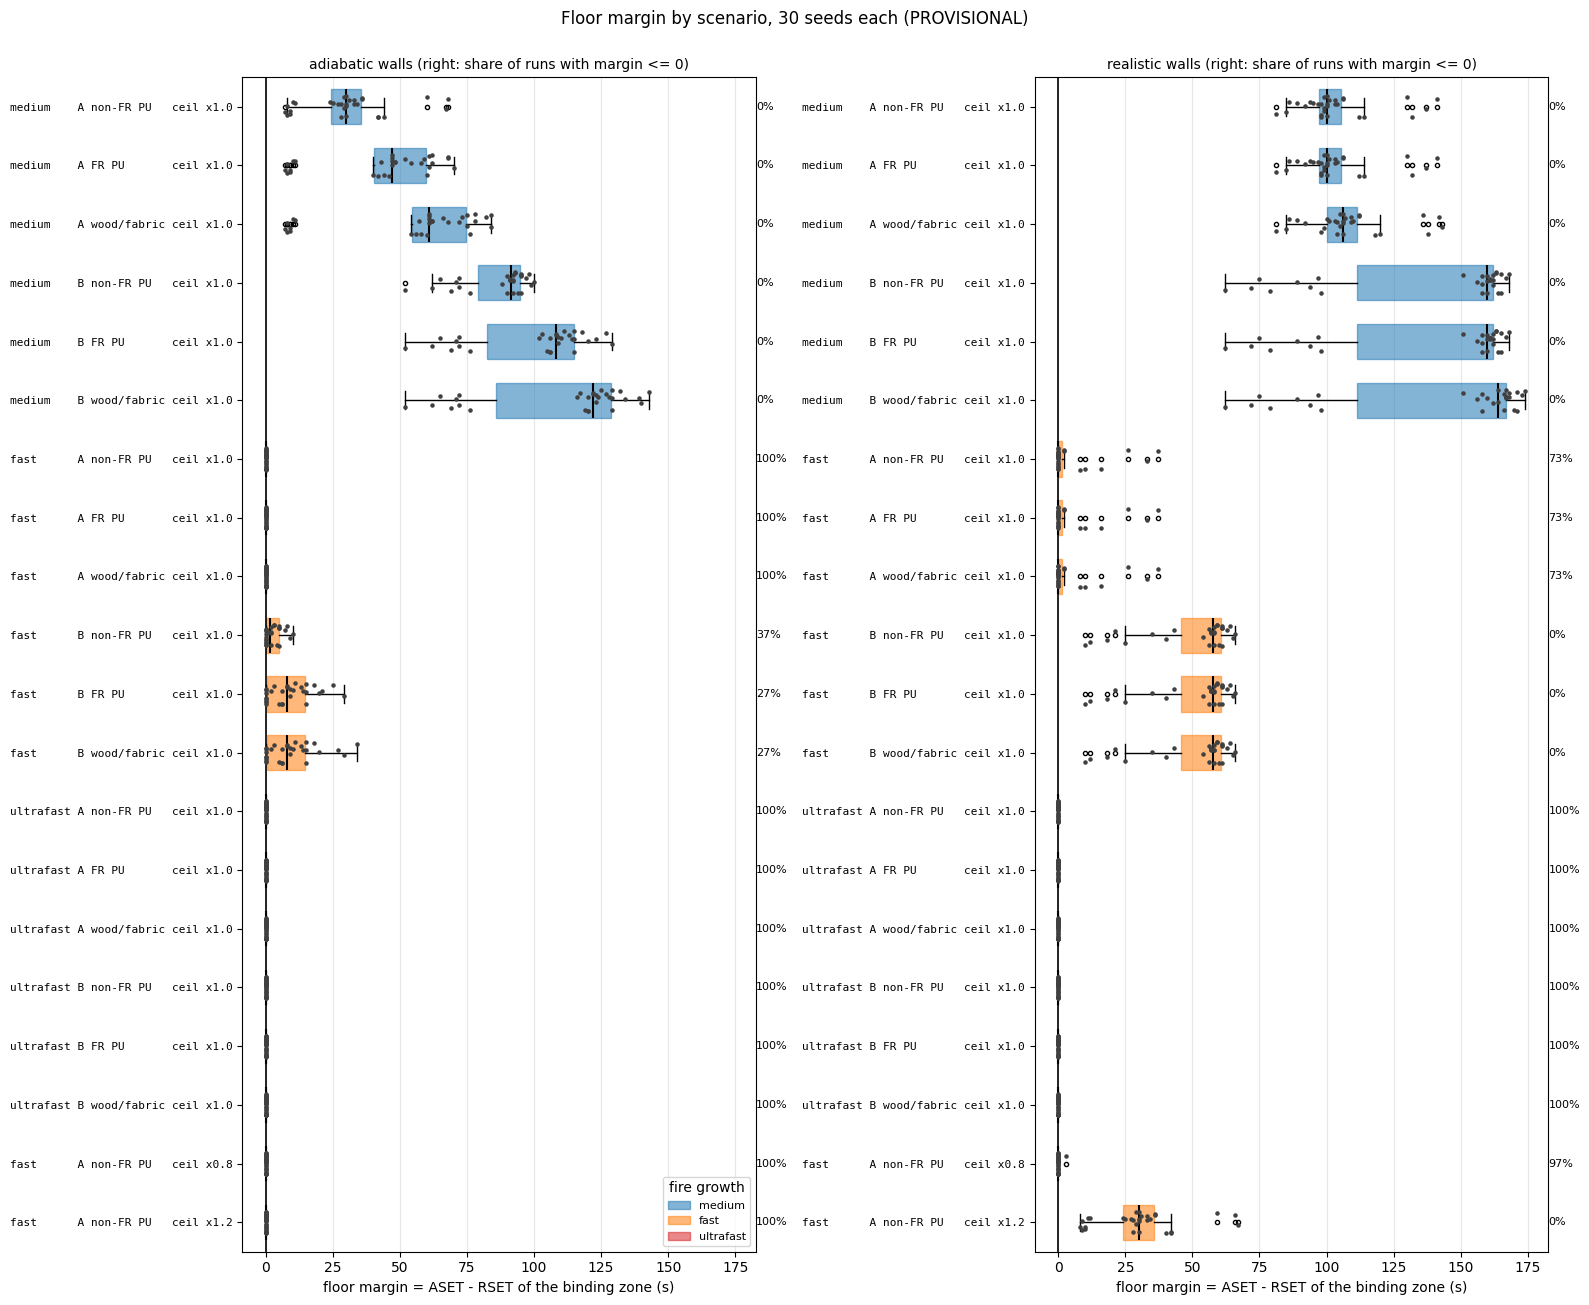

In [45]:
# ============================================================
# 5.5 MARGIN BY SCENARIO
# ============================================================
gcol = {"medium": "tab:blue", "fast": "tab:orange", "ultrafast": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(16, 13), sharex=True)
for ax, tag in zip(axes, WALLS):
    sub = [s for s in SCEN if s["walls"] == tag]
    data, labels, colors, fails = [], [], [], []
    for s in sub:
        sel_ = runs5[(runs5.growth == s["growth"]) & (runs5.case == s["case"]) &
                     (runs5.material == s["material"]) & (runs5.walls == tag) & (runs5.ceil == s["ceil"])]
        data.append(sel_.floor_margin.clip(upper=T_END_G5).to_numpy())
        labels.append(scen_label(s)); colors.append(gcol[s["growth"]])
        fails.append((sel_.floor_margin <= 0).mean())
    pos = np.arange(len(data))[::-1]
    bp = ax.boxplot(data, positions=pos, vert=False, widths=0.6, patch_artist=True,
                    medianprops={"color": "black", "lw": 1.5}, flierprops={"markersize": 3})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor(c)
    for p_, d in zip(pos, data):
        ax.scatter(d, p_ + np.random.default_rng(0).uniform(-0.18, 0.18, len(d)), s=5, color="0.25", zorder=3)
    for p_, f in zip(pos, fails):
        ax.text(1.0, p_, f"{f:.0%}", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8)
    ax.axvline(0, color="black", lw=1.2)
    ax.set_yticks(pos); ax.set_yticklabels(labels, fontsize=8, family="monospace")
    ax.set_xlabel("floor margin = ASET - RSET of the binding zone (s)")
    ax.set_title(f"{tag} walls (right: share of runs with margin <= 0)", fontsize=10)
    ax.grid(axis="x", alpha=0.3)
handles = [Patch(color=c, alpha=0.55, label=g) for g, c in gcol.items()]
axes[0].legend(handles=handles, title="fire growth", fontsize=8, loc="lower right")
plt.suptitle("Floor margin by scenario, 30 seeds each" + (" (PROVISIONAL)" if PROVISIONAL else ""), y=1.0)
plt.tight_layout(); plt.show()

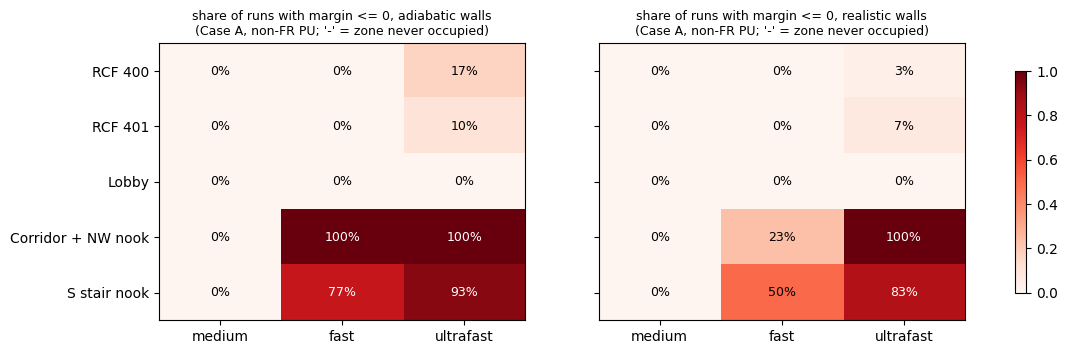

In [46]:
# --- Margin by zone: Case A, non-FR PU, ceilings x1.0 (failure share in each cell) ---
sub = zone_sum[(zone_sum.case == "A") & (zone_sum.material == "non-FR PU") & (zone_sum.ceil == "x1.0")]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, tag in zip(axes, WALLS):
    piv = sub[sub.walls == tag].pivot(index="zone", columns="growth", values="P_fail").reindex(
        index=list(ZONES), columns=list(GROWTHS))
    im = ax.imshow(piv.to_numpy(), cmap="Reds", vmin=0, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(piv.to_numpy()):
        ax.text(j, i, "-" if np.isnan(v) else f"{v:.0%}", ha="center", va="center",
                color="white" if (not np.isnan(v) and v > 0.6) else "black", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(GROWTHS); ax.set_yticks(range(len(ZONES))); ax.set_yticklabels(ZONES)
    ax.set_title(f"share of runs with margin <= 0, {tag} walls\n(Case A, non-FR PU; '-' = zone never occupied)", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 5.6 Reading the Gate 5 results

All results are **PROVISIONAL** (unverified material values, the 1.8 m and 60 C thresholds, and the estimated door soffit). Headline numbers below are for Case A, non-FR PU, ceilings x1.0 unless stated; "failure" means floor margin at or below 0, that is, at least one occupant was still in a zone when it became untenable.

**1. Growth rate decides the outcome.**

| Fire (Case A, non-FR PU) | Failure share, adiabatic | Failure share, realistic | Mean smoke casualties (adiabatic / realistic) |
|---|---|---|---|
| medium | 0% (mean floor margin 30 s) | 0% (103 s) | 0 / 0 |
| fast | 100% | 73% | 79 / 6 |
| ultrafast | 100% | 100% | 186 / 109 |

With the medium fire every zone empties before it becomes untenable. With the fast fire the result depends on heat loss: with adiabatic walls every run fails, and with realistic walls about three runs in four leave someone at the tail of a stair queue (mean 6 smoke casualties). The ultrafast fire fails in every run.

**2. The binding zones are the two stair queues, not the assembly rooms.** RCF 400, RCF 401 and the lobby empty well before they become untenable (mean margins of 42 s or more in every scenario; a single Case B fast-fire run caught one occupant in RCF 400). The floor margin is set by the **corridor and NW nook** (the Stair 2 queue) or the **south stair nook** (the Stair 3 queue). Floor RSET is about 290 s for Case A and about 235 s for Case B, and it is set by the stair doors: 391 people through two doors at 0.8 persons/s each takes about 245 s of door time, plus pre-movement. Those queues sit in zones that the smoke reaches **last**, but they are still there when it does. This is the v4 version of the v2 bottleneck finding: the 32 in stair doors, not the room exits, decide whether the floor is tenable for long enough.

**3. Why failures show a margin of exactly 0, and P_neg is always 0.** An occupant still in a zone when it turns untenable becomes a casualty at that step, and their RSET is that step, so the zone margin is 0, not negative. Failures therefore appear as margin = 0 (P_fail), and P_neg (the prompt's margin < 0) is 0 by construction. Read P_fail as the failure rate.

**4. Occupant load.** Case B (291 people) does better than Case A (391): the fast fire with realistic walls goes from 73% failure to 0% (mean margin 50 s), and with adiabatic walls from 100% to 27 to 37%. The ultrafast fire still fails every run. So the course-plan versus published-area question changes the verdict for the fast fire, and it should be resolved (is the balcony occupied and does it egress through this floor?).

**5. Heat loss.** Realistic walls delay every zone's untenability (cooler, slower-growing layers), so adiabatic walls are always the conservative bound. The fast fire is the case where the choice changes the verdict.

**6. Ceiling height.** Fast fire, Case A, non-FR PU: lowering all ceilings by 20% raises the failure share from 73% to 97% (realistic walls); raising them by 20% drops it to 0% (mean margin 30 s). With adiabatic walls all three ceiling heights fail in essentially every run. Smoke reservoir volume above 1.8 m matters as much as heat loss here.

**7. Material barely matters, as Gate 4 predicted, with one exception.** In v4's own layers visibility fails the moment the interface reaches 1.8 m for every material, so ASET is set by layer descent. The exception is where **CFAST** governs downstream: CFAST's early downstream layer is partly displaced air (Gate 3), so for the less smoky FR PU and wood the visibility limit is reached a little after its interface passes 1.8 m. That moves the south stair nook's ASET later by up to 37 s (medium fire) and 23 s (fast fire), mainly with adiabatic walls, in both load cases. It does not change any verdict for the medium or ultrafast fire; for the fast fire it lowers the south nook's smoke casualties (Case A adiabatic: mean 35 for non-FR PU against 15 for wood) but not the corridor's. Non-FR PU remains the conservative case, and it is the one used for the ceiling study.

**8. Flame contact is separate and independent of the smoke scenario.** The v3 cellular fire kills a mean of about 36 people (Case A) and 21 (Case B) by flame contact in every scenario, because it depends only on the seed's origin cell and the fire-spread rule, not on the t-squared smoke fire. Those casualties were already in v3 and come from occupants spawned next to the origin; they are reported separately (cas_flame) and do not set any zone margin.

**9. Checks.** Every one of the 1,200 runs reconciles (escaped + casualties + unresolved = occupants), no run had unresolved occupants at 1,500 s, every zone became untenable within 1,500 s in every scenario (so no ASET is a lower bound), and every CFAST run completed to 1,500 s. A CFAST start-up failure found here (fire tables of about 300 rows) was fixed by writing table rows only while the fire grows, and the notebook now stops if any CFAST run fails rather than reading partial output.